# C02d — Neutralizing the FZ-118 surface detector

This notebook tests the first rung of the detector-neutralization ladder using features 0–117 from Fröhling and Zubiaga (2021). Because Python indices 0–117 are inclusive, the representation contains **118 features**; we call it **FZ-118**.

The target is not merely to flip a frozen detector. The target is:

\[
\Phi_{118}(T(A)) pprox \Phi_{118}(H),
\]

where \(H\) is always **untouched human text**. No \(Hightarrow T(H)\) condition participates in the primary test.

## Separation discipline and staged-compute funnel

- The 500 C02b `internal_train` pairs train and validate the frozen FZ detector and define the human reference distribution.
- The same 100 development/calibration and 400 confirmation pairs frozen in C02c are retained.
- Expensive interventions are screened on deterministic nested subsets of **12**, then **30**, then **100** calibration AI texts.
- Only **one intervention family** is active in a screen. Cached candidates from earlier failed families are excluded.
- A later stage remains locked until the preceding stage passes its explicit plausibility gate.
- The 400 confirmation pairs remain untouched until the complete 100-case calibration passes.
- Frozen-detector scores are diagnostic only and never select a rewrite.
- A rung passes only if coordinate, joint-distribution, frozen-detector, fresh-probe, and semantic gates all pass.

## Current intervention candidates

The notebook can run the released StyleRemix Llama-3 8B LoRA machinery locally or export the same staged inputs for a commercial black-box humanizer. Commercial outputs are imported with an exact service/version label and evaluated entirely locally. No detector score or FZ target is sent to the service.

The first black-box candidate is **Undetectable AI's web service accessed 2026-09-04**, because its documented v11 predecessor currently has the strongest independent evidence. The return template records the visible mode/settings; it does not assume the live service is still v11. QuillBot is configured as the next candidate but must not be mixed into the same screen. The older ALISON, reflow, and Qwen-proxy rows remain checkpointed but are excluded while `STRICT_SINGLE_METHOD_SCREEN=True`.

Primary sources: [FZ paper](https://doi.org/10.7717/peerj-cs.443), [complete FZ feature list](https://dfzljdn9uc3pi.cloudfront.net/2021/cs-443/1/Features.pdf), [StyleRemix](https://aclanthology.org/2024.emnlp-main.241/), [ALISON](https://ojs.aaai.org/index.php/AAAI/article/view/29901), and the [independent Undetectable AI evaluation](https://arxiv.org/abs/2608.11256).


In [1]:
from pathlib import Path
import gc
import hashlib
import importlib.util
import json
import math
import os
import random
import re
import subprocess
import time
from collections import Counter
from difflib import SequenceMatcher

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path("..")

C02B_OUT = ROOT / "results" / "causal" / "C02b_alison_reproduction_v2"
C02C_OUT = ROOT / "results" / "causal" / "C02c_alison_dose_calibration"
OUT = ROOT / "results" / "causal" / "C02d_fz118_neutralization"
OUT.mkdir(parents=True, exist_ok=True)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Primary preregistered gates.
COORD_EQUIV_MARGIN_SD = 0.20
SEPARABILITY_AUC_CEILING = 0.55
SEMANTIC_COSINE_FLOOR = 0.86
BERTSCORE_MEAN_FLOOR = 0.90
BERTSCORE_DOCUMENT_FLOOR = 0.85
LEXICAL_CHANGE_CEILING = 0.45
N_BOOT = 5000

# Staged-compute funnel. Start at 12. Increase manually only after the
# preceding stage prints PASS. Confirmation is separately locked.
ACTIVE_CALIBRATION_N = 12       # allowed: 12, 30, 100
ALLOW_CONFIRMATION = False      # set True only after the 100-case gate passes
assert ACTIVE_CALIBRATION_N in {12, 30, 100}

# Calibration plausibility gates. These are intentionally looser than the
# final confirmation gates, but strong enough to reject obviously futile runs.
STAGE_MIN_DISTANCE_IMPROVEMENT = {12: 0.40, 30: 0.50, 100: 0.60}
STAGE_MAX_FROZEN_SEPARABILITY = {12: 0.70, 30: 0.65, 100: 0.60}
STAGE_MIN_SEMANTIC_VALID_RATE = 0.90

# Local default fits an 8 GB GPU in 4-bit mode.
REWRITER_MODEL = "Qwen/Qwen2.5-3B-Instruct"
REWRITER_MAX_NEW_TOKENS = 1100
LOAD_REWRITER_IN_4BIT = True

# One-method-at-a-time intervention screen.
#
# Start with the strongest independently evaluated commercial black box.
# The notebook exports an exact 12-row return template and stops until its
# output_text column has been filled. To test released StyleRemix locally,
# change ACTIVE_METHOD to "styleremix_released_fz3".
STRICT_SINGLE_METHOD_SCREEN = True
ACTIVE_METHOD = "undetectable_ai_web_2026_09_04"
METHOD_KIND = {
    "undetectable_ai_web_2026_09_04": "manual_blackbox",
    "quillbot_paraphraser_2026_09": "manual_blackbox",
    "styleremix_released_fz3": "local_styleremix",
}
assert ACTIVE_METHOD in METHOD_KIND

# Generate these only on calibration first. Operators not useful on
# calibration are frozen out before confirmation generation.
CALIBRATION_GENERATIVE_OPERATORS = [] if STRICT_SINGLE_METHOD_SCREEN else [
    "qwen_direct",
    "alison_qwen_direct",
]

DEVICE = "cuda" if importlib.util.find_spec("torch") and __import__("torch").cuda.is_available() else "cpu"

print("C02b:", C02B_OUT)
print("C02c:", C02C_OUT)
print("OUT:", OUT)
print("device:", DEVICE)


C02b: ../results/causal/C02b_alison_reproduction_v2
C02c: ../results/causal/C02c_alison_dose_calibration
OUT: ../results/causal/C02d_fz118_neutralization
device: cuda


## 1. Dependencies and linguistic resources

FZ used spaCy for tokenization, stopwords, sentences, and POS tags, and the Google 10,000-word frequency list. The publication enumerates the features but does not fully specify every low-level edge convention. This reconstruction freezes those conventions explicitly in `fz118_feature_contract.json` so every later rung uses identical measurements.

The notebook never silently installs packages. If anything is absent, run the printed `%pip` command in this kernel, restart, and rerun.

In [2]:
required = {
    "spacy": "spacy",
    "textstat": "textstat",
    "sklearn": "scikit-learn",
    "scipy": "scipy",
    "torch": "torch",
    "transformers": "transformers",
    "sentence_transformers": "sentence-transformers",
    "bert_score": "bert-score",
    "pyarrow": "pyarrow",
    "requests": "requests",
}

missing = [
    pip_name
    for module_name, pip_name in required.items()
    if importlib.util.find_spec(module_name) is None
]

if LOAD_REWRITER_IN_4BIT and importlib.util.find_spec("bitsandbytes") is None:
    missing.append("bitsandbytes")

if METHOD_KIND[ACTIVE_METHOD] == "local_styleremix":
    if importlib.util.find_spec("peft") is None:
        missing.append("peft")

print("missing:", missing)
if missing:
    print("\nInstall in this notebook kernel, restart, then rerun:")
    print("%pip install " + " ".join(sorted(set(missing))))

assert not missing, "Install the listed packages and restart the kernel."

import requests
import spacy
import textstat
import torch

from scipy.optimize import linear_sum_assignment
from scipy.spatial.distance import cdist
from sklearn.base import clone
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, roc_auc_score
from sklearn.model_selection import GroupKFold
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from tqdm.auto import tqdm

SPACY_MODEL = "en_core_web_sm"
try:
    nlp = spacy.load(SPACY_MODEL)
except OSError:
    print(f"Missing spaCy model {SPACY_MODEL!r}.")
    print("Run this cell once, restart the kernel, then rerun:")
    print("!python -m spacy download en_core_web_sm")
    raise

GOOGLE_WORDS_PATH = OUT / "google-10000-english.txt"
GOOGLE_WORDS_URL = (
    "https://raw.githubusercontent.com/first20hours/"
    "google-10000-english/master/google-10000-english.txt"
)

if not GOOGLE_WORDS_PATH.exists():
    response = requests.get(GOOGLE_WORDS_URL, timeout=60)
    response.raise_for_status()
    GOOGLE_WORDS_PATH.write_bytes(response.content)

google_words = [
    line.strip().lower()
    for line in GOOGLE_WORDS_PATH.read_text(encoding="utf-8").splitlines()
    if line.strip()
]

assert len(google_words) >= 10000
GOOGLE_TOP = {
    100: set(google_words[:100]),
    1000: set(google_words[:1000]),
    10000: set(google_words[:10000]),
}

print("spaCy:", spacy.__version__)
print("textstat:", getattr(textstat, "__version__", "unknown"))
print("frequency-list SHA256:", hashlib.sha256(GOOGLE_WORDS_PATH.read_bytes()).hexdigest())


missing: []


/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


spaCy: 3.8.16
textstat: (0, 7, 13)
frequency-list SHA256: 9c965d384526facc59260e94f8ccff1582633fa385004abe1455ed457062acbc


## 2. Recover the paired corpus and freeze the four-way split

The transformation is developed on `controller_calibration` only. The confirmation texts remain unexamined by the controller until its operator whitelist and thresholds have been written to disk.

In [3]:
SPLIT_PATH = C02B_OUT / "binary_split.parquet"
C02C_MANIFEST_PATH = C02C_OUT / "calibration_split.json"
ALISON_PATH = C02B_OUT / "alison_outputs.parquet"

for path in [SPLIT_PATH, C02C_MANIFEST_PATH, ALISON_PATH]:
    assert path.exists(), path

data = pd.read_parquet(SPLIT_PATH).copy()
data["source_id"] = data["source_id"].astype(str)

with open(C02C_MANIFEST_PATH, "r") as f:
    c02c_manifest = json.load(f)

calibration_pair_ids = set(map(int, c02c_manifest["calibration_pair_ids"]))
confirmation_pair_ids = set(map(int, c02c_manifest["evaluation_pair_ids"]))

assert len(calibration_pair_ids) == 100
assert len(confirmation_pair_ids) == 400
assert calibration_pair_ids.isdisjoint(confirmation_pair_ids)

# Stable nested development subsets: the 12-case set is contained in the
# 30-case set, which is contained in the complete 100-case calibration set.
calibration_pair_order = sorted(
    calibration_pair_ids,
    key=lambda pair_id: hashlib.sha256(
        f"{SEED}|fz118-staged-calibration|{pair_id}".encode("utf-8")
    ).hexdigest(),
)
active_calibration_pair_ids = set(
    calibration_pair_order[:ACTIVE_CALIBRATION_N]
)

internal_pair_ids = sorted(
    data.loc[data["split"].eq("internal_train"), "pair_id"].astype(int).unique()
)

internal_order = sorted(
    internal_pair_ids,
    key=lambda pair_id: hashlib.sha256(
        f"{SEED}|FZ118-detector-validation|{pair_id}".encode("utf-8")
    ).hexdigest(),
)

detector_validation_pair_ids = set(internal_order[:100])
detector_training_pair_ids = set(internal_order[100:])

def assign_role(row):
    pair_id = int(row.pair_id)
    if pair_id in detector_training_pair_ids:
        return "detector_train"
    if pair_id in detector_validation_pair_ids:
        return "detector_validation"
    if pair_id in calibration_pair_ids:
        return "controller_calibration"
    if pair_id in confirmation_pair_ids:
        return "confirmation"
    raise AssertionError(pair_id)

data["fz_role"] = [assign_role(r) for r in data.itertuples(index=False)]

role_counts = (
    data.groupby(["fz_role", "class_name"])
    .size()
    .rename("n")
    .to_frame()
)
display(role_counts)

assert len(data) == 2000
assert data.groupby("pair_id").size().eq(2).all()
assert data.groupby("pair_id")["fz_role"].nunique().eq(1).all()
assert role_counts["n"].to_dict() == {
    ("confirmation", "chatgpt"): 400,
    ("confirmation", "human"): 400,
    ("controller_calibration", "chatgpt"): 100,
    ("controller_calibration", "human"): 100,
    ("detector_train", "chatgpt"): 400,
    ("detector_train", "human"): 400,
    ("detector_validation", "chatgpt"): 100,
    ("detector_validation", "human"): 100,
}

manifest = {
    "seed": SEED,
    "source_split": str(SPLIT_PATH),
    "inherited_c02c_manifest": str(C02C_MANIFEST_PATH),
    # pandas/NumPy may leave pair IDs as np.int64, which the standard
    # JSON encoder cannot serialize.  Freeze the manifest as plain Python ints.
    "detector_training_pair_ids": sorted(map(int, detector_training_pair_ids)),
    "detector_validation_pair_ids": sorted(map(int, detector_validation_pair_ids)),
    "controller_calibration_pair_ids": sorted(map(int, calibration_pair_ids)),
    "active_calibration_n": int(ACTIVE_CALIBRATION_N),
    "active_calibration_pair_ids": sorted(map(int, active_calibration_pair_ids)),
    "confirmation_pair_ids": sorted(map(int, confirmation_pair_ids)),
}

with open(OUT / "fz118_split_manifest.json", "w") as f:
    json.dump(manifest, f, indent=2)

data.to_parquet(OUT / "fz118_corpus_roles.parquet", index=False)
print("saved split manifest")


n
fz_role                class_name     
confirmation           chatgpt     400
                       human       400
controller_calibration chatgpt     100
                       human       100
detector_train         chatgpt     400
                       human       400
detector_validation    chatgpt     100
                       human       100

saved split manifest


## 3. Freeze the FZ-118 feature contract

The overlap reconstruction uses multiset overlap divided by the smaller adjacent-sentence (n)-gram count, producing a value in ([0,1]). Document histograms contain proportions across adjacent sentence pairs. Conjunction overlap compares the left and right token sequences around each `and` within its sentence.

Definitions not numerically fixed by the paper are made explicit:

- short word: at most 3 alphabetic characters;
- long word: at least 7 alphabetic characters;
- difficult-word count: `textstat.difficult_words`;
- paragraph length: alphabetic words per nonempty paragraph;
- quote punctuation combines straight and curly double quotation marks.

These decisions are frozen before observing intervention results.

In [4]:
PUNCTUATION = [
    ("comma", ","),
    ("period", "."),
    ("colon", ":"),
    ("semicolon", ";"),
    ("question", "?"),
    ("exclamation", "!"),
    ("hyphen", "-"),
    ("quote", '"'),
    ("lparen", "("),
    ("rparen", ")"),
    ("lbracket", "["),
    ("rbracket", "]"),
    ("newline", "\n"),
]

FEATURE_NAMES = [
    "n_characters", "n_syllables", "n_words", "n_sentences",
    "n_difficult_words", "n_short_words", "n_long_words",
    "characters_per_word", "syllables_per_word", "words_per_sentence",
    "share_difficult_words", "share_short_words", "share_long_words",
    "automated_readability_index", "coleman_liau_index",
    "flesch_kincaid_grade", "flesch_reading_ease", "gunning_fog",
    "lix", "mcalpine_eflaw", "rix", "smog_grade",
    "share_stopwords", "share_unique_words",
    "share_google_top100", "share_google_top1000", "share_google_top10000",
]

FEATURE_NAMES += [f"punct_relative_{name}" for name, _ in PUNCTUATION]
FEATURE_NAMES += [f"punct_per_sentence_{name}" for name, _ in PUNCTUATION]
FEATURE_NAMES += ["n_paragraphs", "mean_paragraph_words"]

for family in ["word", "pos"]:
    for n in [1, 2, 3]:
        FEATURE_NAMES += [
            f"{family}_{n}gram_overlap_bin_{i}"
            for i in range(10)
        ]

FEATURE_NAMES += [
    "and_conjunction_word_unigram_overlap",
    "and_conjunction_word_bigram_overlap",
    "and_conjunction_word_trigram_overlap",
]

assert len(FEATURE_NAMES) == 118

FEATURE_BLOCKS = {
    "basic_absolute": list(range(0, 7)),
    "basic_relative": list(range(7, 13)),
    "readability": list(range(13, 22)),
    "lexical_diversity": list(range(22, 27)),
    "punctuation_relative": list(range(27, 40)),
    "punctuation_per_sentence": list(range(40, 53)),
    "paragraph": list(range(53, 55)),
    "word_sentence_overlap": list(range(55, 85)),
    "pos_sentence_overlap": list(range(85, 115)),
    "conjunction_overlap": list(range(115, 118)),
}

assert sorted(sum(FEATURE_BLOCKS.values(), [])) == list(range(118))

feature_contract = {
    "name": "FZ-118",
    "source_indices": [0, 117],
    "n_features": 118,
    "feature_names": FEATURE_NAMES,
    "feature_blocks": FEATURE_BLOCKS,
    "short_word_max_characters": 3,
    "long_word_min_characters": 7,
    "overlap": "multiset intersection / smaller ngram multiset",
    "histograms": "10 uniform bins on [0,1], normalized by adjacent-sentence-pair count",
    "quote_policy": "straight plus left/right curly double quotes",
    "human_target": "untouched detector-training humans",
}

with open(OUT / "fz118_feature_contract.json", "w") as f:
    json.dump(feature_contract, f, indent=2)

display(pd.DataFrame({
    "block": FEATURE_BLOCKS.keys(),
    "n_features": [len(v) for v in FEATURE_BLOCKS.values()],
}))


,block,n_features
0,basic_absolute,7
1,basic_relative,6
2,readability,9
3,lexical_diversity,5
4,punctuation_relative,13
5,punctuation_per_sentence,13
6,paragraph,2
7,word_sentence_overlap,30
8,pos_sentence_overlap,30
9,conjunction_overlap,3


In [5]:
def safe_div(a, b):
    return float(a) / float(b) if b else 0.0


def clean_word_tokens(span):
    return [
        token.text.lower()
        for token in span
        if token.is_alpha
    ]


def clean_pos_tokens(span):
    return [
        token.pos_
        for token in span
        if token.is_alpha
    ]


def ngram_counter(sequence, n):
    if len(sequence) < n:
        return Counter()
    return Counter(
        tuple(sequence[i:i+n])
        for i in range(len(sequence) - n + 1)
    )


def multiset_overlap(left, right, n):
    a = ngram_counter(left, n)
    b = ngram_counter(right, n)
    denominator = min(sum(a.values()), sum(b.values()))
    if denominator == 0:
        return 0.0
    shared = sum((a & b).values())
    return float(shared / denominator)


def overlap_histogram(sentences, token_fn, n):
    if len(sentences) < 2:
        return np.zeros(10, dtype=np.float64)

    values = [
        multiset_overlap(token_fn(left), token_fn(right), n)
        for left, right in zip(sentences[:-1], sentences[1:])
    ]

    # Include 1.0 in the final bin.
    bins = np.minimum((np.asarray(values) * 10).astype(int), 9)
    counts = np.bincount(bins, minlength=10).astype(np.float64)
    return counts / max(1, len(values))


def conjunction_overlap(sentences, n):
    values = []
    for sentence in sentences:
        words = clean_word_tokens(sentence)
        for i, word in enumerate(words):
            if word == "and":
                values.append(
                    multiset_overlap(words[:i], words[i+1:], n)
                )
    return float(np.mean(values)) if values else 0.0


def punctuation_count(text, symbol_name, symbol):
    if symbol_name == "quote":
        return text.count('"') + text.count("“") + text.count("”")
    return text.count(symbol)


def finite_readability(fn, text):
    try:
        value = float(fn(text))
        return value if np.isfinite(value) else 0.0
    except Exception:
        return 0.0


def extract_fz118(text):
    text = str(text)
    doc = nlp(text)
    sentences = [sent for sent in doc.sents if clean_word_tokens(sent)]
    words = [token.text.lower() for token in doc if token.is_alpha]

    n_characters = len(text)
    n_words = len(words)
    n_sentences = len(sentences)
    n_syllables = int(textstat.syllable_count(text))
    n_difficult = int(textstat.difficult_words(text))
    n_short = sum(len(word) <= 3 for word in words)
    n_long = sum(len(word) >= 7 for word in words)

    values = [
        n_characters,
        n_syllables,
        n_words,
        n_sentences,
        n_difficult,
        n_short,
        n_long,
        safe_div(n_characters, n_words),
        safe_div(n_syllables, n_words),
        safe_div(n_words, n_sentences),
        safe_div(n_difficult, n_words),
        safe_div(n_short, n_words),
        safe_div(n_long, n_words),
        finite_readability(textstat.automated_readability_index, text),
        finite_readability(textstat.coleman_liau_index, text),
        finite_readability(textstat.flesch_kincaid_grade, text),
        finite_readability(textstat.flesch_reading_ease, text),
        finite_readability(textstat.gunning_fog, text),
        finite_readability(textstat.lix, text),
        finite_readability(textstat.mcalpine_eflaw, text),
        finite_readability(textstat.rix, text),
        finite_readability(textstat.smog_index, text),
        safe_div(sum(token.is_stop for token in doc if token.is_alpha), n_words),
        safe_div(len(set(words)), n_words),
        safe_div(sum(word in GOOGLE_TOP[100] for word in words), n_words),
        safe_div(sum(word in GOOGLE_TOP[1000] for word in words), n_words),
        safe_div(sum(word in GOOGLE_TOP[10000] for word in words), n_words),
    ]

    punct_counts = [
        punctuation_count(text, name, symbol)
        for name, symbol in PUNCTUATION
    ]
    values += [safe_div(count, n_characters) for count in punct_counts]
    values += [safe_div(count, n_sentences) for count in punct_counts]

    paragraphs = [p.strip() for p in re.split(r"\n\s*\n", text) if p.strip()]
    paragraph_word_counts = [
        sum(token.is_alpha for token in nlp.make_doc(paragraph))
        for paragraph in paragraphs
    ]
    values += [
        len(paragraphs),
        float(np.mean(paragraph_word_counts)) if paragraph_word_counts else 0.0,
    ]

    for token_fn in [clean_word_tokens, clean_pos_tokens]:
        for n in [1, 2, 3]:
            values += overlap_histogram(sentences, token_fn, n).tolist()

    values += [conjunction_overlap(sentences, n) for n in [1, 2, 3]]

    vector = np.asarray(values, dtype=np.float64)
    assert vector.shape == (118,)
    assert np.isfinite(vector).all()
    return vector


toy = "One short sentence. Another sentence repeats one short phrase, and one short phrase returns."
toy_vector = extract_fz118(toy)
assert toy_vector.shape == (118,)
print("FZ-118 extractor smoke test passed")


FZ-118 extractor smoke test passed


## 4. Extract and cache original FZ-118 features

In [6]:
ORIGINAL_FEATURE_PATH = OUT / "fz118_original_features.parquet"

if ORIGINAL_FEATURE_PATH.exists():
    original_features = pd.read_parquet(ORIGINAL_FEATURE_PATH)
else:
    rows = []
    for r in tqdm(data.itertuples(index=False), total=len(data), desc="FZ-118 originals"):
        vector = extract_fz118(r.text)
        row = {
            "source_id": str(r.source_id),
            "pair_id": int(r.pair_id),
            "label": int(r.label),
            "class_name": str(r.class_name),
            "fz_role": str(r.fz_role),
        }
        row.update(dict(zip(FEATURE_NAMES, vector)))
        rows.append(row)
    original_features = pd.DataFrame(rows)
    original_features.to_parquet(ORIGINAL_FEATURE_PATH, index=False)

assert len(original_features) == len(data)
assert not original_features["source_id"].duplicated().any()
assert np.isfinite(original_features[FEATURE_NAMES].to_numpy(float)).all()

print("original feature matrix:", original_features[FEATURE_NAMES].shape)
print("saved:", ORIGINAL_FEATURE_PATH)


original feature matrix: (2000, 118)
saved: ../results/causal/C02d_fz118_neutralization/fz118_original_features.parquet


## 5. Train and freeze the FZ-118 detector

The original paper selected a neural network after comparing LR, SVM, NN, and random forest classifiers. Here, candidate architectures are compared only on the 100-pair detector-validation set. The best validation AUROC is frozen before any controller candidate is evaluated.

This detector is a measurement instrument for the complete 118-dimensional surface representation. The final fresh-probe family remains more important than which one architecture wins validation.

In [7]:
import pickle

train_df = original_features[original_features["fz_role"].eq("detector_train")].copy()
valid_df = original_features[original_features["fz_role"].eq("detector_validation")].copy()

X_train = train_df[FEATURE_NAMES].to_numpy(float)
y_train = train_df["label"].to_numpy(int)
X_valid = valid_df[FEATURE_NAMES].to_numpy(float)
y_valid = valid_df["label"].to_numpy(int)

detector_candidates = {
    "logistic": Pipeline([
        ("scale", StandardScaler()),
        ("model", LogisticRegression(C=1.0, max_iter=5000, random_state=SEED)),
    ]),
    "mlp": Pipeline([
        ("scale", StandardScaler()),
        ("model", MLPClassifier(
            hidden_layer_sizes=(128, 64),
            alpha=1e-3,
            learning_rate_init=1e-3,
            max_iter=1000,
            early_stopping=True,
            validation_fraction=0.15,
            random_state=SEED,
        )),
    ]),
    "extra_trees": ExtraTreesClassifier(
        n_estimators=600,
        min_samples_leaf=3,
        max_features="sqrt",
        n_jobs=-1,
        random_state=SEED,
    ),
}

validation_rows = []
fitted_detectors = {}

for name, model in detector_candidates.items():
    model.fit(X_train, y_train)
    probability = model.predict_proba(X_valid)[:, 1]
    prediction = (probability >= 0.5).astype(int)
    fitted_detectors[name] = model
    validation_rows.append({
        "detector": name,
        "validation_auc": roc_auc_score(y_valid, probability),
        "validation_accuracy": accuracy_score(y_valid, prediction),
        "validation_balanced_accuracy": balanced_accuracy_score(y_valid, prediction),
    })

detector_validation = pd.DataFrame(validation_rows).sort_values(
    ["validation_auc", "validation_balanced_accuracy"],
    ascending=False,
).reset_index(drop=True)

display(detector_validation)

FROZEN_DETECTOR_NAME = str(detector_validation.iloc[0]["detector"])
frozen_detector = fitted_detectors[FROZEN_DETECTOR_NAME]

with open(OUT / "fz118_frozen_detector.pkl", "wb") as f:
    pickle.dump(frozen_detector, f)

detector_validation.to_csv(OUT / "fz118_detector_validation.csv", index=False)

freeze_record = {
    "detector_name": FROZEN_DETECTOR_NAME,
    "selected_by": "maximum detector-validation AUROC; balanced accuracy tie-break",
    "feature_contract": str(OUT / "fz118_feature_contract.json"),
}
with open(OUT / "fz118_detector_freeze.json", "w") as f:
    json.dump(freeze_record, f, indent=2)

print("frozen detector:", FROZEN_DETECTOR_NAME)


,detector,validation_auc,validation_accuracy,validation_balanced_accuracy
0,extra_trees,0.9954,0.965,0.965
1,mlp,0.9915,0.955,0.955
2,logistic,0.9838,0.930,0.930


frozen detector: extra_trees


In [8]:
def score_original_role(role):
    d = original_features[original_features["fz_role"].eq(role)].copy()
    X = d[FEATURE_NAMES].to_numpy(float)
    y = d["label"].to_numpy(int)
    probability = frozen_detector.predict_proba(X)[:, 1]
    return {
        "role": role,
        "n": len(d),
        "auc": roc_auc_score(y, probability),
        "accuracy": accuracy_score(y, probability >= 0.5),
        "balanced_accuracy": balanced_accuracy_score(y, probability >= 0.5),
        "mean_human_probability": float(probability[y == 0].mean()),
        "mean_ai_probability": float(probability[y == 1].mean()),
    }

baseline_summary = pd.DataFrame([
    score_original_role("controller_calibration"),
    score_original_role("confirmation"),
])
display(baseline_summary)
baseline_summary.to_csv(OUT / "fz118_original_baseline.csv", index=False)

if baseline_summary.loc[
    baseline_summary["role"].eq("confirmation"), "auc"
].iloc[0] < 0.60:
    raise RuntimeError(
        "FZ-118 is not a meaningful detector on this modern corpus. "
        "Do not claim to neutralize a detector that was already weak."
    )


,role,n,auc,accuracy,balanced_accuracy,mean_human_probability,mean_ai_probability
0,controller_calibration,200,0.982500,0.9450,0.9450,0.202438,0.852448
1,confirmation,800,0.996006,0.9675,0.9675,0.150458,0.846739


## 6. Human reference geometry and feature gaps

Only detector-training humans define the reference distribution. Features are robustly standardized by the human median and interquartile range. Each feature block receives equal total weight, preventing the 30-bin overlap blocks from overwhelming smaller blocks.

AI texts are assigned one-to-one to deterministically selected human feature prototypes using the Hungarian algorithm. Only the prototype **feature vector** is exposed to the controller; the corresponding human text is never supplied to the rewriter.

In [9]:
human_reference = train_df[train_df["label"].eq(0)].copy().reset_index(drop=True)
H_ref = human_reference[FEATURE_NAMES].to_numpy(float)

human_median = np.median(H_ref, axis=0)
human_q25 = np.quantile(H_ref, 0.25, axis=0)
human_q75 = np.quantile(H_ref, 0.75, axis=0)
human_scale = human_q75 - human_q25

# Fall back to SD and finally 1 for invariant/tiny-IQR coordinates.
human_sd = H_ref.std(axis=0, ddof=1)
human_scale = np.where(human_scale > 1e-10, human_scale, human_sd)
human_scale = np.where(human_scale > 1e-10, human_scale, 1.0)

coordinate_weights = np.zeros(118, dtype=float)
for indices in FEATURE_BLOCKS.values():
    coordinate_weights[indices] = 1.0 / len(indices)
coordinate_weights /= coordinate_weights.sum()

def standardized_matrix(X):
    return (np.asarray(X, dtype=float) - human_median) / human_scale

def weighted_distance_matrix(X, Y):
    Xz = standardized_matrix(X) * np.sqrt(coordinate_weights)
    Yz = standardized_matrix(Y) * np.sqrt(coordinate_weights)
    return cdist(Xz, Yz, metric="euclidean")

def deterministic_human_prototypes(n, namespace):
    ordered = sorted(
        range(len(human_reference)),
        key=lambda i: hashlib.sha256(
            f"{SEED}|{namespace}|{human_reference.iloc[i].source_id}".encode("utf-8")
        ).hexdigest(),
    )
    if n <= len(ordered):
        return human_reference.iloc[ordered[:n]].reset_index(drop=True)
    repeats = [ordered[i % len(ordered)] for i in range(n)]
    return human_reference.iloc[repeats].reset_index(drop=True)

def initial_target_assignment(ai_role_df, namespace):
    ai_role_df = ai_role_df.sort_values("source_id").reset_index(drop=True)
    prototypes = deterministic_human_prototypes(len(ai_role_df), namespace)
    cost = weighted_distance_matrix(
        ai_role_df[FEATURE_NAMES].to_numpy(float),
        prototypes[FEATURE_NAMES].to_numpy(float),
    )
    ai_indices, prototype_indices = linear_sum_assignment(cost)
    rows = []
    for ai_i, h_i in zip(ai_indices, prototype_indices):
        row = {
            "source_id": str(ai_role_df.iloc[ai_i].source_id),
            "target_human_source_id": str(prototypes.iloc[h_i].source_id),
            "initial_target_distance": float(cost[ai_i, h_i]),
        }
        for feature in FEATURE_NAMES:
            row[f"target__{feature}"] = float(prototypes.iloc[h_i][feature])
        rows.append(row)
    return pd.DataFrame(rows)

calibration_ai_features = original_features[
    original_features["fz_role"].eq("controller_calibration")
    & original_features["label"].eq(1)
    & original_features["pair_id"].astype(int).isin(active_calibration_pair_ids)
].copy()

assert len(calibration_ai_features) == ACTIVE_CALIBRATION_N

calibration_targets = initial_target_assignment(
    calibration_ai_features,
    f"controller-calibration-{ACTIVE_CALIBRATION_N}-human-prototypes",
)
calibration_targets.to_parquet(
    OUT / f"fz118_calibration_targets_n{ACTIVE_CALIBRATION_N}.parquet",
    index=False,
)

def paired_feature_gap(role, pair_ids=None):
    d = original_features[original_features["fz_role"].eq(role)]
    if pair_ids is not None:
        d = d[d["pair_id"].astype(int).isin(set(map(int, pair_ids)))]
    pivot = d.pivot(index="pair_id", columns="class_name", values=FEATURE_NAMES)
    ai = pivot.xs("chatgpt", level="class_name", axis=1)[FEATURE_NAMES].to_numpy(float)
    human = pivot.xs("human", level="class_name", axis=1)[FEATURE_NAMES].to_numpy(float)
    delta_sd = (ai - human).mean(axis=0) / np.where(human_sd > 1e-10, human_sd, 1.0)
    return pd.DataFrame({
        "feature_index": np.arange(118),
        "feature": FEATURE_NAMES,
        "mean_delta_human_sd": delta_sd,
        "absolute_delta_human_sd": np.abs(delta_sd),
    }).sort_values("absolute_delta_human_sd", ascending=False)

calibration_gap = paired_feature_gap(
    "controller_calibration",
    active_calibration_pair_ids,
)
display(calibration_gap.head(25))
calibration_gap.to_csv(
    OUT / f"fz118_calibration_feature_gap_n{ACTIVE_CALIBRATION_N}.csv",
    index=False,
)


,feature_index,feature,mean_delta_human_sd,absolute_delta_human_sd
61,61,word_1gram_overlap_bin_6,1.534817,1.534817
0,0,n_characters,-1.517864,1.517864
4,4,n_difficult_words,-1.371407,1.371407
58,58,word_1gram_overlap_bin_3,1.315159,1.315159
1,1,n_syllables,-1.306771,1.306771
2,2,n_words,-1.293797,1.293797
54,54,mean_paragraph_words,-1.293797,1.293797
76,76,word_3gram_overlap_bin_1,1.253825,1.253825
42,42,punct_per_sentence_colon,-1.136204,1.136204
24,24,share_google_top100,1.091972,1.091972


## 7. Candidate operators

The deterministic operator changes sentence and paragraph boundaries while preserving the original clauses. The instruction rewriter receives numeric surface targets derived from a human prototype, never human prose.

An optional file `fz118_external_candidates.parquet` may add candidates from QuillBot, the **actual released StyleRemix implementation reproduced in C02a**, or another published method. It must contain `source_id`, `operator`, and `text`. During staged development, an operator needs complete coverage only for the active 12-, 30-, or 100-case subset. Before confirmation is unlocked, every retained external operator must cover all 400 confirmation AI texts. This permits cheap screening without opportunistic per-example selection.

In [10]:
def normalize_sentence_text(text):
    text = re.sub(r"\s+", " ", str(text)).strip()
    if not text:
        return text
    return text[0].upper() + text[1:]


def strip_terminal(text):
    return re.sub(r"[.!?]+$", "", text.strip())


def sentence_strings(text):
    return [sent.text.strip() for sent in nlp(str(text)).sents if sent.text.strip()]


def split_longest_sentence(sentences):
    order = sorted(range(len(sentences)), key=lambda i: len(sentences[i]), reverse=True)
    for i in order:
        sentence = sentences[i]
        candidates = []
        for match in re.finditer(r"[,;:]\s+|\s+(?:and|but|while|although|because)\s+", sentence, flags=re.I):
            cut = match.end()
            if 0.25 * len(sentence) <= cut <= 0.75 * len(sentence):
                candidates.append(cut)
        if not candidates:
            continue
        cut = min(candidates, key=lambda x: abs(x - len(sentence) / 2))
        left = strip_terminal(sentence[:cut].rstrip(" ,;:")) + "."
        right = normalize_sentence_text(sentence[cut:].lstrip(" ,;:"))
        if right and right[-1] not in ".!?":
            right += "."
        if len(left.split()) >= 4 and len(right.split()) >= 4:
            return sentences[:i] + [left, right] + sentences[i+1:], True
    return sentences, False


def merge_shortest_adjacent(sentences):
    if len(sentences) < 2:
        return sentences, False
    i = min(
        range(len(sentences) - 1),
        key=lambda j: len(sentences[j]) + len(sentences[j+1]),
    )
    left = strip_terminal(sentences[i])
    right = sentences[i+1].strip()
    if right:
        right = right[0].lower() + right[1:]
    merged = left + "; " + right
    return sentences[:i] + [merged] + sentences[i+2:], True


def distribute_paragraphs(sentences, n_paragraphs):
    if not sentences:
        return ""
    n_paragraphs = max(1, min(int(n_paragraphs), len(sentences)))
    boundaries = np.linspace(0, len(sentences), n_paragraphs + 1).round().astype(int)
    paragraphs = [
        " ".join(sentences[boundaries[i]:boundaries[i+1]]).strip()
        for i in range(n_paragraphs)
    ]
    return "\n\n".join(p for p in paragraphs if p)


def deterministic_reflow(text, target_vector):
    sentences = sentence_strings(text)
    target_sentence_count = int(round(target_vector[3]))
    target_paragraph_count = int(round(target_vector[53]))

    # Bound structural edits so reflow cannot explode or collapse a document.
    target_sentence_count = max(
        max(1, int(0.70 * len(sentences))),
        min(target_sentence_count, max(1, int(1.30 * len(sentences)) + 1)),
    )

    while len(sentences) < target_sentence_count:
        sentences, changed = split_longest_sentence(sentences)
        if not changed:
            break

    while len(sentences) > target_sentence_count:
        sentences, changed = merge_shortest_adjacent(sentences)
        if not changed:
            break

    return distribute_paragraphs(sentences, target_paragraph_count)


def target_directives(current, target):
    punctuation_targets = {
        name: int(round(target[40 + i] * max(1, target[3])))
        for i, (name, _) in enumerate(PUNCTUATION)
        if name not in {"lparen", "rparen", "lbracket", "rbracket", "newline"}
    }

    current_word_overlap = sum(
        (i / 9) * target[55 + i]
        for i in range(10)
    )
    target_pos_overlap = sum(
        (i / 9) * target[85 + i]
        for i in range(10)
    )

    return {
        "words": int(round(target[2])),
        "sentences": int(round(target[3])),
        "paragraphs": int(round(target[53])),
        "words_per_sentence": round(float(target[9]), 1),
        "characters_per_word": round(float(target[7]), 2),
        "difficult_word_share": round(float(target[10]), 3),
        "short_word_share": round(float(target[11]), 3),
        "long_word_share": round(float(target[12]), 3),
        "stopword_share": round(float(target[22]), 3),
        "unique_word_share": round(float(target[23]), 3),
        "common_word_share": round(float(target[26]), 3),
        "punctuation_counts": punctuation_targets,
        "adjacent_word_overlap_level": round(float(current_word_overlap), 3),
        "adjacent_pos_overlap_level": round(float(target_pos_overlap), 3),
        "and_overlap": [round(float(target[i]), 3) for i in range(115, 118)],
    }


def build_rewrite_prompt(text, current, target):
    directives = target_directives(current, target)
    return f"""Rewrite the document while preserving every claim, named entity, number, relationship, and qualification. Do not add facts, commentary, headings, or meta-language. Return only the rewritten document.

Approximate surface targets:
{json.dumps(directives, indent=2)}

Naturalness is more important than hitting a target exactly. Vary wording and adjacent-sentence structure where needed, but retain the complete meaning. Do not mention these measurements.

DOCUMENT:
{text}"""


alison = pd.read_parquet(ALISON_PATH)
alison["source_id"] = alison["source_id"].astype(str)
alison_map = dict(zip(alison["source_id"], alison["obfuscated_case_preserved"]))

attack_ai_ids = set(
    data.loc[data["split"].eq("attack_test") & data["label"].eq(1), "source_id"]
)
assert attack_ai_ids.issubset(alison_map)

active_calibration_ai_ids = set(
    data.loc[
        data["pair_id"].astype(int).isin(active_calibration_pair_ids)
        & data["label"].eq(1),
        "source_id",
    ].astype(str)
)
assert len(active_calibration_ai_ids) == ACTIVE_CALIBRATION_N

EXTERNAL_CANDIDATES_PATH = OUT / "fz118_external_candidates.parquet"
external_candidates = pd.DataFrame(columns=["source_id", "operator", "text"])

if EXTERNAL_CANDIDATES_PATH.exists():
    external_candidates = pd.read_parquet(EXTERNAL_CANDIDATES_PATH)
    required_columns = {"source_id", "operator", "text"}
    assert required_columns.issubset(external_candidates.columns)
    external_candidates["source_id"] = external_candidates["source_id"].astype(str)
    assert not external_candidates.duplicated(["source_id", "operator"]).any()
print("checkpointed external operators:", sorted(external_candidates["operator"].unique()))
print("active method:", ACTIVE_METHOD, "| kind:", METHOD_KIND[ACTIVE_METHOD])


checkpointed external operators: []
active method: undetectable_ai_web_2026_09_04 | kind: manual_blackbox


### One-method external intervention bridge

This cell prepares exactly one active intervention:

- `manual_blackbox`: writes a 12-row CSV containing `input_text` and an empty `output_text`. Process those rows through the named service with one fixed setting, paste only the returned prose into `output_text`, save the CSV, and rerun the cell.
- `local_styleremix`: uses the released StyleRemix Llama-3 8B LoRA modules. The three directions are frozen from detector-training group gaps: length, function-word share, and grade/readability. The intervention receives no fitted-detector prediction.

Every completed output is checkpointed in `fz118_external_candidates.parquet`. Changing `ACTIVE_METHOD` starts a separate screen; outputs from previous methods remain saved but are excluded from selection.


In [25]:
# ============================================================
# Define the n=3 micro-sample from completed black-box rows
# ============================================================

ACTIVE_CALIBRATION_N = 5

RETURN_N12_PATH = (
    OUT
    / (
        "fz118_blackbox_return__"
        f"{ACTIVE_METHOD}__n12.csv"
    )
)

returned_blackbox = pd.read_csv(
    RETURN_N12_PATH,
    keep_default_na=False,
)

completed_blackbox = returned_blackbox[
    returned_blackbox["output_text"]
    .astype(str)
    .str.strip()
    .ne("")
].copy()

if len(completed_blackbox) < 5:
    raise ValueError(
        "Only "
        f"{len(completed_blackbox)} completed outputs found; "
        "three are needed."
    )

# If more than three were completed, use the first three
# completed rows in the saved CSV order.
completed_blackbox = (
    completed_blackbox
    .iloc[:5]
    .copy()
)

micro_source_ids = set(
    completed_blackbox[
        "source_id"
    ].astype(str)
)

micro_rows = data[
    data["source_id"]
    .astype(str)
    .isin(micro_source_ids)
    & data["label"].eq(1)
].copy()

if len(micro_rows) != 5:
    raise ValueError(
        "Could not match the three completed source IDs "
        "to three AI corpus records."
    )

active_calibration_pair_ids = set(
    micro_rows["pair_id"].astype(int)
)

# Correct the saved manifest as well.
manifest["active_calibration_n"] = 5
manifest["active_calibration_pair_ids"] = sorted(
    active_calibration_pair_ids
)

with open(
    OUT / "fz118_split_manifest.json",
    "w",
) as f:
    json.dump(
        manifest,
        f,
        indent=2,
    )

display(
    completed_blackbox[
        [
            "source_id",
            "input_text",
            "output_text",
        ]
    ]
)

print(
    "micro source IDs:",
    sorted(micro_source_ids),
)

,source_id,input_text,output_text
0,chatgpt_00343,"In a recent incident, a local government offic...",The recent controversy surrounding a local gov...
1,chatgpt_01706,In a major shift from the traditional way of t...,The Indian government has made a big change to...
2,chatgpt_02293,"In a major political shakeup, Ireland has elec...",Ireland has just made history by electing its ...
3,chatgpt_04162,The US and Chinese military have experienced a...,The South China Sea has just been the scene of...
4,chatgpt_04245,According to a new report released by the Amer...,The American Farm Bureau Federation has just r...


micro source IDs: ['chatgpt_00343', 'chatgpt_01706', 'chatgpt_02293', 'chatgpt_04162', 'chatgpt_04245']


In [26]:
# ============================================================
# Import the three completed black-box outputs
# ============================================================

active_calibration_ai_ids = set(
    micro_source_ids
)

imported = pd.DataFrame({
    "source_id":
        completed_blackbox[
            "source_id"
        ].astype(str),

    "operator":
        ACTIVE_METHOD,

    "text":
        completed_blackbox[
            "output_text"
        ].astype(str),
})

# Replace only this method's versions of these three texts.
remove = (
    external_candidates["operator"]
    .eq(ACTIVE_METHOD)
    & external_candidates["source_id"]
    .astype(str)
    .isin(active_calibration_ai_ids)
)

external_candidates = (
    pd.concat(
        [
            external_candidates[~remove],
            imported,
        ],
        ignore_index=True,
    )
    .drop_duplicates(
        [
            "source_id",
            "operator",
        ],
        keep="last",
    )
    .reset_index(drop=True)
)

external_candidates.to_parquet(
    EXTERNAL_CANDIDATES_PATH,
    index=False,
)

print(
    "ACTIVE METHOD READY:",
    ACTIVE_METHOD,
    len(imported),
)

display(imported)

ACTIVE METHOD READY: undetectable_ai_web_2026_09_04 5


,source_id,operator,text
0,chatgpt_00343,undetectable_ai_web_2026_09_04,The recent controversy surrounding a local gov...
1,chatgpt_01706,undetectable_ai_web_2026_09_04,The Indian government has made a big change to...
2,chatgpt_02293,undetectable_ai_web_2026_09_04,Ireland has just made history by electing its ...
3,chatgpt_04162,undetectable_ai_web_2026_09_04,The South China Sea has just been the scene of...
4,chatgpt_04245,undetectable_ai_web_2026_09_04,The American Farm Bureau Federation has just r...


In [20]:
# ============================================================
# Import the first 3 completed black-box outputs
# from the existing n=12 return CSV
# ============================================================

RETURN_N12_PATH = (
    OUT
    / (
        "fz118_blackbox_return__"
        f"{ACTIVE_METHOD}__n12.csv"
    )
)

assert RETURN_N12_PATH.exists(), RETURN_N12_PATH

returned = pd.read_csv(
    RETURN_N12_PATH,
    keep_default_na=False,
)

required_columns = {
    "source_id",
    "pair_id",
    "input_text",
    "output_text",
}

assert required_columns.issubset(
    returned.columns
)

returned["source_id"] = (
    returned["source_id"]
    .astype(str)
)

active_input = (
    data[
        data["pair_id"]
        .astype(int)
        .isin(active_calibration_pair_ids)
        & data["label"].eq(1)
    ][
        [
            "source_id",
            "pair_id",
            "text",
        ]
    ]
    .sort_values("source_id")
    .reset_index(drop=True)
)

# print(len(active_input))
# assert len(active_input) == 5

micro = (
    active_input
    .merge(
        returned[
            [
                "source_id",
                "input_text",
                "output_text",
            ]
        ],
        on="source_id",
        how="left",
        validate="one_to_one",
    )
)

assert (
    micro["text"].astype(str)
    == micro["input_text"].astype(str)
).all(), (
    "The saved input_text differs from "
    "the frozen original text."
)

assert (
    micro["output_text"]
    .astype(str)
    .str.strip()
    .ne("")
    .all()
), (
    "The first three nested cases do not "
    "all have output_text filled."
)

imported = pd.DataFrame({
    "source_id":
        micro["source_id"].astype(str),

    "operator":
        ACTIVE_METHOD,

    "text":
        micro["output_text"].astype(str),
})

external_candidates = (
    pd.concat(
        [
            external_candidates,
            imported,
        ],
        ignore_index=True,
    )
    .drop_duplicates(
        [
            "source_id",
            "operator",
        ],
        keep="last",
    )
    .reset_index(drop=True)
)

external_candidates.to_parquet(
    EXTERNAL_CANDIDATES_PATH,
    index=False,
)

active_method_rows = (
    external_candidates[
        external_candidates[
            "operator"
        ].eq(ACTIVE_METHOD)
        & external_candidates[
            "source_id"
        ].isin(active_calibration_ai_ids)
    ]
)

assert len(active_method_rows) == 5

print(
    "ACTIVE METHOD READY:",
    ACTIVE_METHOD,
    len(active_method_rows),
)

AssertionError: The first three nested cases do not all have output_text filled.

In [21]:
# ------------------------------------------------------------
# Export/import contract for commercial black boxes
# ------------------------------------------------------------

active_input = (
    data[
        data["pair_id"].astype(int).isin(active_calibration_pair_ids)
        & data["label"].eq(1)
    ][["source_id", "pair_id", "text"]]
    .sort_values("source_id")
    .reset_index(drop=True)
)
assert len(active_input) == ACTIVE_CALIBRATION_N

BLACKBOX_RETURN_PATH = OUT / (
    f"fz118_blackbox_return__{ACTIVE_METHOD}__n{ACTIVE_CALIBRATION_N}.csv"
)


def upsert_external(rows):
    global external_candidates
    rows = rows[["source_id", "operator", "text"]].copy()
    rows["source_id"] = rows["source_id"].astype(str)
    rows["operator"] = rows["operator"].astype(str)
    rows["text"] = rows["text"].astype(str)
    external_candidates = pd.concat(
        [external_candidates, rows],
        ignore_index=True,
    ).drop_duplicates(["source_id", "operator"], keep="last")
    external_candidates.to_parquet(EXTERNAL_CANDIDATES_PATH, index=False)


if METHOD_KIND[ACTIVE_METHOD] == "manual_blackbox":
    if not BLACKBOX_RETURN_PATH.exists():
        template = active_input.rename(columns={"text": "input_text"}).copy()
        template.insert(0, "row_number", np.arange(1, len(template) + 1))
        template["output_text"] = ""
        template["service_id"] = ACTIVE_METHOD
        template["service_settings"] = "RECORD EXACT UI MODE/SETTINGS HERE"
        template.to_csv(BLACKBOX_RETURN_PATH, index=False)
        display(template[["row_number", "source_id", "input_text", "output_text"]])
        raise RuntimeError(
            "BLACK-BOX INPUTS EXPORTED. Process every input_text with exactly "
            f"{ACTIVE_METHOD!r}, paste the returned prose into output_text, "
            f"save {BLACKBOX_RETURN_PATH.name}, then rerun this cell. Do not "
            "change ACTIVE_CALIBRATION_N or mix services."
        )

    returned = pd.read_csv(BLACKBOX_RETURN_PATH, keep_default_na=False)
    required_return_columns = {
        "source_id", "pair_id", "input_text", "output_text",
        "service_id", "service_settings",
    }
    assert required_return_columns.issubset(returned.columns)
    returned["source_id"] = returned["source_id"].astype(str)
    assert len(returned) == ACTIVE_CALIBRATION_N
    assert not returned["source_id"].duplicated().any()
    assert set(returned["source_id"]) == set(active_input["source_id"].astype(str))
    assert returned["service_id"].eq(ACTIVE_METHOD).all()
    assert returned["service_settings"].astype(str).str.strip().ne("").all()
    assert not returned["service_settings"].astype(str).str.contains(
        "RECORD EXACT", case=False, regex=False
    ).any(), "Replace the settings placeholder with the exact visible service mode."
    assert returned["service_settings"].astype(str).nunique() == 1, (
        "Use one fixed black-box configuration throughout a screen."
    )
    assert returned["output_text"].str.strip().ne("").all(), (
        "Every output_text cell must contain the service's complete returned prose."
    )

    input_check = active_input.set_index("source_id")["text"].astype(str)
    returned_check = returned.set_index("source_id")["input_text"].astype(str)
    assert input_check.sort_index().equals(returned_check.sort_index()), (
        "input_text changed. Recreate the return file from this cell."
    )

    imported = returned.rename(columns={"output_text": "text"})
    imported["operator"] = ACTIVE_METHOD
    upsert_external(imported)
    print("imported complete black-box stage:", ACTIVE_METHOD, len(imported))


# ------------------------------------------------------------
# Released StyleRemix, adapted to FZ's three corresponding axes
# ------------------------------------------------------------

elif METHOD_KIND[ACTIVE_METHOD] == "local_styleremix":
    assert torch.cuda.is_available(), (
        "Released StyleRemix generation requires CUDA; use the same GPU kernel as C02a."
    )
    from peft import PeftModel
    from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig

    SR_DIR = ROOT / "external" / "StyleRemix"
    if not SR_DIR.exists():
        SR_DIR.parent.mkdir(parents=True, exist_ok=True)
        subprocess.run(
            ["git", "clone", "https://github.com/jfisher52/StyleRemix.git", str(SR_DIR)],
            check=True,
        )
    sr_commit = subprocess.check_output(
        ["git", "-C", str(SR_DIR), "rev-parse", "HEAD"],
        text=True,
    ).strip()
    print("StyleRemix commit:", sr_commit)

    # Freeze directions from the 400-pair detector-training split, not from
    # the 12 smoke cases and never from fitted-detector predictions.
    sr_gap = train_df.groupby("label")[FEATURE_NAMES].mean()
    length_direction = (
        "length_long"
        if sr_gap.loc[1, "n_words"] < sr_gap.loc[0, "n_words"]
        else "length_short"
    )
    function_direction = (
        "function_more"
        if sr_gap.loc[1, "share_stopwords"] < sr_gap.loc[0, "share_stopwords"]
        else "function_less"
    )
    grade_features = [
        "automated_readability_index", "coleman_liau_index",
        "flesch_kincaid_grade", "gunning_fog", "smog_grade",
    ]
    grade_gap = np.mean([
        (sr_gap.loc[1, name] - sr_gap.loc[0, name])
        / max(float(human_sd[FEATURE_NAMES.index(name)]), 1e-8)
        for name in grade_features
    ])
    grade_direction = "grade_highschool" if grade_gap < 0 else "grade_elementary"

    released_adapters = {
        "length_long": "hallisky/lora-length-long-llama-3-8b",
        "length_short": "hallisky/lora-length-short-llama-3-8b",
        "function_more": "hallisky/lora-function-more-llama-3-8b",
        "function_less": "hallisky/lora-function-less-llama-3-8b",
        "grade_highschool": "hallisky/lora-grade-highschool-llama-3-8b",
        "grade_elementary": "hallisky/lora-grade-elementary-llama-3-8b",
    }
    chosen_axes = [length_direction, function_direction, grade_direction]
    chosen_repos = [released_adapters[name] for name in chosen_axes]
    print("frozen released adapters:", chosen_axes)

    coverage = set(
        external_candidates.loc[
            external_candidates["operator"].eq(ACTIVE_METHOD), "source_id"
        ].astype(str)
    )
    missing_input = active_input[
        ~active_input["source_id"].astype(str).isin(coverage)
    ].copy()

    if len(missing_input):
        sr_model_id = "meta-llama/Meta-Llama-3-8B"
        sr_tok = AutoTokenizer.from_pretrained(
            sr_model_id,
            add_bos_token=True,
            add_eos_token=False,
            padding_side="left",
        )
        if sr_tok.pad_token is None:
            sr_tok.pad_token = sr_tok.eos_token

        sr_qconf = BitsAndBytesConfig(
            load_in_4bit=True,
            bnb_4bit_quant_type="nf4",
            bnb_4bit_compute_dtype=torch.float16,
            bnb_4bit_use_double_quant=True,
        )
        sr_base = AutoModelForCausalLM.from_pretrained(
            sr_model_id,
            quantization_config=sr_qconf,
            device_map={"": 0},
            low_cpu_mem_usage=True,
        )

        adapter_names = [f"fz_axis_{i}" for i in range(len(chosen_repos))]
        sr_model = PeftModel.from_pretrained(
            sr_base,
            chosen_repos[0],
            adapter_name=adapter_names[0],
        )
        for repo, name in zip(chosen_repos[1:], adapter_names[1:]):
            sr_model.load_adapter(repo, adapter_name=name)
        sr_model.add_weighted_adapter(
            adapter_names,
            weights=[1.0, 1.0, 1.0],
            adapter_name="fz3_merged",
            combination_type="cat",
        )
        sr_model.set_adapter("fz3_merged")
        sr_model.eval()

        for r in tqdm(
            missing_input.itertuples(index=False),
            total=len(missing_input),
            desc="released StyleRemix smoke stage",
        ):
            prompt = f"### Original: {r.text}\n ### Rewrite:"
            enc = sr_tok(prompt, return_tensors="pt", max_length=256, truncation=True)
            enc = {k: v.to(sr_model.device) for k, v in enc.items()}
            n_input = enc["input_ids"].shape[1]
            local_seed = int(
                hashlib.sha256(
                    f"{SEED}|{r.source_id}|styleremix-released-fz3".encode()
                ).hexdigest()[:8],
                16,
            )
            torch.manual_seed(local_seed)
            torch.cuda.manual_seed_all(local_seed)
            with torch.inference_mode():
                generated = sr_model.generate(
                    **enc,
                    max_new_tokens=512,
                    do_sample=True,
                    top_p=0.95,
                    pad_token_id=sr_tok.pad_token_id,
                    eos_token_id=sr_tok.eos_token_id,
                )
            text_out = sr_tok.decode(
                generated[0, n_input:],
                skip_special_tokens=True,
            ).strip()
            if text_out.startswith("###"):
                text_out = text_out[3:].strip()
            text_out = text_out.split("###")[0].strip()
            upsert_external(pd.DataFrame([{
                "source_id": str(r.source_id),
                "operator": ACTIVE_METHOD,
                "text": text_out,
            }]))

        del sr_model, sr_base, sr_tok
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    with open(OUT / f"{ACTIVE_METHOD}_provenance.json", "w") as f:
        json.dump({
            "method": ACTIVE_METHOD,
            "repository_commit": sr_commit,
            "base_model": "meta-llama/Meta-Llama-3-8B",
            "released_adapter_directions": chosen_axes,
            "adapter_weights": [1.0, 1.0, 1.0],
            "selection_split": "detector_train aggregate human-vs-AI gaps",
            "selection_uses_fitted_detector_score": False,
        }, f, indent=2)


active_method_rows = external_candidates[
    external_candidates["operator"].eq(ACTIVE_METHOD)
    & external_candidates["source_id"].astype(str).isin(active_calibration_ai_ids)
].copy()
assert len(active_method_rows) == ACTIVE_CALIBRATION_N
assert set(active_method_rows["source_id"].astype(str)) == active_calibration_ai_ids
assert active_method_rows["text"].astype(str).str.strip().ne("").all()
print("ACTIVE METHOD READY:", ACTIVE_METHOD, len(active_method_rows))


AssertionError: Replace the settings placeholder with the exact visible service mode.

### Local feature-directed rewriter

The default is a 4-bit local Qwen2.5-3B-Instruct model. This incurs no API charge. Generation is checkpointed after every completed candidate. To use an externally produced complete candidate set instead, place it in the schema described above before running this section.

In [27]:
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig

rewriter_tokenizer = None
rewriter_model = None

def load_rewriter():
    global rewriter_tokenizer, rewriter_model
    if rewriter_model is not None:
        return

    rewriter_tokenizer = AutoTokenizer.from_pretrained(REWRITER_MODEL)
    kwargs = {"device_map": "auto"}

    if LOAD_REWRITER_IN_4BIT:
        kwargs["quantization_config"] = BitsAndBytesConfig(
            load_in_4bit=True,
            bnb_4bit_quant_type="nf4",
            bnb_4bit_compute_dtype=torch.float16,
            bnb_4bit_use_double_quant=True,
        )
    else:
        kwargs["torch_dtype"] = torch.float16 if torch.cuda.is_available() else torch.float32

    rewriter_model = AutoModelForCausalLM.from_pretrained(
        REWRITER_MODEL,
        **kwargs,
    ).eval()


def clean_model_output(text):
    text = str(text).strip()
    text = re.sub(r"^```(?:text|markdown)?\s*", "", text, flags=re.I)
    text = re.sub(r"\s*```$", "", text)
    text = re.sub(r"^(?:rewritten document|rewrite)\s*:\s*", "", text, flags=re.I)
    return text.strip()


def generate_directed_rewrite(text, current, target, source_id):
    load_rewriter()
    prompt = build_rewrite_prompt(text, current, target)
    messages = [
        {
            "role": "system",
            "content": "You are a precise editor. Preserve meaning and return only edited prose.",
        },
        {"role": "user", "content": prompt},
    ]
    rendered = rewriter_tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
    )
    inputs = rewriter_tokenizer(
        rendered,
        return_tensors="pt",
        truncation=True,
        max_length=7000,
    ).to(rewriter_model.device)

    local_seed = int(hashlib.sha256(f"{SEED}|{source_id}|directed".encode()).hexdigest()[:8], 16)
    torch.manual_seed(local_seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(local_seed)

    with torch.inference_mode():
        output = rewriter_model.generate(
            **inputs,
            do_sample=False,
            num_beams=1,
            repetition_penalty=1.04,
            max_new_tokens=REWRITER_MAX_NEW_TOKENS,
            pad_token_id=rewriter_tokenizer.eos_token_id,
        )

    generated = output[0, inputs["input_ids"].shape[1]:]
    return clean_model_output(rewriter_tokenizer.decode(generated, skip_special_tokens=True))


## 8. Generate the active staged candidate bank

Only the deterministic first `ACTIVE_CALIBRATION_N` cases are generated. Start at 12; proceed to 30 and then 100 only after the preceding stage passes. The bank accumulates checkpoints across nested stages, so increasing the stage size generates only newly admitted cases. Confirmation cannot begin until the complete 100-case calibration passes.

In [28]:
CALIBRATION_BANK_PATH = OUT / "fz118_calibration_candidate_bank.parquet"

if CALIBRATION_BANK_PATH.exists():
    calibration_bank = pd.read_parquet(CALIBRATION_BANK_PATH)
else:
    calibration_bank = pd.DataFrame(columns=[
        "source_id", "pair_id", "operator", "text", "seconds"
    ])

calibration_bank["source_id"] = calibration_bank["source_id"].astype(str)
calibration_bank["operator"] = calibration_bank["operator"].replace({
    # Backward-compatible migration from the misleading v1 proxy names.
    "sr_direct": "qwen_direct",
    "alison_sr_direct": "alison_qwen_direct",
})
calibration_bank = calibration_bank.drop_duplicates(
    ["source_id", "operator"],
    keep="last",
).reset_index(drop=True)
calibration_bank.to_parquet(CALIBRATION_BANK_PATH, index=False)
done = set(zip(calibration_bank["source_id"], calibration_bank["operator"]))

calibration_ai = (
    data[data["fz_role"].eq("controller_calibration") & data["label"].eq(1)]
    .merge(calibration_targets, on="source_id", validate="one_to_one")
    .merge(
        calibration_ai_features[["source_id"] + FEATURE_NAMES],
        on="source_id",
        validate="one_to_one",
    )
    .sort_values("source_id")
    .reset_index(drop=True)
)

external_lookup = {
    (str(r.source_id), str(r.operator)): str(r.text)
    for r in external_candidates.itertuples(index=False)
}

for r in tqdm(calibration_ai.itertuples(index=False), total=len(calibration_ai), desc="calibration candidates"):
    current = np.asarray([getattr(r, name) for name in FEATURE_NAMES], dtype=float)
    target = np.asarray([getattr(r, f"target__{name}") for name in FEATURE_NAMES], dtype=float)
    original = str(r.text)
    alison_text = str(alison_map[str(r.source_id)])

    if STRICT_SINGLE_METHOD_SCREEN:
        cheap_candidates = {
            "original": original,
            f"external__{ACTIVE_METHOD}": external_lookup[(str(r.source_id), ACTIVE_METHOD)],
        }
    else:
        cheap_candidates = {
            "original": original,
            "reflow": deterministic_reflow(original, target),
            "alison_l15": alison_text,
            "alison_reflow": deterministic_reflow(alison_text, target),
        }
        for operator in sorted(external_candidates["operator"].unique()):
            cheap_candidates[f"external__{operator}"] = external_lookup[(str(r.source_id), operator)]

    for operator, candidate_text in cheap_candidates.items():
        if (str(r.source_id), operator) in done:
            continue
        row = pd.DataFrame([{
            "source_id": str(r.source_id),
            "pair_id": int(r.pair_id),
            "operator": operator,
            "text": candidate_text,
            "seconds": 0.0,
        }])
        calibration_bank = pd.concat([calibration_bank, row], ignore_index=True)
        calibration_bank.to_parquet(CALIBRATION_BANK_PATH, index=False)
        done.add((str(r.source_id), operator))

    directed_sources = {
        "qwen_direct": original,
        "alison_qwen_direct": alison_text,
    }

    for operator in CALIBRATION_GENERATIVE_OPERATORS:
        if (str(r.source_id), operator) in done:
            continue
        t0 = time.time()
        candidate_text = generate_directed_rewrite(
            directed_sources[operator],
            current,
            target,
            str(r.source_id),
        )
        row = pd.DataFrame([{
            "source_id": str(r.source_id),
            "pair_id": int(r.pair_id),
            "operator": operator,
            "text": candidate_text,
            "seconds": float(time.time() - t0),
        }])
        calibration_bank = pd.concat([calibration_bank, row], ignore_index=True)
        calibration_bank.to_parquet(CALIBRATION_BANK_PATH, index=False)
        done.add((str(r.source_id), operator))

active_operator_names = (
    {"original", f"external__{ACTIVE_METHOD}"}
    if STRICT_SINGLE_METHOD_SCREEN
    else set(calibration_bank["operator"].unique())
)
calibration_bank_active = calibration_bank[
    calibration_bank["source_id"].isin(active_calibration_ai_ids)
    & calibration_bank["operator"].isin(active_operator_names)
].copy()

assert len(calibration_bank_active["source_id"].unique()) == ACTIVE_CALIBRATION_N
assert calibration_bank_active.groupby("source_id")["operator"].nunique().nunique() == 1
print("active candidate rows:", len(calibration_bank_active))
display(calibration_bank_active.groupby("operator").size().rename("n").to_frame())

# Release GPU memory before sentence-embedding and BERTScore models.
del rewriter_model, rewriter_tokenizer
rewriter_model = None
rewriter_tokenizer = None
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()


calibration candidates:  42%|█████████████████████████████████████                                                    | 5/12 [00:00<00:00, 305.81it/s]


KeyError: ('chatgpt_04411', 'undetectable_ai_web_2026_09_04')

In [30]:
# ============================================================
# Rebuild the active calibration objects for the selected
# three completed black-box texts
# ============================================================

active_calibration_ai_ids = set(
    completed_blackbox[
        "source_id"
    ].astype(str)
)

calibration_ai_features = (
    original_features[
        original_features[
            "fz_role"
        ].eq("controller_calibration")
        & original_features[
            "label"
        ].eq(1)
        & original_features[
            "source_id"
        ].astype(str)
        .isin(active_calibration_ai_ids)
    ]
    .copy()
)

calibration_targets = initial_target_assignment(
    calibration_ai_features,
    "controller-calibration-micro3-human-prototypes",
)

calibration_targets.to_parquet(
    OUT / "fz118_calibration_targets_n3.parquet",
    index=False,
)

print(
    "micro calibration texts:",
    len(calibration_ai_features),
)

display(
    calibration_ai_features[
        [
            "source_id",
            "pair_id",
        ]
    ]
)

micro calibration texts: 5


,source_id,pair_id
83,chatgpt_00343,343
345,chatgpt_01706,1706
467,chatgpt_02293,2293
887,chatgpt_04162,4162
905,chatgpt_04245,4245


## 9. Semantic screening and FZ extraction for calibration candidates

In [32]:
# ============================================================
# Build the complete micro candidate bank directly
# ============================================================

output_map = dict(zip(
    completed_blackbox[
        "source_id"
    ].astype(str),

    completed_blackbox[
        "output_text"
    ].astype(str),
))

micro_originals = (
    data[
        data["source_id"]
        .astype(str)
        .isin(output_map)
        & data["label"].eq(1)
    ][
        [
            "source_id",
            "pair_id",
            "text",
        ]
    ]
    .copy()
)

rows = []

for r in micro_originals.itertuples(
    index=False
):
    source_id = str(r.source_id)

    rows.append({
        "source_id": source_id,
        "pair_id": int(r.pair_id),
        "operator": "original",
        "text": str(r.text),
        "seconds": 0.0,
    })

    rows.append({
        "source_id": source_id,
        "pair_id": int(r.pair_id),
        "operator":
            f"external__{ACTIVE_METHOD}",
        "text": output_map[source_id],
        "seconds": 0.0,
    })

calibration_bank_active = pd.DataFrame(
    rows
)

print(
    "micro candidate rows:",
    len(calibration_bank_active),
)

display(
    calibration_bank_active.groupby(
        "operator"
    )
    .size()
    .rename("n")
    .to_frame()
)

micro candidate rows: 10


,n
operator,
external__undetectable_ai_web_2026_09_04,5
original,5


In [33]:
from sentence_transformers import SentenceTransformer

def normalized_number_set(text):
    return Counter(
        re.sub(r"[,\s]", "", item)
        for item in re.findall(r"[-+]?[$€£]?\d[\d,]*(?:\.\d+)?%?", str(text))
    )

def lexical_change_fraction(original, candidate):
    a = [t.text.lower() for t in nlp.make_doc(str(original)) if not t.is_space]
    b = [t.text.lower() for t in nlp.make_doc(str(candidate)) if not t.is_space]
    return float(1.0 - SequenceMatcher(a=a, b=b, autojunk=False).ratio())

SEMANTIC_PATH = OUT / f"fz118_calibration_candidate_semantics_n{ACTIVE_CALIBRATION_N}.parquet"

if SEMANTIC_PATH.exists():
    calibration_semantics = pd.read_parquet(SEMANTIC_PATH)
else:
    calibration_semantics = pd.DataFrame(columns=[
        "source_id", "operator", "semantic_cosine",
        "lexical_change_fraction", "numbers_preserved", "nonempty",
    ])

calibration_semantics["source_id"] = calibration_semantics["source_id"].astype(str)
semantic_done = set(zip(
    calibration_semantics["source_id"],
    calibration_semantics["operator"],
))
semantic_missing = calibration_bank_active[
    ~calibration_bank_active.apply(
        lambda r: (str(r["source_id"]), str(r["operator"])) in semantic_done,
        axis=1,
    )
].copy()

if len(semantic_missing):
    original_text_map = dict(zip(data["source_id"], data["text"]))
    semantic_model = SentenceTransformer(
        "sentence-transformers/all-MiniLM-L6-v2",
        device=DEVICE,
    )
    original_texts = [original_text_map[str(s)] for s in semantic_missing["source_id"]]
    candidate_texts = semantic_missing["text"].astype(str).tolist()
    original_embeddings = semantic_model.encode(
        original_texts, batch_size=32, normalize_embeddings=True, show_progress_bar=True
    )
    candidate_embeddings = semantic_model.encode(
        candidate_texts, batch_size=32, normalize_embeddings=True, show_progress_bar=True
    )
    cosine = (original_embeddings * candidate_embeddings).sum(axis=1)

    rows = []
    for i, r in enumerate(semantic_missing.itertuples(index=False)):
        original = original_text_map[str(r.source_id)]
        candidate = str(r.text)
        rows.append({
            "source_id": str(r.source_id),
            "operator": str(r.operator),
            "semantic_cosine": float(cosine[i]),
            "lexical_change_fraction": lexical_change_fraction(original, candidate),
            "numbers_preserved": normalized_number_set(original) == normalized_number_set(candidate),
            "nonempty": bool(candidate.strip()),
        })
    calibration_semantics = pd.concat(
        [calibration_semantics, pd.DataFrame(rows)],
        ignore_index=True,
    ).drop_duplicates(["source_id", "operator"], keep="last")
    calibration_semantics.to_parquet(SEMANTIC_PATH, index=False)
    del semantic_model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

active_semantic_keys = calibration_bank_active[["source_id", "operator"]]
calibration_semantics = active_semantic_keys.merge(
    calibration_semantics,
    on=["source_id", "operator"],
    how="left",
    validate="one_to_one",
)
assert calibration_semantics["semantic_cosine"].notna().all()

calibration_semantics["semantic_valid"] = (
    calibration_semantics["nonempty"]
    & calibration_semantics["numbers_preserved"]
    & calibration_semantics["semantic_cosine"].ge(SEMANTIC_COSINE_FLOOR)
    & calibration_semantics["lexical_change_fraction"].le(LEXICAL_CHANGE_CEILING)
)

display(
    calibration_semantics.groupby("operator").agg(
        valid_rate=("semantic_valid", "mean"),
        mean_cosine=("semantic_cosine", "mean"),
        mean_lexical_change=("lexical_change_fraction", "mean"),
        number_preservation=("numbers_preserved", "mean"),
    ).sort_values("valid_rate", ascending=False)
)


Batches: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00, 44.53it/s]


,valid_rate,mean_cosine,mean_lexical_change,number_preservation
operator,,,,
original,1.0,1.0,0.0,1.0
external__undetectable_ai_web_2026_09_04,0.2,0.937773,0.541496,0.8


In [34]:
CALIBRATION_CANDIDATE_FEATURE_PATH = (
    OUT / f"fz118_calibration_candidate_features_n{ACTIVE_CALIBRATION_N}.parquet"
)

if CALIBRATION_CANDIDATE_FEATURE_PATH.exists():
    calibration_candidate_features = pd.read_parquet(
        CALIBRATION_CANDIDATE_FEATURE_PATH
    )
else:
    calibration_candidate_features = pd.DataFrame(
        columns=["source_id", "operator"] + FEATURE_NAMES
    )

calibration_candidate_features["source_id"] = (
    calibration_candidate_features["source_id"].astype(str)
)
feature_done = set(zip(
    calibration_candidate_features["source_id"],
    calibration_candidate_features["operator"],
))
feature_missing = calibration_bank_active[
    ~calibration_bank_active.apply(
        lambda r: (str(r["source_id"]), str(r["operator"])) in feature_done,
        axis=1,
    )
].copy()

if len(feature_missing):
    rows = []
    for r in tqdm(
        feature_missing.itertuples(index=False),
        total=len(feature_missing),
        desc="candidate FZ-118",
    ):
        vector = extract_fz118(r.text)
        row = {"source_id": str(r.source_id), "operator": str(r.operator)}
        row.update(dict(zip(FEATURE_NAMES, vector)))
        rows.append(row)
    calibration_candidate_features = pd.concat(
        [calibration_candidate_features, pd.DataFrame(rows)],
        ignore_index=True,
    ).drop_duplicates(["source_id", "operator"], keep="last")
    calibration_candidate_features.to_parquet(
        CALIBRATION_CANDIDATE_FEATURE_PATH,
        index=False,
    )

active_feature_keys = calibration_bank_active[["source_id", "operator"]]
calibration_candidate_features = active_feature_keys.merge(
    calibration_candidate_features,
    on=["source_id", "operator"],
    how="left",
    validate="one_to_one",
)
assert calibration_candidate_features[FEATURE_NAMES].notna().all().all()

calibration_candidates = (
    calibration_bank_active
    .merge(calibration_semantics, on=["source_id", "operator"], validate="one_to_one")
    .merge(calibration_candidate_features, on=["source_id", "operator"], validate="one_to_one")
)

assert not calibration_candidates.duplicated(["source_id", "operator"]).any()
print("scored calibration candidates:", len(calibration_candidates))


candidate FZ-118: 100%|███████████████████████████████████████████████████████████████████████████████████████████████| 10/10 [00:00<00:00, 32.04it/s]

scored calibration candidates: 10


## 10. Fit the label-free candidate selector

Candidate selection alternates between:

1. assigning currently selected AI feature vectors to the fixed human prototypes; and
2. selecting, for each AI text, the semantically valid candidate nearest its assigned prototype.

This optimizes distributional coverage rather than collapsing every document onto the human centroid. Frozen-detector probabilities are added only afterward as diagnostics.

In [35]:
def select_candidates_alternating(
    candidates,
    prototypes,
    initial_targets,
    allowed_operators,
    n_rounds=12,
):
    candidates = candidates[candidates["operator"].isin(allowed_operators)].copy()
    source_ids = sorted(candidates["source_id"].unique())
    prototype_X = prototypes[FEATURE_NAMES].to_numpy(float)

    # Start from the best valid candidate against each source's original assignment.
    target_lookup = initial_targets.set_index("source_id")
    selected = {}
    for source_id in source_ids:
        d = candidates[candidates["source_id"].eq(source_id)].copy()
        valid = d[d["semantic_valid"]]
        if valid.empty:
            valid = d[d["operator"].eq("original")]
        target = target_lookup.loc[source_id, [f"target__{x}" for x in FEATURE_NAMES]].to_numpy(float)
        distances = weighted_distance_matrix(valid[FEATURE_NAMES].to_numpy(float), target[None, :])[:, 0]
        selected[source_id] = valid.iloc[int(np.argmin(distances))]["operator"]

    previous_signature = None
    for _ in range(n_rounds):
        selected_rows = pd.DataFrame([
            candidates[
                candidates["source_id"].eq(source_id)
                & candidates["operator"].eq(selected[source_id])
            ].iloc[0]
            for source_id in source_ids
        ])
        cost = weighted_distance_matrix(
            selected_rows[FEATURE_NAMES].to_numpy(float),
            prototype_X,
        )
        ai_indices, prototype_indices = linear_sum_assignment(cost)
        assignment = {source_ids[i]: int(j) for i, j in zip(ai_indices, prototype_indices)}

        for source_id in source_ids:
            d = candidates[candidates["source_id"].eq(source_id)]
            valid = d[d["semantic_valid"]]
            if valid.empty:
                valid = d[d["operator"].eq("original")]
            target = prototype_X[assignment[source_id]]
            distances = weighted_distance_matrix(valid[FEATURE_NAMES].to_numpy(float), target[None, :])[:, 0]
            selected[source_id] = str(valid.iloc[int(np.argmin(distances))]["operator"])

        signature = tuple((sid, selected[sid], assignment[sid]) for sid in source_ids)
        if signature == previous_signature:
            break
        previous_signature = signature

    selected_rows = pd.DataFrame([
        candidates[
            candidates["source_id"].eq(source_id)
            & candidates["operator"].eq(selected[source_id])
        ].iloc[0]
        for source_id in source_ids
    ]).reset_index(drop=True)
    selected_rows["assigned_prototype_index"] = [assignment[sid] for sid in source_ids]
    selected_rows["target_distance"] = [
        weighted_distance_matrix(
            selected_rows.iloc[i][FEATURE_NAMES].to_numpy(float)[None, :],
            prototype_X[assignment[source_id]][None, :],
        )[0, 0]
        for i, source_id in enumerate(source_ids)
    ]
    return selected_rows


calibration_prototypes = deterministic_human_prototypes(
    len(calibration_ai_features),
    f"controller-calibration-{ACTIVE_CALIBRATION_N}-human-prototypes",
)

all_operators = (
    ["original", f"external__{ACTIVE_METHOD}"]
    if STRICT_SINGLE_METHOD_SCREEN
    else sorted(calibration_candidates["operator"].unique())
)
assert set(all_operators).issubset(set(calibration_candidates["operator"].unique()))
calibration_selected_all = select_candidates_alternating(
    calibration_candidates,
    calibration_prototypes,
    calibration_targets,
    all_operators,
)

# Diagnostic detector score: never used above.
calibration_selected_all["frozen_fake_probability"] = frozen_detector.predict_proba(
    calibration_selected_all[FEATURE_NAMES].to_numpy(float)
)[:, 1]

display(
    calibration_selected_all.groupby("operator").agg(
        n=("source_id", "size"),
        mean_target_distance=("target_distance", "mean"),
        mean_semantic_cosine=("semantic_cosine", "mean"),
        mean_fake_probability=("frozen_fake_probability", "mean"),
    ).sort_values("n", ascending=False)
)

calibration_selected_all.to_parquet(
    OUT / f"fz118_calibration_selected_all_n{ACTIVE_CALIBRATION_N}.parquet",
    index=False,
)


,n,mean_target_distance,mean_semantic_cosine,mean_fake_probability
operator,,,,
original,4,1.394072,1.000000,0.907301
external__undetectable_ai_web_2026_09_04,1,0.910530,0.972213,0.203635


## 11. Stage gate and eventual operator freeze

Within the active one-method screen, an operator survives only if it either:

- is selected for at least 5% of calibration texts by the label-free controller; or
- improves mean target distance by at least 2% relative to the original operator while maintaining at least 90% semantic-valid coverage.

`original` is always retained as the safe fallback. At 12 and 30 cases this is only a developmental whitelist. At 100 cases it may be frozen only if the combined controller passes the preregistered calibration plausibility gate. Confirmation remains locked separately.
With `STRICT_SINGLE_METHOD_SCREEN=True`, the selector sees only `original` and the active intervention. A failure therefore rejects that intervention directly; it cannot be rescued or obscured by earlier cached methods.


In [36]:
operator_diagnostics = []
original_rows = calibration_candidates[calibration_candidates["operator"].eq("original")]
original_mean_distance = float(calibration_targets["initial_target_distance"].mean())

minimum_selected_count = max(
    2,
    int(math.ceil(0.05 * ACTIVE_CALIBRATION_N)),
)

for operator, d in calibration_candidates.groupby("operator"):
    merged = d.merge(
        calibration_targets[["source_id"] + [f"target__{x}" for x in FEATURE_NAMES]],
        on="source_id",
        validate="one_to_one",
    )
    distances = []
    for r in merged.itertuples(index=False):
        x = np.asarray([getattr(r, name) for name in FEATURE_NAMES], dtype=float)
        target = np.asarray([getattr(r, f"target__{name}") for name in FEATURE_NAMES], dtype=float)
        distances.append(weighted_distance_matrix(x[None, :], target[None, :])[0, 0])
    selection_count = int((calibration_selected_all["operator"] == operator).sum())
    selection_share = float(selection_count / ACTIVE_CALIBRATION_N)
    valid_rate = float(d["semantic_valid"].mean())
    mean_distance = float(np.mean(distances))
    improvement = 1.0 - safe_div(mean_distance, original_mean_distance)
    keep = (
        operator == "original"
        or selection_count >= minimum_selected_count
        or (improvement >= 0.02 and valid_rate >= 0.90)
    )
    operator_diagnostics.append({
        "operator": operator,
        "selection_count": selection_count,
        "selection_share": selection_share,
        "semantic_valid_rate": valid_rate,
        "mean_initial_target_distance": mean_distance,
        "distance_improvement_fraction": improvement,
        "keep": bool(keep),
    })

operator_diagnostics = pd.DataFrame(operator_diagnostics).sort_values(
    ["keep", "selection_share", "distance_improvement_fraction"],
    ascending=False,
)
display(operator_diagnostics)

operator_diagnostics.to_csv(
    OUT / f"fz118_operator_calibration_n{ACTIVE_CALIBRATION_N}.csv",
    index=False,
)

FROZEN_OPERATORS = sorted(operator_diagnostics.loc[operator_diagnostics["keep"], "operator"])
assert "original" in FROZEN_OPERATORS

# ------------------------------------------------------------
# Calibration plausibility gate
# ------------------------------------------------------------

active_human = original_features[
    original_features["fz_role"].eq("controller_calibration")
    & original_features["label"].eq(0)
    & original_features["pair_id"].astype(int).isin(active_calibration_pair_ids)
].copy()
assert len(active_human) == ACTIVE_CALIBRATION_N

human_probability = frozen_detector.predict_proba(
    active_human[FEATURE_NAMES].to_numpy(float)
)[:, 1]
selected_probability = calibration_selected_all["frozen_fake_probability"].to_numpy(float)

stage_labels = np.r_[
    np.zeros(ACTIVE_CALIBRATION_N, dtype=int),
    np.ones(ACTIVE_CALIBRATION_N, dtype=int),
]
stage_probability = np.r_[human_probability, selected_probability]
stage_auc = float(roc_auc_score(stage_labels, stage_probability))
stage_separability_auc = max(stage_auc, 1.0 - stage_auc)

selected_mean_distance = float(calibration_selected_all["target_distance"].mean())
selected_distance_improvement = float(
    1.0 - safe_div(selected_mean_distance, original_mean_distance)
)
selected_semantic_valid_rate = float(
    calibration_selected_all["semantic_valid"].mean()
)

STAGE_PASS = bool(
    selected_distance_improvement
        >= STAGE_MIN_DISTANCE_IMPROVEMENT[ACTIVE_CALIBRATION_N]
    and stage_separability_auc
        <= STAGE_MAX_FROZEN_SEPARABILITY[ACTIVE_CALIBRATION_N]
    and selected_semantic_valid_rate
        >= STAGE_MIN_SEMANTIC_VALID_RATE
)

stage_decision = {
    "active_calibration_n": int(ACTIVE_CALIBRATION_N),
    "status": "PASS" if STAGE_PASS else "BLOCKED",
    "mean_target_distance_improvement": selected_distance_improvement,
    "minimum_distance_improvement": STAGE_MIN_DISTANCE_IMPROVEMENT[ACTIVE_CALIBRATION_N],
    "frozen_detector_separability_auc": stage_separability_auc,
    "maximum_frozen_separability_auc": STAGE_MAX_FROZEN_SEPARABILITY[ACTIVE_CALIBRATION_N],
    "selected_semantic_valid_rate": selected_semantic_valid_rate,
    "minimum_semantic_valid_rate": STAGE_MIN_SEMANTIC_VALID_RATE,
    "selected_original_fallback_rate": float(
        calibration_selected_all["operator"].eq("original").mean()
    ),
    "candidate_operators": all_operators,
    "surviving_operators": FROZEN_OPERATORS,
}

with open(
    OUT / f"fz118_stage_gate_n{ACTIVE_CALIBRATION_N}.json",
    "w",
) as f:
    json.dump(stage_decision, f, indent=2)

print(json.dumps(stage_decision, indent=2))

# ------------------------------------------------------------
# Transparent feature-family diagnosis for this active method
# ------------------------------------------------------------

selected_with_pair = calibration_selected_all[["source_id", "pair_id"] + FEATURE_NAMES]
human_with_pair = active_human[["pair_id"] + FEATURE_NAMES]
paired_stage = selected_with_pair.merge(
    human_with_pair,
    on="pair_id",
    suffixes=("__transformed", "__human"),
    validate="one_to_one",
)

original_active_ai = original_features[
    original_features["fz_role"].eq("controller_calibration")
    & original_features["label"].eq(1)
    & original_features["pair_id"].astype(int).isin(active_calibration_pair_ids)
][["pair_id"] + FEATURE_NAMES]
paired_stage = paired_stage.merge(
    original_active_ai,
    on="pair_id",
    validate="one_to_one",
)

stage_feature_rows = []
for j, feature in enumerate(FEATURE_NAMES):
    scale = max(float(human_sd[j]), 1e-8)
    pre_delta = float(np.mean(
        paired_stage[feature] - paired_stage[f"{feature}__human"]
    ) / scale)
    post_delta = float(np.mean(
        paired_stage[f"{feature}__transformed"]
        - paired_stage[f"{feature}__human"]
    ) / scale)
    stage_feature_rows.append({
        "feature_index": j,
        "feature": feature,
        "pre_mean_delta_human_sd": pre_delta,
        "post_mean_delta_human_sd": post_delta,
        "absolute_pre_residual": abs(pre_delta),
        "absolute_post_residual": abs(post_delta),
        "residual_reduction": abs(pre_delta) - abs(post_delta),
        "moved_closer": bool(abs(post_delta) < abs(pre_delta)),
        "crossed_human_mean": bool(
            pre_delta != 0 and post_delta != 0
            and np.sign(pre_delta) != np.sign(post_delta)
        ),
    })

stage_feature_diagnostics = pd.DataFrame(stage_feature_rows)
stage_feature_diagnostics.to_csv(
    OUT / f"fz118_stage_feature_diagnostics__{ACTIVE_METHOD}__n{ACTIVE_CALIBRATION_N}.csv",
    index=False,
)

block_rows = []
for block, indices in FEATURE_BLOCKS.items():
    d = stage_feature_diagnostics.iloc[indices]
    pre = float(d["absolute_pre_residual"].mean())
    post = float(d["absolute_post_residual"].mean())
    block_rows.append({
        "feature_block": block,
        "n_features": len(indices),
        "mean_absolute_residual_before": pre,
        "mean_absolute_residual_after": post,
        "residual_fraction_remaining": safe_div(post, pre),
        "fraction_coordinates_moved_closer": float(d["moved_closer"].mean()),
        "fraction_coordinates_overshot": float(d["crossed_human_mean"].mean()),
    })

stage_block_diagnostics = pd.DataFrame(block_rows).sort_values(
    "residual_fraction_remaining"
)
print("\nFeature-family movement (lower residual is better):")
display(stage_block_diagnostics.round(4))
print("\nLargest remaining FZ-118 coordinate residuals:")
display(
    stage_feature_diagnostics.sort_values(
        "absolute_post_residual", ascending=False
    ).head(25).round(4)
)
stage_block_diagnostics.to_csv(
    OUT / f"fz118_stage_block_diagnostics__{ACTIVE_METHOD}__n{ACTIVE_CALIBRATION_N}.csv",
    index=False,
)

if not STAGE_PASS:
    raise RuntimeError(
        f"BLOCKED at n={ACTIVE_CALIBRATION_N}. Improve the intervention "
        "on this stage; do not generate a larger stage or confirmation set."
    )

if ACTIVE_CALIBRATION_N < 100:
    next_n = 30 if ACTIVE_CALIBRATION_N == 12 else 100
    raise RuntimeError(
        f"PASS at n={ACTIVE_CALIBRATION_N}. Set ACTIVE_CALIBRATION_N={next_n} "
        "and rerun the staged cells. Confirmation remains locked."
    )

controller_freeze = {
    "feature_contract": str(OUT / "fz118_feature_contract.json"),
    "human_reference_role": "detector_train human only",
    "operator_whitelist": FROZEN_OPERATORS,
    "calibration_stage": 100,
    "calibration_stage_gate": stage_decision,
    "semantic_cosine_floor": SEMANTIC_COSINE_FLOOR,
    "lexical_change_ceiling": LEXICAL_CHANGE_CEILING,
    "selector": "alternating Hungarian prototype assignment and per-text candidate minimization",
    "selection_uses_detector_scores": False,
    "confirmation_pair_ids_sha256": hashlib.sha256(
        json.dumps(sorted(confirmation_pair_ids)).encode("utf-8")
    ).hexdigest(),
}

with open(OUT / "fz118_controller_freeze.json", "w") as f:
    json.dump(controller_freeze, f, indent=2)

print("FROZEN OPERATORS:", FROZEN_OPERATORS)
print("100-case controller is frozen. Confirmation may be unlocked explicitly.")


,operator,selection_count,selection_share,semantic_valid_rate,mean_initial_target_distance,distance_improvement_fraction,keep
1,original,4,0.8,1.0,1.183759,0.000000,True
0,external__undetectable_ai_web_2026_09_04,1,0.2,0.2,1.222439,-0.032675,False


KeyError: 5

In [37]:
# ============================================================
# Five-case descriptive black-box diagnostic
# Do not run the formal 12/30/100 stage gate.
# ============================================================

micro = calibration_candidates.copy()

target_columns = [
    "source_id"
] + [
    f"target__{name}"
    for name in FEATURE_NAMES
]

micro = micro.merge(
    calibration_targets[
        target_columns
    ],
    on="source_id",
    how="left",
)

target_distances = []

for r in micro.itertuples(index=False):
    candidate_vector = np.asarray(
        [
            getattr(r, name)
            for name in FEATURE_NAMES
        ],
        dtype=float,
    )

    target_vector = np.asarray(
        [
            getattr(
                r,
                f"target__{name}",
            )
            for name in FEATURE_NAMES
        ],
        dtype=float,
    )

    distance = weighted_distance_matrix(
        candidate_vector[None, :],
        target_vector[None, :],
    )[0, 0]

    target_distances.append(
        float(distance)
    )

micro["target_distance"] = (
    target_distances
)

micro["frozen_fake_probability"] = (
    frozen_detector.predict_proba(
        micro[FEATURE_NAMES]
        .to_numpy(float)
    )[:, 1]
)

selected_keys = set(zip(
    calibration_selected_all[
        "source_id"
    ].astype(str),

    calibration_selected_all[
        "operator"
    ].astype(str),
))

micro["selected_by_controller"] = [
    (
        str(source_id),
        str(operator),
    ) in selected_keys
    for source_id, operator
    in zip(
        micro["source_id"],
        micro["operator"],
    )
]

summary = (
    micro.groupby("operator")
    .agg(
        n=("source_id", "size"),

        semantic_valid_rate=(
            "semantic_valid",
            "mean",
        ),

        mean_semantic_cosine=(
            "semantic_cosine",
            "mean",
        ),

        mean_lexical_change=(
            "lexical_change_fraction",
            "mean",
        ),

        number_preservation_rate=(
            "numbers_preserved",
            "mean",
        ),

        mean_target_distance=(
            "target_distance",
            "mean",
        ),

        mean_fake_probability=(
            "frozen_fake_probability",
            "mean",
        ),

        controller_selection_rate=(
            "selected_by_controller",
            "mean",
        ),
    )
    .reset_index()
)

display(
    summary.round(4)
)

external_operator = (
    f"external__{ACTIVE_METHOD}"
)

original = (
    micro[
        micro["operator"].eq(
            "original"
        )
    ]
    .set_index("source_id")
)

external = (
    micro[
        micro["operator"].eq(
            external_operator
        )
    ]
    .set_index("source_id")
)

shared_ids = (
    original.index
    .intersection(external.index)
)

paired = pd.DataFrame({
    "source_id":
        shared_ids,

    "original_fake_probability":
        original.loc[
            shared_ids,
            "frozen_fake_probability",
        ].to_numpy(),

    "external_fake_probability":
        external.loc[
            shared_ids,
            "frozen_fake_probability",
        ].to_numpy(),

    "fake_probability_change":
        (
            external.loc[
                shared_ids,
                "frozen_fake_probability",
            ].to_numpy()
            - original.loc[
                shared_ids,
                "frozen_fake_probability",
            ].to_numpy()
        ),

    "original_target_distance":
        original.loc[
            shared_ids,
            "target_distance",
        ].to_numpy(),

    "external_target_distance":
        external.loc[
            shared_ids,
            "target_distance",
        ].to_numpy(),

    # Negative means movement toward humans.
    "target_distance_change":
        (
            external.loc[
                shared_ids,
                "target_distance",
            ].to_numpy()
            - original.loc[
                shared_ids,
                "target_distance",
            ].to_numpy()
        ),

    "semantic_cosine":
        external.loc[
            shared_ids,
            "semantic_cosine",
        ].to_numpy(),

    "lexical_change":
        external.loc[
            shared_ids,
            "lexical_change_fraction",
        ].to_numpy(),

    "numbers_preserved":
        external.loc[
            shared_ids,
            "numbers_preserved",
        ].to_numpy(),

    "semantic_valid":
        external.loc[
            shared_ids,
            "semantic_valid",
        ].to_numpy(),
})

display(
    paired.sort_values(
        "external_fake_probability"
    ).round(4)
)

print(
    "Mean detector-score change:",
    round(
        paired[
            "fake_probability_change"
        ].mean(),
        4,
    ),
)

print(
    "Mean target-distance change:",
    round(
        paired[
            "target_distance_change"
        ].mean(),
        4,
    ),
)

print(
    "Texts moving closer to humans:",
    int(
        (
            paired[
                "target_distance_change"
            ] < 0
        ).sum()
    ),
    "/",
    len(paired),
)

,operator,n,semantic_valid_rate,mean_semantic_cosine,mean_lexical_change,number_preservation_rate,mean_target_distance,mean_fake_probability,controller_selection_rate
0,external__undetectable_ai_web_2026_09_04,5,0.2,0.937773,0.541496,0.8,1.2224,0.3797,0.2
1,original,5,1.0,1.0,0.0,1.0,1.1838,0.8852,0.8


,source_id,original_fake_probability,external_fake_probability,fake_probability_change,original_target_distance,external_target_distance,target_distance_change,semantic_cosine,lexical_change,numbers_preserved,semantic_valid
0,chatgpt_00343,0.9465,0.0472,-0.8993,0.9788,1.3373,0.3585,0.957033,0.667925,True,False
2,chatgpt_02293,0.8701,0.1366,-0.7335,0.6337,0.7156,0.0819,0.939138,0.546926,True,False
4,chatgpt_04245,0.7968,0.2036,-0.5932,1.4778,1.3364,-0.1415,0.972213,0.376414,True,True
1,chatgpt_01706,0.9387,0.5795,-0.3592,1.2799,1.1921,-0.0878,0.892603,0.594646,True,False
3,chatgpt_04162,0.8739,0.9315,0.0577,1.5485,1.5308,-0.0177,0.927877,0.521569,False,False


Mean detector-score change: -0.5055
Mean target-distance change: 0.0387
Texts moving closer to humans: 3 / 5


In [38]:
# ============================================================
# FZ-118 — five-case mechanism audit
#
# Questions answered:
# 1. Which FZ features caused the frozen score reduction?
# 2. Did those features move toward the paired untouched human?
# 3. Did the text enter normal human feature-space support?
# 4. Does the effect transfer beyond the frozen ExtraTrees model?
#
# No text generation. Uses every completed external rewrite,
# regardless of its position in the return CSV.
# ============================================================

import re
import numpy as np
import pandas as pd


# ------------------------------------------------------------
# Locate the completed external operator
# ------------------------------------------------------------

available_external = [
    str(x)
    for x in calibration_candidates["operator"].dropna().unique()
    if str(x).startswith("external__")
]

preferred_operator = f"external__{ACTIVE_METHOD}"

if preferred_operator in available_external:
    AUDIT_OPERATOR = preferred_operator
elif len(available_external) == 1:
    AUDIT_OPERATOR = available_external[0]
else:
    raise RuntimeError(
        "Could not uniquely identify the external operator. "
        f"Available external operators: {available_external}"
    )

external_rows = (
    calibration_candidates[
        calibration_candidates["operator"].eq(AUDIT_OPERATOR)
    ]
    .drop_duplicates("source_id", keep="last")
    .copy()
)

original_rows = (
    calibration_candidates[
        calibration_candidates["operator"].eq("original")
        & calibration_candidates["source_id"].isin(
            external_rows["source_id"]
        )
    ]
    .drop_duplicates("source_id", keep="last")
    .copy()
)

common_ids = sorted(
    set(external_rows["source_id"].astype(str))
    & set(original_rows["source_id"].astype(str))
)

if not common_ids:
    raise RuntimeError(
        "No completed external rows could be paired with originals."
    )

external_rows["source_id"] = external_rows["source_id"].astype(str)
original_rows["source_id"] = original_rows["source_id"].astype(str)

external_rows = (
    external_rows.set_index("source_id").loc[common_ids].reset_index()
)
original_rows = (
    original_rows.set_index("source_id").loc[common_ids].reset_index()
)

pair_ids = external_rows["pair_id"].astype(int).to_numpy()

paired_humans = (
    original_features[
        original_features["label"].eq(0)
        & original_features["pair_id"].astype(int).isin(pair_ids)
    ]
    .drop_duplicates("pair_id", keep="last")
    .set_index("pair_id")
    .loc[pair_ids]
    .reset_index()
)

X_original = original_rows[FEATURE_NAMES].to_numpy(float)
X_external = external_rows[FEATURE_NAMES].to_numpy(float)
X_human = paired_humans[FEATURE_NAMES].to_numpy(float)

n_documents = len(common_ids)

print(
    "auditing:",
    AUDIT_OPERATOR,
    "| completed paired cases:",
    n_documents,
)


# ------------------------------------------------------------
# Exact ExtraTrees path-contribution decomposition
#
# For every tree:
#
#   leaf probability
#   = root probability
#   + sum(child probability - parent probability)
#
# The increments are assigned to the feature used at each split.
# Consequently, the 118 feature changes sum exactly to the
# detector-probability change, apart from floating-point error.
# ------------------------------------------------------------

def extra_trees_path_contributions(forest, X):
    X = np.asarray(X, dtype=float)

    contributions = np.zeros(
        (len(X), X.shape[1]),
        dtype=float,
    )
    root_probabilities = []

    for estimator in forest.estimators_:
        tree = estimator.tree_
        values = np.asarray(tree.value)

        if values.ndim == 3:
            values = values[:, 0, :]

        classes = list(estimator.classes_)
        ai_class_index = classes.index(1)

        denominators = values.sum(axis=1)

        node_probability = np.divide(
            values[:, ai_class_index],
            denominators,
            out=np.zeros(len(values), dtype=float),
            where=denominators != 0,
        )

        root_probabilities.append(
            float(node_probability[0])
        )

        for row_index, x in enumerate(X):
            node = 0

            while tree.children_left[node] != tree.children_right[node]:
                feature_index = int(tree.feature[node])
                threshold = float(tree.threshold[node])

                if x[feature_index] <= threshold:
                    child = int(tree.children_left[node])
                else:
                    child = int(tree.children_right[node])

                contributions[
                    row_index,
                    feature_index,
                ] += (
                    node_probability[child]
                    - node_probability[node]
                )

                node = child

    contributions /= len(forest.estimators_)
    mean_root_probability = float(
        np.mean(root_probabilities)
    )

    return mean_root_probability, contributions


def first_divergence_counts(forest, X_before, X_after):
    counts = np.zeros_like(X_before, dtype=float)

    for estimator in forest.estimators_:
        tree = estimator.tree_

        for row_index, (before, after) in enumerate(
            zip(X_before, X_after)
        ):
            node = 0

            while tree.children_left[node] != tree.children_right[node]:
                feature_index = int(tree.feature[node])
                threshold = float(tree.threshold[node])

                before_child = (
                    int(tree.children_left[node])
                    if before[feature_index] <= threshold
                    else int(tree.children_right[node])
                )

                after_child = (
                    int(tree.children_left[node])
                    if after[feature_index] <= threshold
                    else int(tree.children_right[node])
                )

                if before_child != after_child:
                    counts[row_index, feature_index] += 1
                    break

                node = before_child

    return counts / len(forest.estimators_)


is_tree_ensemble = hasattr(
    frozen_detector,
    "estimators_",
)

if not is_tree_ensemble:
    raise RuntimeError(
        "The frozen detector is not the expected ExtraTrees model, "
        "so exact tree-path decomposition is unavailable."
    )

root_probability, original_contributions = (
    extra_trees_path_contributions(
        frozen_detector,
        X_original,
    )
)

_, external_contributions = (
    extra_trees_path_contributions(
        frozen_detector,
        X_external,
    )
)

score_contribution_change = (
    external_contributions
    - original_contributions
)

first_divergence_fraction = first_divergence_counts(
    frozen_detector,
    X_original,
    X_external,
)

original_probability = frozen_detector.predict_proba(
    X_original
)[:, 1]

external_probability = frozen_detector.predict_proba(
    X_external
)[:, 1]

reconstructed_original_probability = (
    root_probability
    + original_contributions.sum(axis=1)
)

reconstructed_external_probability = (
    root_probability
    + external_contributions.sum(axis=1)
)

decomposition_error = max(
    np.max(np.abs(
        original_probability
        - reconstructed_original_probability
    )),
    np.max(np.abs(
        external_probability
        - reconstructed_external_probability
    )),
)

print(
    "maximum ExtraTrees decomposition error:",
    f"{decomposition_error:.3e}",
)


# ------------------------------------------------------------
# Movement relative to the paired untouched human
#
# This is distinct from the notebook's assigned prototype.
# ------------------------------------------------------------

scale = np.where(
    np.asarray(human_scale, dtype=float) > 1e-10,
    np.asarray(human_scale, dtype=float),
    1.0,
)

weights = np.asarray(
    coordinate_weights,
    dtype=float,
)

original_residual = (
    X_original - X_human
) / scale

external_residual = (
    X_external - X_human
) / scale

standardized_feature_change = (
    X_external - X_original
) / scale

original_paired_distance = np.sqrt(
    np.sum(
        weights * original_residual ** 2,
        axis=1,
    )
)

external_paired_distance = np.sqrt(
    np.sum(
        weights * external_residual ** 2,
        axis=1,
    )
)

coordinate_moved_closer = (
    np.abs(external_residual)
    < np.abs(original_residual)
)

coordinate_residual_reduction = (
    np.abs(original_residual)
    - np.abs(external_residual)
)


# ------------------------------------------------------------
# Human-support diagnostic
#
# Each document's distance to its five nearest detector-training
# humans is compared with the same statistic for untouched
# controller-calibration humans.
#
# Percentile near 0.50: ordinary human support.
# Percentile above 0.95: unusually far from human support.
# ------------------------------------------------------------

def mean_knn_human_distance(X, human_pool, k=5):
    distances = weighted_distance_matrix(
        X,
        human_pool,
    )

    k = min(k, distances.shape[1])

    nearest = np.partition(
        distances,
        kth=k - 1,
        axis=1,
    )[:, :k]

    return nearest.mean(axis=1)


human_pool = human_reference[
    FEATURE_NAMES
].to_numpy(float)

human_query_pool = original_features[
    original_features["fz_role"].eq(
        "controller_calibration"
    )
    & original_features["label"].eq(0)
][FEATURE_NAMES].to_numpy(float)

human_reference_knn = mean_knn_human_distance(
    human_query_pool,
    human_pool,
)

original_knn = mean_knn_human_distance(
    X_original,
    human_pool,
)

external_knn = mean_knn_human_distance(
    X_external,
    human_pool,
)

def human_distance_percentile(value):
    return float(
        np.mean(human_reference_knn <= value)
    )

original_knn_percentile = np.asarray([
    human_distance_percentile(x)
    for x in original_knn
])

external_knn_percentile = np.asarray([
    human_distance_percentile(x)
    for x in external_knn
])


# ------------------------------------------------------------
# Separate content preservation from edit-budget validity
# ------------------------------------------------------------

semantic_cosine = external_rows[
    "semantic_cosine"
].to_numpy(float)

lexical_change = external_rows[
    "lexical_change_fraction"
].to_numpy(float)

numbers_preserved = external_rows[
    "numbers_preserved"
].astype(bool).to_numpy()

nonempty = external_rows[
    "nonempty"
].astype(bool).to_numpy()

content_valid = (
    nonempty
    & numbers_preserved
    & (
        semantic_cosine
        >= SEMANTIC_COSINE_FLOOR
    )
)

edit_budget_valid = (
    lexical_change
    <= LEXICAL_CHANGE_CEILING
)

joint_admissible = (
    content_valid
    & edit_budget_valid
)


# ------------------------------------------------------------
# Per-document mechanism table
# ------------------------------------------------------------

document_audit = pd.DataFrame({
    "source_id": common_ids,
    "original_fake_probability":
        original_probability,
    "external_fake_probability":
        external_probability,
    "fake_probability_change":
        external_probability
        - original_probability,

    "paired_human_distance_before":
        original_paired_distance,
    "paired_human_distance_after":
        external_paired_distance,
    "paired_human_distance_change":
        external_paired_distance
        - original_paired_distance,

    "human_knn_distance_before":
        original_knn,
    "human_knn_distance_after":
        external_knn,
    "human_knn_percentile_before":
        original_knn_percentile,
    "human_knn_percentile_after":
        external_knn_percentile,

    "fraction_coordinates_moved_closer":
        coordinate_moved_closer.mean(axis=1),
    "standardized_feature_movement_l2":
        np.sqrt(
            np.sum(
                weights
                * standardized_feature_change ** 2,
                axis=1,
            )
        ),

    "semantic_cosine":
        semantic_cosine,
    "lexical_change":
        lexical_change,
    "numbers_preserved":
        numbers_preserved,
    "content_valid":
        content_valid,
    "edit_budget_valid":
        edit_budget_valid,
    "joint_admissible":
        joint_admissible,
})

display(
    document_audit.sort_values(
        "fake_probability_change"
    ).round(4)
)


# ------------------------------------------------------------
# Exact feature-level score mechanism
# ------------------------------------------------------------

feature_audit = pd.DataFrame({
    "feature_index":
        np.arange(len(FEATURE_NAMES)),
    "feature":
        FEATURE_NAMES,

    "mean_standardized_absolute_change":
        np.abs(
            standardized_feature_change
        ).mean(axis=0),

    "fraction_documents_moved_closer":
        coordinate_moved_closer.mean(axis=0),

    "mean_paired_residual_before":
        np.abs(original_residual).mean(axis=0),

    "mean_paired_residual_after":
        np.abs(external_residual).mean(axis=0),

    "paired_residual_reduction":
        coordinate_residual_reduction.mean(axis=0),

    # Negative = caused the detector to become more human-labelled.
    "mean_fake_score_contribution_change":
        score_contribution_change.mean(axis=0),

    "mean_absolute_score_contribution_change":
        np.abs(
            score_contribution_change
        ).mean(axis=0),

    "mean_first_divergence_tree_fraction":
        first_divergence_fraction.mean(axis=0),

    "frozen_feature_importance":
        frozen_detector.feature_importances_,
})

absolute_attribution_total = float(
    feature_audit[
        "mean_absolute_score_contribution_change"
    ].sum()
)

feature_audit[
    "absolute_score_movement_share"
] = (
    feature_audit[
        "mean_absolute_score_contribution_change"
    ]
    / max(absolute_attribution_total, 1e-12)
)

print(
    "\nFEATURES THAT MOST REDUCED THE FROZEN SCORE"
)
display(
    feature_audit.sort_values(
        "mean_fake_score_contribution_change",
        ascending=True,
    )
    .head(25)
    .round(4)
)

print(
    "\nFEATURES WITH THE LARGEST COLLATERAL MOVEMENT "
    "AWAY FROM THE PAIRED HUMAN"
)
display(
    feature_audit.sort_values(
        "paired_residual_reduction",
        ascending=True,
    )
    .head(20)
    .round(4)
)


# ------------------------------------------------------------
# Feature-block mechanism
# ------------------------------------------------------------

block_rows = []

for block_name, indices in FEATURE_BLOCKS.items():
    indices = np.asarray(indices, dtype=int)

    block_rows.append({
        "feature_block":
            block_name,
        "n_features":
            len(indices),

        "mean_absolute_standardized_change":
            float(
                np.abs(
                    standardized_feature_change[
                        :, indices
                    ]
                ).mean()
            ),

        "fraction_document_coordinates_closer":
            float(
                coordinate_moved_closer[
                    :, indices
                ].mean()
            ),

        "mean_paired_residual_reduction":
            float(
                coordinate_residual_reduction[
                    :, indices
                ].mean()
            ),

        "mean_fake_score_contribution_change":
            float(
                score_contribution_change[
                    :, indices
                ].sum(axis=1).mean()
            ),

        "absolute_score_movement_share":
            float(
                np.abs(
                    score_contribution_change[
                        :, indices
                    ]
                ).sum()
                / max(
                    np.abs(
                        score_contribution_change
                    ).sum(),
                    1e-12,
                )
            ),

        "mean_first_divergence_tree_fraction":
            float(
                first_divergence_fraction[
                    :, indices
                ].sum(axis=1).mean()
            ),
    })

block_audit = pd.DataFrame(
    block_rows
).sort_values(
    "mean_fake_score_contribution_change"
)

print("\nFEATURE-BLOCK MECHANISM")
display(block_audit.round(4))


# ------------------------------------------------------------
# Cross-model transfer within the same 118-feature representation
#
# These models were all trained on the untouched detector-training
# split. This is not yet adversarial retraining; it tells us whether
# movement transfers across different decision boundaries.
# ------------------------------------------------------------

models_to_check = dict(
    globals().get("fitted_detectors", {})
)

models_to_check[
    f"frozen_{FROZEN_DETECTOR_NAME}"
] = frozen_detector

model_rows = []

for model_name, model in models_to_check.items():
    before = model.predict_proba(
        X_original
    )[:, 1]

    after = model.predict_proba(
        X_external
    )[:, 1]

    model_rows.append({
        "model":
            model_name,
        "mean_probability_before":
            float(before.mean()),
        "mean_probability_after":
            float(after.mean()),
        "mean_probability_change":
            float((after - before).mean()),
        "fraction_scores_reduced":
            float((after < before).mean()),
        "fraction_below_0_5_after":
            float((after < 0.5).mean()),
    })

model_transfer = (
    pd.DataFrame(model_rows)
    .drop_duplicates("model", keep="last")
    .sort_values("mean_probability_change")
)

print("\nTRANSFER ACROSS FZ-118 MODEL FAMILIES")
display(model_transfer.round(4))


# ------------------------------------------------------------
# Compact interpretation summary
# ------------------------------------------------------------

mean_score_change = float(
    (
        external_probability
        - original_probability
    ).mean()
)

mean_paired_distance_change = float(
    (
        external_paired_distance
        - original_paired_distance
    ).mean()
)

mean_knn_percentile_change = float(
    (
        external_knn_percentile
        - original_knn_percentile
    ).mean()
)

score_decomposition_check = float(
    np.max(
        np.abs(
            score_contribution_change.sum(axis=1)
            - (
                external_probability
                - original_probability
            )
        )
    )
)

print("\nCOMPACT RESULT")
print(
    "Mean frozen-score change:",
    round(mean_score_change, 4),
)
print(
    "Mean paired-human distance change:",
    round(mean_paired_distance_change, 4),
    "(negative is closer)",
)
print(
    "Mean human-support anomaly-percentile change:",
    round(mean_knn_percentile_change, 4),
    "(negative is more human-supported)",
)
print(
    "Documents closer to paired human:",
    int(
        (
            external_paired_distance
            < original_paired_distance
        ).sum()
    ),
    "/",
    n_documents,
)
print(
    "Documents closer to human kNN support:",
    int(
        (external_knn < original_knn).sum()
    ),
    "/",
    n_documents,
)
print(
    "Content-valid:",
    int(content_valid.sum()),
    "/",
    n_documents,
)
print(
    "Within edit budget:",
    int(edit_budget_valid.sum()),
    "/",
    n_documents,
)
print(
    "Jointly admissible:",
    int(joint_admissible.sum()),
    "/",
    n_documents,
)
print(
    "Maximum exact score-reconstruction error:",
    f"{score_decomposition_check:.3e}",
)


# ------------------------------------------------------------
# Save the small diagnostic tables
# ------------------------------------------------------------

safe_method_name = re.sub(
    r"[^A-Za-z0-9_.-]+",
    "_",
    AUDIT_OPERATOR,
)

document_audit.to_csv(
    OUT
    / f"fz118_mechanism_documents__{safe_method_name}__n{n_documents}.csv",
    index=False,
)

feature_audit.to_csv(
    OUT
    / f"fz118_mechanism_features__{safe_method_name}__n{n_documents}.csv",
    index=False,
)

block_audit.to_csv(
    OUT
    / f"fz118_mechanism_blocks__{safe_method_name}__n{n_documents}.csv",
    index=False,
)

model_transfer.to_csv(
    OUT
    / f"fz118_mechanism_model_transfer__{safe_method_name}__n{n_documents}.csv",
    index=False,
)

print("\nPASS: five-case mechanism audit saved.")

auditing: external__undetectable_ai_web_2026_09_04 | completed paired cases: 5
maximum ExtraTrees decomposition error: 8.882e-16


,source_id,original_fake_probability,external_fake_probability,fake_probability_change,paired_human_distance_before,paired_human_distance_after,paired_human_distance_change,human_knn_distance_before,human_knn_distance_after,human_knn_percentile_before,human_knn_percentile_after,fraction_coordinates_moved_closer,standardized_feature_movement_l2,semantic_cosine,lexical_change,numbers_preserved,content_valid,edit_budget_valid,joint_admissible
0,chatgpt_00343,0.9465,0.0472,-0.8993,1.1527,1.2677,0.1151,0.6739,0.7364,0.72,0.81,0.3136,1.4856,0.9570,0.6679,True,True,False,False
2,chatgpt_02293,0.8701,0.1366,-0.7335,1.0019,0.8591,-0.1428,0.5758,0.4420,0.49,0.13,0.2373,0.7255,0.9391,0.5469,True,True,False,False
4,chatgpt_04245,0.7968,0.2036,-0.5932,0.9999,0.8002,-0.1997,0.7199,0.5638,0.79,0.45,0.3136,0.8765,0.9722,0.3764,True,True,True,True
1,chatgpt_01706,0.9387,0.5795,-0.3592,1.0201,0.9949,-0.0252,0.5954,0.5701,0.54,0.48,0.2119,0.5162,0.8926,0.5946,True,True,False,False
3,chatgpt_04162,0.8739,0.9315,0.0577,1.1128,1.0994,-0.0134,0.8936,0.5520,0.91,0.45,0.2373,1.1022,0.9279,0.5216,False,False,False,False



FEATURES THAT MOST REDUCED THE FROZEN SCORE


,feature_index,feature,mean_standardized_absolute_change,fraction_documents_moved_closer,mean_paired_residual_before,mean_paired_residual_after,paired_residual_reduction,mean_fake_score_contribution_change,mean_absolute_score_contribution_change,mean_first_divergence_tree_fraction,frozen_feature_importance,absolute_score_movement_share
0,0,n_characters,1.3891,0.4,1.4822,1.5168,-0.0346,-0.0964,0.0965,0.0933,0.1016,0.1220
2,2,n_words,1.3375,0.6,1.2600,1.2975,-0.0375,-0.0901,0.0901,0.0777,0.0843,0.1140
54,54,mean_paragraph_words,1.3375,0.6,1.2600,1.2975,-0.0375,-0.0887,0.0887,0.0833,0.0893,0.1122
1,1,n_syllables,1.3869,0.4,1.3853,1.6015,-0.2162,-0.0603,0.0622,0.0713,0.0731,0.0787
5,5,n_short_words,1.2394,0.4,0.9803,1.2282,-0.2479,-0.0424,0.0438,0.0467,0.0402,0.0555
3,3,n_sentences,0.6250,0.4,0.7250,0.7000,0.0250,-0.0308,0.0337,0.0393,0.0341,0.0426
4,4,n_difficult_words,0.9727,0.4,1.4091,1.6545,-0.2455,-0.0198,0.0338,0.0490,0.0543,0.0427
55,55,word_1gram_overlap_bin_0,0.3357,0.2,0.6019,0.8523,-0.2504,-0.0189,0.0279,0.0323,0.0596,0.0354
6,6,n_long_words,1.3920,0.4,1.5920,1.8160,-0.2240,-0.0175,0.0230,0.0393,0.0242,0.0292
59,59,word_1gram_overlap_bin_4,1.6394,0.6,1.2825,0.7470,0.5355,-0.0164,0.0164,0.0320,0.0073,0.0207



FEATURES WITH THE LARGEST COLLATERAL MOVEMENT AWAY FROM THE PAIRED HUMAN


...


FEATURE-BLOCK MECHANISM


,feature_block,n_features,mean_absolute_standardized_change,fraction_document_coordinates_closer,mean_paired_residual_reduction,mean_fake_score_contribution_change,absolute_score_movement_share,mean_first_divergence_tree_fraction
0,basic_absolute,7,1.1918,0.4286,-0.1401,-0.3573,0.4846,0.4167
6,paragraph,2,0.6688,0.3000,-0.0188,-0.0887,0.1122,0.0833
7,word_sentence_overlap,30,0.4824,0.1667,0.1789,-0.0546,0.1123,0.1523
2,readability,9,0.4670,0.4000,-0.0949,-0.0165,0.0252,0.0337
5,punctuation_per_sentence,13,0.1885,0.1692,0.0432,-0.0135,0.0462,0.0333
4,punctuation_relative,13,0.1894,0.2000,0.0324,-0.0095,0.0453,0.0367
1,basic_relative,6,0.7174,0.4333,-0.1293,-0.0053,0.0202,0.0297
9,conjunction_overlap,3,0.5536,0.4000,0.3238,0.0013,0.0052,0.0053
8,pos_sentence_overlap,30,0.4744,0.2733,-0.0314,0.0190,0.1048,0.1377
3,lexical_diversity,5,0.5984,0.4000,-0.2113,0.0196,0.0440,0.0410



TRANSFER ACROSS FZ-118 MODEL FAMILIES


,model,mean_probability_before,mean_probability_after,mean_probability_change,fraction_scores_reduced,fraction_below_0_5_after
0,logistic,0.9862,0.3983,-0.5879,1.0,0.6
2,extra_trees,0.8852,0.3797,-0.5055,0.8,0.6
3,frozen_extra_trees,0.8852,0.3797,-0.5055,0.8,0.6
1,mlp,0.8528,0.4340,-0.4188,0.8,0.6



COMPACT RESULT
Mean frozen-score change: -0.5055
Mean paired-human distance change: -0.0532 (negative is closer)
Mean human-support anomaly-percentile change: -0.226 (negative is more human-supported)
Documents closer to paired human: 4 / 5
Documents closer to human kNN support: 4 / 5
Content-valid: 4 / 5
Within edit budget: 1 / 5
Jointly admissible: 1 / 5
Maximum exact score-reconstruction error: 9.992e-16

PASS: five-case mechanism audit saved.


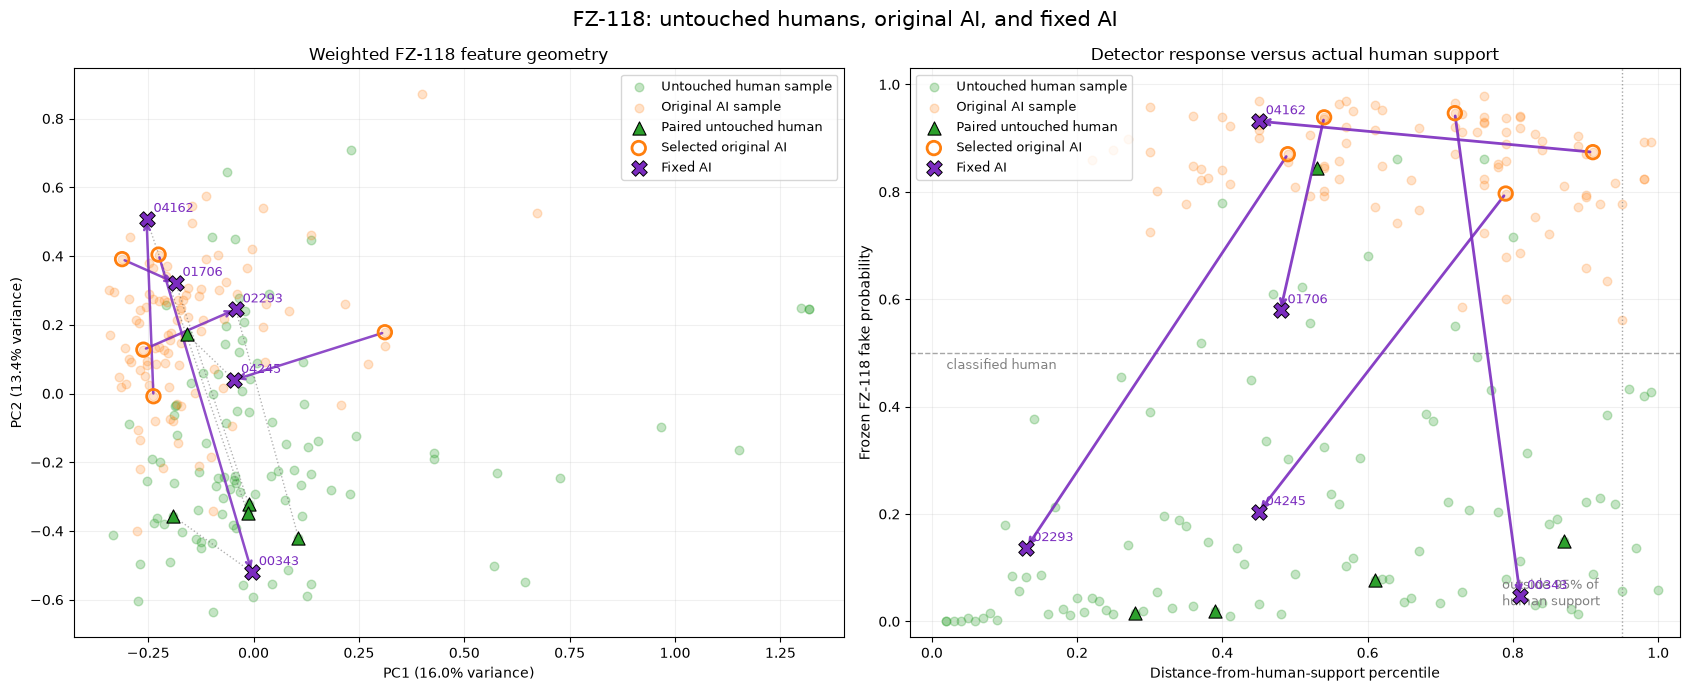

saved: ../results/causal/C02d_fz118_neutralization/fz118_human_ai_fixed_geometry_n5.png


In [39]:
# ============================================================
# FZ-118 — Human vs original AI vs fixed AI visualization
#
# Left:
#   2D PCA projection of all 118 weighted FZ features.
#
# Right:
#   Exact human-support percentile vs frozen detector score.
#
# Arrow direction:
#   circle = original AI
#   X      = fixed AI
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA


# ------------------------------------------------------------
# Reference populations
# ------------------------------------------------------------

background = original_features[
    original_features["fz_role"].eq(
        "controller_calibration"
    )
].copy()

background_human = background[
    background["label"].eq(0)
].copy()

background_ai = background[
    background["label"].eq(1)
].copy()

detector_train = original_features[
    original_features["fz_role"].eq(
        "detector_train"
    )
].copy()

X_background_human = background_human[
    FEATURE_NAMES
].to_numpy(float)

X_background_ai = background_ai[
    FEATURE_NAMES
].to_numpy(float)

X_detector_train = detector_train[
    FEATURE_NAMES
].to_numpy(float)

X_paired_human = paired_humans[
    FEATURE_NAMES
].to_numpy(float)


# ------------------------------------------------------------
# Use exactly the notebook's weighted FZ geometry
# ------------------------------------------------------------

viz_scale = np.where(
    np.asarray(human_scale, dtype=float) > 1e-10,
    np.asarray(human_scale, dtype=float),
    1.0,
)

viz_weights = np.asarray(
    coordinate_weights,
    dtype=float,
)

def weighted_fz_coordinates(X):
    return (
        (
            np.asarray(X, dtype=float)
            - np.asarray(human_median, dtype=float)
        )
        / viz_scale
    ) * np.sqrt(viz_weights)


# Fit PCA without looking at the five transformed texts.
pca = PCA(
    n_components=2,
    random_state=SEED,
)

pca.fit(
    weighted_fz_coordinates(
        X_detector_train
    )
)

P_human = pca.transform(
    weighted_fz_coordinates(
        X_background_human
    )
)

P_ai = pca.transform(
    weighted_fz_coordinates(
        X_background_ai
    )
)

P_original = pca.transform(
    weighted_fz_coordinates(
        X_original
    )
)

P_fixed = pca.transform(
    weighted_fz_coordinates(
        X_external
    )
)

P_paired_human = pca.transform(
    weighted_fz_coordinates(
        X_paired_human
    )
)


# ------------------------------------------------------------
# Human-support percentile
#
# Larger percentile = farther from ordinary human support.
# ------------------------------------------------------------

X_human_reference = human_reference[
    FEATURE_NAMES
].to_numpy(float)

def viz_knn_distance(X, k=5):
    distances = weighted_distance_matrix(
        X,
        X_human_reference,
    )

    k = min(k, distances.shape[1])

    nearest = np.partition(
        distances,
        kth=k - 1,
        axis=1,
    )[:, :k]

    return nearest.mean(axis=1)


human_reference_distance = viz_knn_distance(
    X_background_human
)

sorted_human_distance = np.sort(
    human_reference_distance
)

def anomaly_percentile(values):
    values = np.asarray(values, dtype=float)

    return np.searchsorted(
        sorted_human_distance,
        values,
        side="right",
    ) / len(sorted_human_distance)


human_percentile = anomaly_percentile(
    viz_knn_distance(
        X_background_human
    )
)

ai_percentile = anomaly_percentile(
    viz_knn_distance(
        X_background_ai
    )
)

original_percentile = anomaly_percentile(
    viz_knn_distance(
        X_original
    )
)

fixed_percentile = anomaly_percentile(
    viz_knn_distance(
        X_external
    )
)

paired_human_percentile = anomaly_percentile(
    viz_knn_distance(
        X_paired_human
    )
)


# ------------------------------------------------------------
# Detector probabilities
# ------------------------------------------------------------

human_probability = frozen_detector.predict_proba(
    X_background_human
)[:, 1]

ai_probability = frozen_detector.predict_proba(
    X_background_ai
)[:, 1]

paired_human_probability = frozen_detector.predict_proba(
    X_paired_human
)[:, 1]

original_probability_plot = frozen_detector.predict_proba(
    X_original
)[:, 1]

fixed_probability_plot = frozen_detector.predict_proba(
    X_external
)[:, 1]


# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    2,
    figsize=(17, 7),
)

human_color = "#2ca02c"
ai_color = "#ff7f0e"
fixed_color = "#7b2cbf"
pair_color = "#555555"


# ------------------------------------------------------------
# Panel 1: PCA feature geometry
# ------------------------------------------------------------

ax = axes[0]

ax.scatter(
    P_human[:, 0],
    P_human[:, 1],
    s=38,
    alpha=0.28,
    color=human_color,
    label="Untouched human sample",
)

ax.scatter(
    P_ai[:, 0],
    P_ai[:, 1],
    s=38,
    alpha=0.22,
    color=ai_color,
    label="Original AI sample",
)

# Highlight the five matched human references.
ax.scatter(
    P_paired_human[:, 0],
    P_paired_human[:, 1],
    s=90,
    marker="^",
    color=human_color,
    edgecolor="black",
    linewidth=0.8,
    label="Paired untouched human",
    zorder=5,
)

# Original-to-fixed arrows.
for i, source_id in enumerate(common_ids):
    ax.annotate(
        "",
        xy=(
            P_fixed[i, 0],
            P_fixed[i, 1],
        ),
        xytext=(
            P_original[i, 0],
            P_original[i, 1],
        ),
        arrowprops={
            "arrowstyle": "->",
            "color": fixed_color,
            "linewidth": 1.8,
            "alpha": 0.85,
        },
        zorder=4,
    )

    # Light connection from fixed text to its paired human.
    ax.plot(
        [
            P_fixed[i, 0],
            P_paired_human[i, 0],
        ],
        [
            P_fixed[i, 1],
            P_paired_human[i, 1],
        ],
        color=pair_color,
        linestyle=":",
        linewidth=1,
        alpha=0.45,
        zorder=2,
    )

ax.scatter(
    P_original[:, 0],
    P_original[:, 1],
    s=95,
    marker="o",
    facecolor="none",
    edgecolor=ai_color,
    linewidth=2,
    label="Selected original AI",
    zorder=6,
)

ax.scatter(
    P_fixed[:, 0],
    P_fixed[:, 1],
    s=125,
    marker="X",
    color=fixed_color,
    edgecolor="black",
    linewidth=0.7,
    label="Fixed AI",
    zorder=7,
)

for i, source_id in enumerate(common_ids):
    short_id = source_id.replace(
        "chatgpt_",
        "",
    )

    ax.annotate(
        short_id,
        (
            P_fixed[i, 0],
            P_fixed[i, 1],
        ),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=9,
        color=fixed_color,
        zorder=8,
    )

variance = (
    100
    * pca.explained_variance_ratio_
)

ax.set_xlabel(
    f"PC1 ({variance[0]:.1f}% variance)"
)

ax.set_ylabel(
    f"PC2 ({variance[1]:.1f}% variance)"
)

ax.set_title(
    "Weighted FZ-118 feature geometry"
)

ax.grid(
    alpha=0.18,
)

ax.legend(
    fontsize=9,
    loc="best",
)


# ------------------------------------------------------------
# Panel 2: exact support-score plane
#
# Ideal humanization moves down and left.
# ------------------------------------------------------------

ax = axes[1]

ax.scatter(
    human_percentile,
    human_probability,
    s=38,
    alpha=0.28,
    color=human_color,
    label="Untouched human sample",
)

ax.scatter(
    ai_percentile,
    ai_probability,
    s=38,
    alpha=0.22,
    color=ai_color,
    label="Original AI sample",
)

ax.scatter(
    paired_human_percentile,
    paired_human_probability,
    s=90,
    marker="^",
    color=human_color,
    edgecolor="black",
    linewidth=0.8,
    label="Paired untouched human",
    zorder=5,
)

for i, source_id in enumerate(common_ids):
    ax.annotate(
        "",
        xy=(
            fixed_percentile[i],
            fixed_probability_plot[i],
        ),
        xytext=(
            original_percentile[i],
            original_probability_plot[i],
        ),
        arrowprops={
            "arrowstyle": "->",
            "color": fixed_color,
            "linewidth": 2,
            "alpha": 0.9,
        },
        zorder=5,
    )

ax.scatter(
    original_percentile,
    original_probability_plot,
    s=95,
    marker="o",
    facecolor="none",
    edgecolor=ai_color,
    linewidth=2,
    label="Selected original AI",
    zorder=6,
)

ax.scatter(
    fixed_percentile,
    fixed_probability_plot,
    s=125,
    marker="X",
    color=fixed_color,
    edgecolor="black",
    linewidth=0.7,
    label="Fixed AI",
    zorder=7,
)

for i, source_id in enumerate(common_ids):
    short_id = source_id.replace(
        "chatgpt_",
        "",
    )

    ax.annotate(
        short_id,
        (
            fixed_percentile[i],
            fixed_probability_plot[i],
        ),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=9,
        color=fixed_color,
        zorder=8,
    )

ax.axhline(
    0.5,
    color="gray",
    linestyle="--",
    linewidth=1,
    alpha=0.7,
)

ax.axvline(
    0.95,
    color="gray",
    linestyle=":",
    linewidth=1,
    alpha=0.7,
)

ax.text(
    0.02,
    0.47,
    "classified human",
    fontsize=9,
    color="gray",
)

ax.text(
    0.785,
    0.03,
    "outside 95% of\nhuman support",
    fontsize=9,
    color="gray",
)

ax.set_xlim(
    -0.03,
    1.03,
)

ax.set_ylim(
    -0.03,
    1.03,
)

ax.set_xlabel(
    "Distance-from-human-support percentile"
)

ax.set_ylabel(
    "Frozen FZ-118 fake probability"
)

ax.set_title(
    "Detector response versus actual human support"
)

ax.grid(
    alpha=0.18,
)

ax.legend(
    fontsize=9,
    loc="best",
)


fig.suptitle(
    "FZ-118: untouched humans, original AI, and fixed AI",
    fontsize=15,
)

fig.tight_layout()

VIS_PATH = (
    OUT
    / f"fz118_human_ai_fixed_geometry_n{len(common_ids)}.png"
)

fig.savefig(
    VIS_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print("saved:", VIS_PATH)

Exact FZ-118 contributions: 100%|███████████████████████████████████████████████████████████████████████████████████| 600/600 [00:13<00:00, 45.25it/s]


maximum full-score reconstruction error: 1.110e-15

Selected detector components: 10 / 118
Held-out score R²: 0.99123
Full detector AUC: 0.9954
Component reconstruction AUC: 0.9948
Excess-AUC retention: 0.99879

LEADING DETECTOR-CONTRIBUTION COMPONENTS


,component,original_pca_index,detector_score_variance_share,cumulative_score_variance_share,human_mean,ai_mean,standardized_human_ai_gap,component_class_auc,detector_output_loading,mean_score_gap_contribution
0,DPC1,1,0.8278,0.8278,-0.0871,0.0871,1.7033,0.9772,3.7530,0.6536
1,DPC2,2,0.1079,0.9356,-0.0161,0.0161,0.6710,0.6907,2.8910,0.0929
2,DPC3,6,0.0179,0.9536,-0.0044,0.0044,0.4691,0.6043,2.9883,0.0265
3,DPC4,3,0.0151,0.9687,-0.0042,0.0042,0.2823,0.5764,1.7479,0.0146
4,DPC5,8,0.0105,0.9791,-0.0019,0.0019,0.2293,0.5426,2.5727,0.0099
5,DPC6,11,0.0045,0.9836,-0.0010,0.0010,0.1467,0.5506,2.0695,0.0041
6,DPC7,9,0.0042,0.9878,-0.0009,0.0009,0.1138,0.5468,1.7217,0.0031
7,DPC8,13,0.0020,0.9898,-0.0006,0.0006,0.1090,0.5179,1.6853,0.0020
8,DPC9,7,0.0017,0.9914,-0.0008,0.0008,0.0865,0.5056,0.9863,0.0015
9,DPC10,15,0.0015,0.9929,-0.0005,0.0005,0.0924,0.5349,1.6586,0.0015



FZ METRICS MOST ALIGNED WITH IMPORTANT DETECTOR COMPONENTS


,feature_index,feature,detector_component_priority,best_matching_component,best_absolute_association,pearson_with_best_component,spearman_with_best_component
0,0,n_characters,0.8980,DPC1,0.9484,-0.9347,-0.9484
2,2,n_words,0.8974,DPC1,0.9476,-0.9321,-0.9476
54,54,mean_paragraph_words,0.8974,DPC1,0.9476,-0.9321,-0.9476
1,1,n_syllables,0.8802,DPC1,0.9277,-0.9065,-0.9277
5,5,n_short_words,0.7611,DPC1,0.8025,-0.8025,-0.8015
4,4,n_difficult_words,0.7473,DPC1,0.7897,-0.7897,-0.7817
6,6,n_long_words,0.6901,DPC1,0.7189,-0.7109,-0.7189
3,3,n_sentences,0.6685,DPC1,0.6866,-0.4548,-0.6866
55,55,word_1gram_overlap_bin_0,0.5023,DPC2,0.7836,-0.7522,-0.7836
95,95,pos_2gram_overlap_bin_0,0.4781,DPC2,0.6934,-0.6510,-0.6934


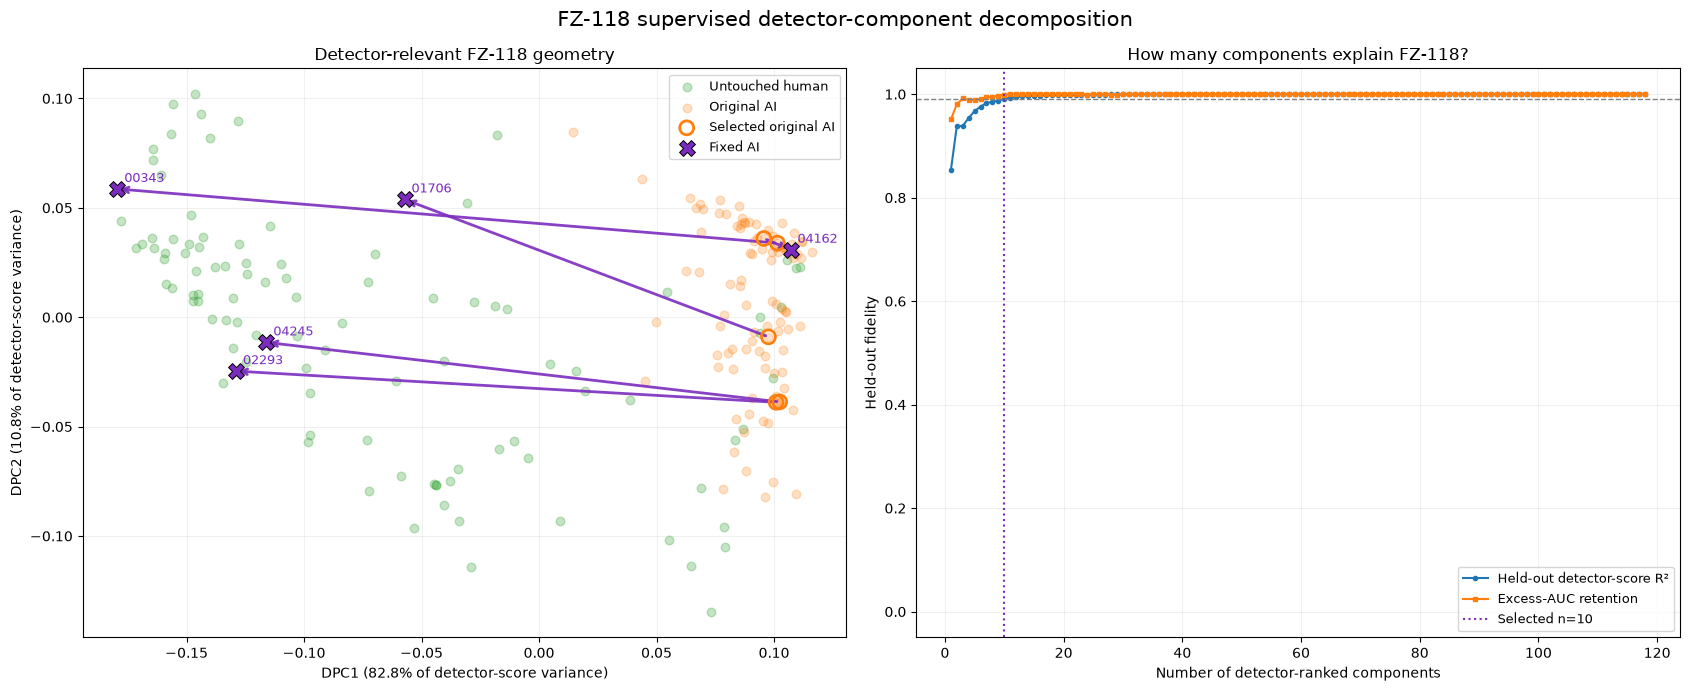

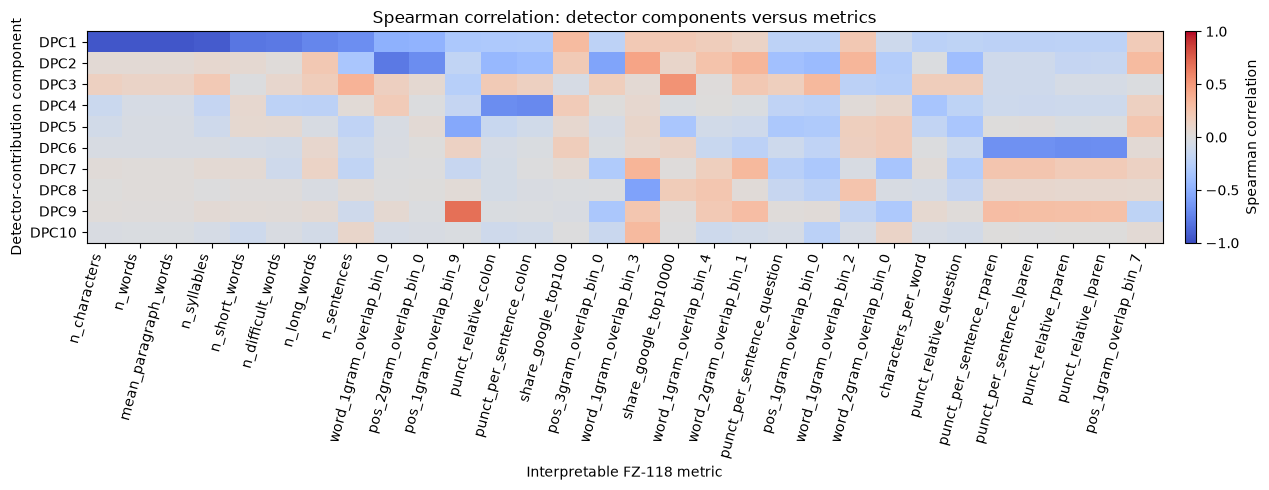


saved: ../results/causal/C02d_fz118_neutralization/fz118_detector_component_geometry.png
saved: ../results/causal/C02d_fz118_neutralization/fz118_detector_component_correlation_map.png
PASS: detector-component analysis complete.


In [40]:
# ============================================================
# FZ-118 — detector-contribution components
#
# Outputs:
# 1. Minimal component count retaining 99% of detector behavior
# 2. Human / AI / fixed-AI projection on leading components
# 3. Correlation map from components to all 118 FZ metrics
# 4. Cross-component metric priority ranking
#
# No text generation.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import rankdata
from sklearn.decomposition import PCA
from sklearn.metrics import (
    r2_score,
    roc_auc_score,
)
from tqdm.auto import tqdm


# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

SCORE_FIDELITY_TARGET = 0.99
AUC_FIDELITY_TARGET = 0.99

MAX_COMPONENTS_TO_DISPLAY = 20
MAX_COMPONENTS_IN_HEATMAP = 12
MAX_FEATURES_IN_HEATMAP = 30


# ------------------------------------------------------------
# Exact ExtraTrees path contributions with progress
#
# For every document:
#
# detector probability
# = mean root probability
# + sum of 118 feature contributions
# ------------------------------------------------------------

def forest_path_contributions_progress(
    forest,
    X,
):
    X = np.asarray(X, dtype=float)

    contributions = np.zeros(
        (
            len(X),
            X.shape[1],
        ),
        dtype=float,
    )

    root_probabilities = []

    for estimator in tqdm(
        forest.estimators_,
        desc="Exact FZ-118 contributions",
    ):
        tree = estimator.tree_
        values = np.asarray(tree.value)

        if values.ndim == 3:
            values = values[:, 0, :]

        classes = list(estimator.classes_)
        ai_class_index = classes.index(1)

        denominators = values.sum(axis=1)

        node_probability = np.divide(
            values[:, ai_class_index],
            denominators,
            out=np.zeros(
                len(values),
                dtype=float,
            ),
            where=denominators != 0,
        )

        root_probabilities.append(
            float(node_probability[0])
        )

        for row_index, x in enumerate(X):
            node = 0

            while (
                tree.children_left[node]
                != tree.children_right[node]
            ):
                feature_index = int(
                    tree.feature[node]
                )

                threshold = float(
                    tree.threshold[node]
                )

                if x[feature_index] <= threshold:
                    child = int(
                        tree.children_left[node]
                    )
                else:
                    child = int(
                        tree.children_right[node]
                    )

                contributions[
                    row_index,
                    feature_index,
                ] += (
                    node_probability[child]
                    - node_probability[node]
                )

                node = child

    contributions /= len(
        forest.estimators_
    )

    root_probability = float(
        np.mean(root_probabilities)
    )

    return root_probability, contributions


# ------------------------------------------------------------
# Assemble frozen train, validation, visualization, and fixed sets
# ------------------------------------------------------------

component_train = original_features[
    original_features["fz_role"].eq(
        "detector_train"
    )
].copy()

component_validation = original_features[
    original_features["fz_role"].eq(
        "detector_validation"
    )
].copy()

component_background = original_features[
    original_features["fz_role"].eq(
        "controller_calibration"
    )
].copy()

X_component_train = component_train[
    FEATURE_NAMES
].to_numpy(float)

X_component_validation = component_validation[
    FEATURE_NAMES
].to_numpy(float)

X_component_background = component_background[
    FEATURE_NAMES
].to_numpy(float)

y_component_train = component_train[
    "label"
].to_numpy(int)

y_component_validation = component_validation[
    "label"
].to_numpy(int)

y_component_background = component_background[
    "label"
].to_numpy(int)


# Compute everything in one forest pass.
X_contribution_all = np.vstack([
    X_component_train,
    X_component_validation,
    X_component_background,
    X_external,
])

root_probability, contribution_all = (
    forest_path_contributions_progress(
        frozen_detector,
        X_contribution_all,
    )
)

n_train = len(X_component_train)
n_validation = len(
    X_component_validation
)
n_background = len(
    X_component_background
)

train_end = n_train
validation_end = (
    train_end + n_validation
)
background_end = (
    validation_end + n_background
)

C_train = contribution_all[
    :train_end
]

C_validation = contribution_all[
    train_end:validation_end
]

C_background = contribution_all[
    validation_end:background_end
]

C_fixed = contribution_all[
    background_end:
]


# ------------------------------------------------------------
# Confirm exact detector reconstruction
# ------------------------------------------------------------

full_validation_probability = (
    frozen_detector.predict_proba(
        X_component_validation
    )[:, 1]
)

reconstructed_validation_probability = (
    root_probability
    + C_validation.sum(axis=1)
)

exact_error = float(
    np.max(
        np.abs(
            full_validation_probability
            - reconstructed_validation_probability
        )
    )
)

print(
    "maximum full-score reconstruction error:",
    f"{exact_error:.3e}",
)


# ------------------------------------------------------------
# PCA in detector-contribution space
#
# This is model-aware because each input coordinate is its
# contribution to the detector output, not its raw feature value.
# ------------------------------------------------------------

n_available_components = min(
    len(FEATURE_NAMES),
    len(C_train) - 1,
)

contribution_pca = PCA(
    n_components=n_available_components,
    svd_solver="full",
    random_state=SEED,
)

Z_train_unranked = (
    contribution_pca.fit_transform(
        C_train
    )
)

Z_validation_unranked = (
    contribution_pca.transform(
        C_validation
    )
)

Z_background_unranked = (
    contribution_pca.transform(
        C_background
    )
)

Z_fixed_unranked = (
    contribution_pca.transform(
        C_fixed
    )
)


# ------------------------------------------------------------
# Rank PCs by detector-score variance, not raw attribution variance
#
# Detector score contribution of PC k:
#
# z_k * sum(feature loadings of PC k)
# ------------------------------------------------------------

output_loading_unranked = (
    contribution_pca.components_.sum(
        axis=1
    )
)

score_variance_energy_unranked = (
    contribution_pca.explained_variance_
    * output_loading_unranked ** 2
)

rank_order = np.argsort(
    -score_variance_energy_unranked
)

score_variance_energy = (
    score_variance_energy_unranked[
        rank_order
    ]
)

total_score_energy = max(
    float(
        score_variance_energy.sum()
    ),
    1e-15,
)

score_variance_share = (
    score_variance_energy
    / total_score_energy
)

cumulative_score_variance_share = (
    np.cumsum(
        score_variance_share
    )
)

ranked_components = (
    contribution_pca.components_[
        rank_order
    ]
)

ranked_output_loading = (
    output_loading_unranked[
        rank_order
    ]
)

Z_train_ranked = (
    Z_train_unranked[
        :, rank_order
    ]
)

Z_validation_ranked = (
    Z_validation_unranked[
        :, rank_order
    ]
)

Z_background_ranked = (
    Z_background_unranked[
        :, rank_order
    ]
)

Z_fixed_ranked = (
    Z_fixed_unranked[
        :, rank_order
    ]
)


# ------------------------------------------------------------
# Orient every component so AI has the larger mean
#
# The sign of any PCA component is otherwise arbitrary.
# ------------------------------------------------------------

component_orientation = np.ones(
    n_available_components,
    dtype=float,
)

for k in range(
    n_available_components
):
    human_mean = Z_train_ranked[
        y_component_train == 0,
        k,
    ].mean()

    ai_mean = Z_train_ranked[
        y_component_train == 1,
        k,
    ].mean()

    if ai_mean < human_mean:
        component_orientation[k] = -1.0

Z_train_ranked *= component_orientation
Z_validation_ranked *= component_orientation
Z_background_ranked *= component_orientation
Z_fixed_ranked *= component_orientation

ranked_components *= (
    component_orientation[:, None]
)

ranked_output_loading *= (
    component_orientation
)


# ------------------------------------------------------------
# Held-out score and classification fidelity
#
# Reconstruct the original contribution vectors using the
# first n detector-ranked components.
# ------------------------------------------------------------

full_validation_auc = float(
    roc_auc_score(
        y_component_validation,
        full_validation_probability,
    )
)

fidelity_rows = []

for n_components in range(
    1,
    n_available_components + 1,
):
    selected = rank_order[
        :n_components
    ]

    reconstructed_contributions = (
        contribution_pca.mean_[None, :]
        + Z_validation_unranked[
            :, selected
        ]
        @ contribution_pca.components_[
            selected
        ]
    )

    reconstructed_score = (
        root_probability
        + reconstructed_contributions.sum(
            axis=1
        )
    )

    score_r2 = float(
        r2_score(
            full_validation_probability,
            reconstructed_score,
        )
    )

    component_auc = float(
        roc_auc_score(
            y_component_validation,
            reconstructed_score,
        )
    )

    excess_auc_retention = float(
        (
            component_auc - 0.5
        )
        / max(
            full_validation_auc - 0.5,
            1e-12,
        )
    )

    fidelity_rows.append({
        "n_components":
            n_components,
        "cumulative_detector_score_variance":
            cumulative_score_variance_share[
                n_components - 1
            ],
        "heldout_score_r2":
            score_r2,
        "heldout_auc":
            component_auc,
        "excess_auc_retention":
            excess_auc_retention,
    })

component_fidelity = pd.DataFrame(
    fidelity_rows
)

passing_rows = component_fidelity[
    component_fidelity[
        "heldout_score_r2"
    ].ge(SCORE_FIDELITY_TARGET)
    & component_fidelity[
        "excess_auc_retention"
    ].ge(AUC_FIDELITY_TARGET)
]

if len(passing_rows):
    N_SELECTED_COMPONENTS = int(
        passing_rows.iloc[0][
            "n_components"
        ]
    )
else:
    N_SELECTED_COMPONENTS = (
        n_available_components
    )

selected_fidelity = (
    component_fidelity[
        component_fidelity[
            "n_components"
        ].eq(N_SELECTED_COMPONENTS)
    ]
    .iloc[0]
)

print(
    "\nSelected detector components:",
    N_SELECTED_COMPONENTS,
    "/",
    n_available_components,
)

print(
    "Held-out score R²:",
    round(
        float(
            selected_fidelity[
                "heldout_score_r2"
            ]
        ),
        5,
    ),
)

print(
    "Full detector AUC:",
    round(
        full_validation_auc,
        5,
    ),
)

print(
    "Component reconstruction AUC:",
    round(
        float(
            selected_fidelity[
                "heldout_auc"
            ]
        ),
        5,
    ),
)

print(
    "Excess-AUC retention:",
    round(
        float(
            selected_fidelity[
                "excess_auc_retention"
            ]
        ),
        5,
    ),
)


# ------------------------------------------------------------
# Component class gaps and component summary
# ------------------------------------------------------------

component_rows = []

for k in range(
    N_SELECTED_COMPONENTS
):
    values = Z_train_ranked[:, k]

    human_values = values[
        y_component_train == 0
    ]

    ai_values = values[
        y_component_train == 1
    ]

    overall_sd = max(
        float(
            values.std(ddof=1)
        ),
        1e-12,
    )

    standardized_gap = float(
        (
            ai_values.mean()
            - human_values.mean()
        )
        / overall_sd
    )

    component_auc = float(
        roc_auc_score(
            y_component_train,
            values,
        )
    )

    mean_score_gap_contribution = float(
        (
            ai_values.mean()
            - human_values.mean()
        )
        * ranked_output_loading[k]
    )

    component_rows.append({
        "component":
            f"DPC{k + 1}",
        "original_pca_index":
            int(rank_order[k] + 1),
        "detector_score_variance_share":
            score_variance_share[k],
        "cumulative_score_variance_share":
            cumulative_score_variance_share[k],
        "human_mean":
            float(human_values.mean()),
        "ai_mean":
            float(ai_values.mean()),
        "standardized_human_ai_gap":
            standardized_gap,
        "component_class_auc":
            component_auc,
        "detector_output_loading":
            float(
                ranked_output_loading[k]
            ),
        "mean_score_gap_contribution":
            mean_score_gap_contribution,
    })

component_summary = pd.DataFrame(
    component_rows
)

print(
    "\nLEADING DETECTOR-CONTRIBUTION COMPONENTS"
)

display(
    component_summary.head(
        MAX_COMPONENTS_TO_DISPLAY
    ).round(4)
)


# ------------------------------------------------------------
# Correlate detector components with all raw FZ metrics
#
# Pearson  = linear association
# Spearman = monotonic association
# ------------------------------------------------------------

def standardized_columns(matrix):
    matrix = np.asarray(
        matrix,
        dtype=float,
    )

    means = matrix.mean(
        axis=0,
        keepdims=True,
    )

    standard_deviations = matrix.std(
        axis=0,
        ddof=1,
        keepdims=True,
    )

    standard_deviations = np.where(
        standard_deviations > 1e-12,
        standard_deviations,
        1.0,
    )

    return (
        matrix - means
    ) / standard_deviations


Z_selected_train = Z_train_ranked[
    :, :N_SELECTED_COMPONENTS
]

X_metric_train = X_component_train

pearson_correlation = (
    standardized_columns(
        Z_selected_train
    ).T
    @ standardized_columns(
        X_metric_train
    )
    / max(
        len(X_metric_train) - 1,
        1,
    )
)

ranked_component_values = rankdata(
    Z_selected_train,
    axis=0,
)

ranked_metric_values = rankdata(
    X_metric_train,
    axis=0,
)

spearman_correlation = (
    standardized_columns(
        ranked_component_values
    ).T
    @ standardized_columns(
        ranked_metric_values
    )
    / max(
        len(X_metric_train) - 1,
        1,
    )
)

association_strength = np.maximum(
    np.abs(
        pearson_correlation
    ),
    np.abs(
        spearman_correlation
    ),
)


# ------------------------------------------------------------
# Cross-component metric priority
#
# A feature receives high priority when it:
# - tracks important detector-score components, and
# - tracks components with a large human–AI gap.
# ------------------------------------------------------------

component_gap_strength = (
    component_summary[
        "standardized_human_ai_gap"
    ]
    .abs()
    .to_numpy(float)
)

selected_score_weight = (
    score_variance_share[
        :N_SELECTED_COMPONENTS
    ]
)

combined_component_weight = (
    selected_score_weight
    * component_gap_strength
)

combined_component_weight /= max(
    combined_component_weight.sum(),
    1e-12,
)

metric_priority_score = (
    combined_component_weight
    @ association_strength
)

best_component_index = (
    association_strength.argmax(
        axis=0
    )
)

feature_priority = pd.DataFrame({
    "feature_index":
        np.arange(len(FEATURE_NAMES)),
    "feature":
        FEATURE_NAMES,
    "detector_component_priority":
        metric_priority_score,
    "best_matching_component": [
        f"DPC{i + 1}"
        for i in best_component_index
    ],
    "best_absolute_association": [
        association_strength[
            best_component_index[j],
            j,
        ]
        for j in range(
            len(FEATURE_NAMES)
        )
    ],
    "pearson_with_best_component": [
        pearson_correlation[
            best_component_index[j],
            j,
        ]
        for j in range(
            len(FEATURE_NAMES)
        )
    ],
    "spearman_with_best_component": [
        spearman_correlation[
            best_component_index[j],
            j,
        ]
        for j in range(
            len(FEATURE_NAMES)
        )
    ],
}).sort_values(
    "detector_component_priority",
    ascending=False,
)

print(
    "\nFZ METRICS MOST ALIGNED WITH "
    "IMPORTANT DETECTOR COMPONENTS"
)

display(
    feature_priority.head(30).round(4)
)


# Full long-form correlation table.
correlation_rows = []

for k in range(
    N_SELECTED_COMPONENTS
):
    for feature_index, feature in enumerate(
        FEATURE_NAMES
    ):
        correlation_rows.append({
            "component":
                f"DPC{k + 1}",
            "feature_index":
                feature_index,
            "feature":
                feature,
            "pearson":
                float(
                    pearson_correlation[
                        k,
                        feature_index,
                    ]
                ),
            "spearman":
                float(
                    spearman_correlation[
                        k,
                        feature_index,
                    ]
                ),
            "maximum_absolute_association":
                float(
                    association_strength[
                        k,
                        feature_index,
                    ]
                ),
            "component_weight":
                float(
                    combined_component_weight[k]
                ),
        })

component_feature_correlations = (
    pd.DataFrame(
        correlation_rows
    )
)


# ------------------------------------------------------------
# Locate the five originals inside the background population
# ------------------------------------------------------------

background_source_ids = (
    component_background[
        "source_id"
    ]
    .astype(str)
    .tolist()
)

background_source_lookup = {
    source_id: i
    for i, source_id in enumerate(
        background_source_ids
    )
}

missing_originals = [
    source_id
    for source_id in common_ids
    if source_id not in background_source_lookup
]

if missing_originals:
    raise RuntimeError(
        "These completed cases were not found in the "
        "controller-calibration background: "
        f"{missing_originals}"
    )

selected_original_indices = [
    background_source_lookup[
        source_id
    ]
    for source_id in common_ids
]

Z_selected_original = (
    Z_background_ranked[
        selected_original_indices
    ]
)


# ------------------------------------------------------------
# Figure 1:
# Detector-relevant geometry and fidelity curve
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    2,
    figsize=(17, 7),
)

human_mask = (
    y_component_background == 0
)

ai_mask = (
    y_component_background == 1
)

ax = axes[0]

ax.scatter(
    Z_background_ranked[
        human_mask,
        0,
    ],
    Z_background_ranked[
        human_mask,
        1,
    ],
    s=38,
    alpha=0.28,
    color="#2ca02c",
    label="Untouched human",
)

ax.scatter(
    Z_background_ranked[
        ai_mask,
        0,
    ],
    Z_background_ranked[
        ai_mask,
        1,
    ],
    s=38,
    alpha=0.24,
    color="#ff7f0e",
    label="Original AI",
)

for i, source_id in enumerate(
    common_ids
):
    ax.annotate(
        "",
        xy=(
            Z_fixed_ranked[i, 0],
            Z_fixed_ranked[i, 1],
        ),
        xytext=(
            Z_selected_original[i, 0],
            Z_selected_original[i, 1],
        ),
        arrowprops={
            "arrowstyle": "->",
            "color": "#7b2cbf",
            "linewidth": 2,
            "alpha": 0.9,
        },
        zorder=5,
    )

ax.scatter(
    Z_selected_original[:, 0],
    Z_selected_original[:, 1],
    s=100,
    marker="o",
    facecolor="none",
    edgecolor="#ff7f0e",
    linewidth=2,
    label="Selected original AI",
    zorder=6,
)

ax.scatter(
    Z_fixed_ranked[:, 0],
    Z_fixed_ranked[:, 1],
    s=130,
    marker="X",
    color="#7b2cbf",
    edgecolor="black",
    linewidth=0.7,
    label="Fixed AI",
    zorder=7,
)

for i, source_id in enumerate(
    common_ids
):
    ax.annotate(
        source_id.replace(
            "chatgpt_",
            "",
        ),
        (
            Z_fixed_ranked[i, 0],
            Z_fixed_ranked[i, 1],
        ),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=9,
        color="#7b2cbf",
    )

ax.set_xlabel(
    "DPC1 "
    f"({100 * score_variance_share[0]:.1f}% "
    "of detector-score variance)"
)

ax.set_ylabel(
    "DPC2 "
    f"({100 * score_variance_share[1]:.1f}% "
    "of detector-score variance)"
)

ax.set_title(
    "Detector-relevant FZ-118 geometry"
)

ax.grid(alpha=0.18)
ax.legend(fontsize=9)


ax = axes[1]

ax.plot(
    component_fidelity[
        "n_components"
    ],
    component_fidelity[
        "heldout_score_r2"
    ],
    marker="o",
    markersize=3,
    linewidth=1.5,
    label="Held-out detector-score R²",
)

ax.plot(
    component_fidelity[
        "n_components"
    ],
    component_fidelity[
        "excess_auc_retention"
    ],
    marker="s",
    markersize=3,
    linewidth=1.5,
    label="Excess-AUC retention",
)

ax.axhline(
    0.99,
    color="gray",
    linestyle="--",
    linewidth=1,
)

ax.axvline(
    N_SELECTED_COMPONENTS,
    color="#7b2cbf",
    linestyle=":",
    linewidth=1.5,
    label=(
        f"Selected n={N_SELECTED_COMPONENTS}"
    ),
)

ax.set_ylim(
    min(
        -0.05,
        float(
            component_fidelity[
                [
                    "heldout_score_r2",
                    "excess_auc_retention",
                ]
            ].min().min()
        ),
    ),
    1.05,
)

ax.set_xlabel(
    "Number of detector-ranked components"
)

ax.set_ylabel(
    "Held-out fidelity"
)

ax.set_title(
    "How many components explain FZ-118?"
)

ax.grid(alpha=0.18)
ax.legend(fontsize=9)

fig.suptitle(
    "FZ-118 supervised detector-component decomposition",
    fontsize=15,
)

fig.tight_layout()

COMPONENT_FIGURE_PATH = (
    OUT
    / "fz118_detector_component_geometry.png"
)

fig.savefig(
    COMPONENT_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()


# ------------------------------------------------------------
# Figure 2:
# Correlation heatmap from leading DPCs to FZ metrics
# ------------------------------------------------------------

heat_component_count = min(
    N_SELECTED_COMPONENTS,
    MAX_COMPONENTS_IN_HEATMAP,
)

top_feature_indices = (
    feature_priority.head(
        MAX_FEATURES_IN_HEATMAP
    )[
        "feature_index"
    ]
    .to_numpy(int)
)

heat_values = spearman_correlation[
    :heat_component_count,
    :
][
    :,
    top_feature_indices,
]

fig_width = max(
    13,
    0.43 * len(
        top_feature_indices
    ),
)

fig_height = max(
    5,
    0.48 * heat_component_count,
)

fig, ax = plt.subplots(
    figsize=(
        fig_width,
        fig_height,
    )
)

image = ax.imshow(
    heat_values,
    aspect="auto",
    interpolation="nearest",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
)

ax.set_xticks(
    np.arange(
        len(top_feature_indices)
    )
)

ax.set_xticklabels(
    [
        FEATURE_NAMES[i]
        for i in top_feature_indices
    ],
    rotation=75,
    ha="right",
)

ax.set_yticks(
    np.arange(
        heat_component_count
    )
)

ax.set_yticklabels(
    [
        f"DPC{k + 1}"
        for k in range(
            heat_component_count
        )
    ]
)

ax.set_xlabel(
    "Interpretable FZ-118 metric"
)

ax.set_ylabel(
    "Detector-contribution component"
)

ax.set_title(
    "Spearman correlation: detector components versus metrics"
)

colorbar = fig.colorbar(
    image,
    ax=ax,
    fraction=0.025,
    pad=0.02,
)

colorbar.set_label(
    "Spearman correlation"
)

fig.tight_layout()

CORRELATION_FIGURE_PATH = (
    OUT
    / "fz118_detector_component_correlation_map.png"
)

fig.savefig(
    CORRELATION_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()


# ------------------------------------------------------------
# Save complete numerical results
# ------------------------------------------------------------

component_fidelity.to_csv(
    OUT
    / "fz118_detector_component_fidelity.csv",
    index=False,
)

component_summary.to_csv(
    OUT
    / "fz118_detector_component_summary.csv",
    index=False,
)

component_feature_correlations.to_csv(
    OUT
    / "fz118_detector_component_feature_correlations.csv",
    index=False,
)

feature_priority.to_csv(
    OUT
    / "fz118_detector_component_feature_priority.csv",
    index=False,
)

print("\nsaved:", COMPONENT_FIGURE_PATH)
print("saved:", CORRELATION_FIGURE_PATH)
print(
    "PASS: detector-component analysis complete."
)

PER-DOCUMENT DETECTOR-COMPONENT RESULT


,source_id,components_in_human_band_before,components_in_human_band_after,detector_weight_in_human_band_after,weighted_outside_severity_before,weighted_outside_severity_after,weighted_outside_severity_change,components_entering_human_band,components_worsened,components_overshot,selected_components_score_change,actual_frozen_score_change,original_fake_probability,fixed_fake_probability
0,chatgpt_00343,9,9,0.1663,0.4412,0.4412,0.0000,0,1,1,-0.8628,-0.8993,0.9465,0.0472
1,chatgpt_01706,8,9,0.9985,0.2673,0.0005,-0.2668,2,1,0,-0.3614,-0.3592,0.9387,0.5795
2,chatgpt_02293,9,9,0.9848,0.4412,0.0142,-0.4270,1,1,0,-0.7531,-0.7335,0.8701,0.1366
3,chatgpt_04162,8,8,0.1648,0.2677,0.7795,0.5118,0,1,0,0.0520,0.0577,0.8739,0.9315
4,chatgpt_04245,8,9,0.9895,0.4426,0.0034,-0.4392,2,1,0,-0.6560,-0.5932,0.7968,0.2036



UNRESOLVED COMPONENTS, RANKED BY DETECTOR IMPORTANCE


,component,detector_score_variance_share,component_class_auc,mean_human_percentile_before,mean_human_percentile_after,outside_band_rate_before,outside_band_rate_after,high_ai_tail_rate_after,low_overshoot_rate_after,mean_outside_severity_before,mean_outside_severity_after,mean_outside_severity_change,mean_detector_score_contribution_change,unresolved_priority
0,DPC1,0.8337,0.9772,0.9812,0.5277,1.0,0.4,0.2,0.2,0.4453,0.2927,-0.1525,-0.6550,0.2440
3,DPC4,0.0152,0.5764,0.6267,0.6010,0.0,0.2,0.2,0.0,0.0000,0.1869,0.1869,-0.0005,0.0028
4,DPC5,0.0105,0.5426,0.4921,0.6069,0.0,0.2,0.2,0.0,0.0000,0.0639,0.0639,0.0130,0.0007
9,DPC10,0.0015,0.5349,0.3970,0.5040,0.2,0.4,0.2,0.2,0.1869,0.1277,-0.0591,0.0127,0.0002
1,DPC2,0.1086,0.6907,0.5693,0.7178,0.0,0.0,0.0,0.0,0.0000,0.0000,0.0000,0.0717,0.0000
2,DPC3,0.0181,0.6043,0.2505,0.6188,0.0,0.0,0.0,0.0,0.0000,0.0000,0.0000,0.0522,0.0000
5,DPC6,0.0045,0.5506,0.7416,0.7059,0.2,0.0,0.0,0.0,0.0639,0.0000,-0.0639,-0.0082,0.0000
6,DPC7,0.0042,0.5468,0.4485,0.4525,0.0,0.0,0.0,0.0,0.0000,0.0000,0.0000,0.0026,0.0000
7,DPC8,0.0020,0.5179,0.4564,0.7653,0.2,0.0,0.0,0.0,0.1058,0.0000,-0.1058,0.0156,0.0000
8,DPC9,0.0017,0.5056,0.6228,0.1812,0.0,0.0,0.0,0.0,0.0000,0.0000,0.0000,-0.0202,0.0000


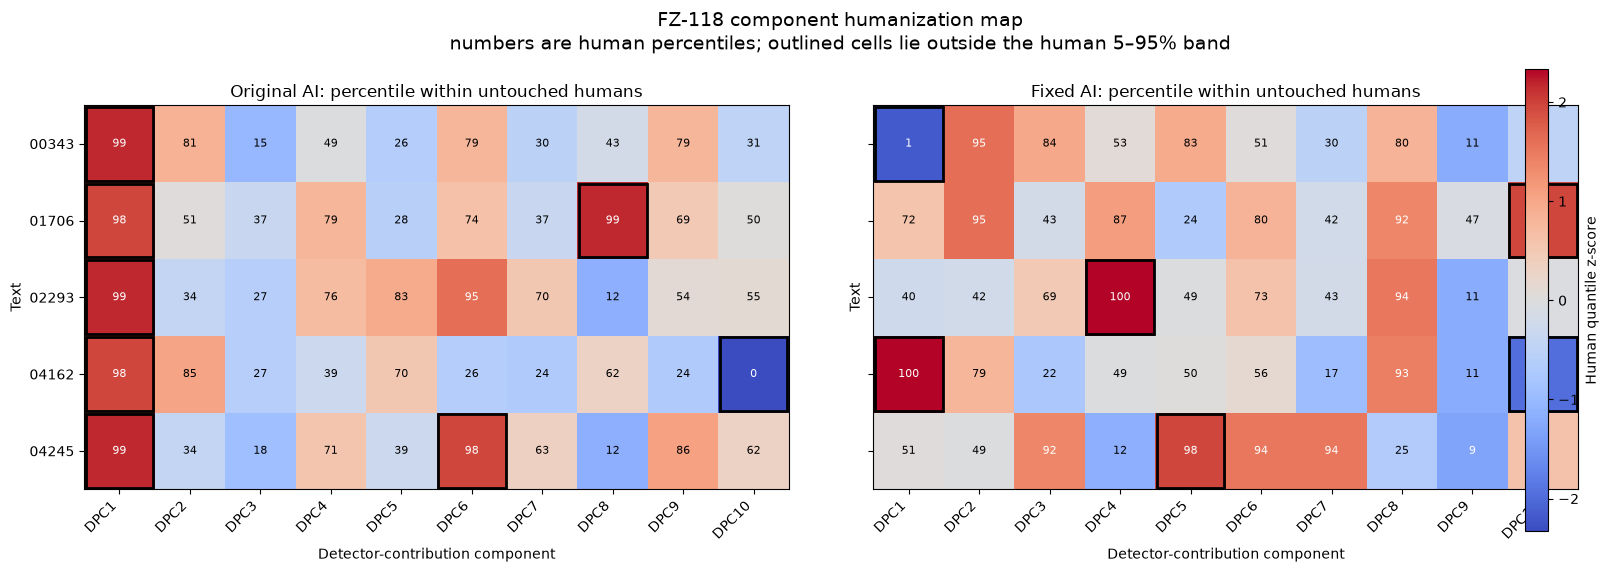


COMPONENT STATUS MAP


component,DPC1,DPC2,DPC3,DPC4,DPC5,DPC6,DPC7,DPC8,DPC9,DPC10
source_id,,,,,,,,,,
chatgpt_00343,overshot_human_band,remained_in_band,remained_in_band,remained_in_band,remained_in_band,remained_in_band,remained_in_band,remained_in_band,remained_in_band,remained_in_band
chatgpt_01706,entered_human_band,remained_in_band,remained_in_band,remained_in_band,remained_in_band,remained_in_band,remained_in_band,entered_human_band,remained_in_band,worsened
chatgpt_02293,entered_human_band,remained_in_band,remained_in_band,worsened,remained_in_band,remained_in_band,remained_in_band,remained_in_band,remained_in_band,remained_in_band
chatgpt_04162,worsened,remained_in_band,remained_in_band,remained_in_band,remained_in_band,remained_in_band,remained_in_band,remained_in_band,remained_in_band,closer_but_outside
chatgpt_04245,entered_human_band,remained_in_band,remained_in_band,remained_in_band,worsened,entered_human_band,remained_in_band,remained_in_band,remained_in_band,remained_in_band



saved: ../results/causal/C02d_fz118_neutralization/fz118_five_case_component_passmap.png
PASS: five-by-ten component audit complete.


In [41]:
# ============================================================
# FZ-118 — five-by-ten detector-component pass map
#
# For each original/fixed text and DPC:
# - empirical percentile within held-out untouched humans;
# - whether it lies inside the human 5–95% band;
# - whether rewriting moved it closer, worsened it, or overshot;
# - contribution of that component to the detector-score change.
#
# No generation and no model inference beyond cached/fitted FZ.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.patches import Rectangle
from scipy.stats import norm


# ------------------------------------------------------------
# Inputs
# ------------------------------------------------------------

N_AUDIT_COMPONENTS = min(
    N_SELECTED_COMPONENTS,
    10,
)

component_names = [
    f"DPC{k + 1}"
    for k in range(
        N_AUDIT_COMPONENTS
    )
]

human_component_reference = (
    Z_validation_ranked[
        y_component_validation == 0,
        :N_AUDIT_COMPONENTS,
    ]
)

original_component_values = (
    Z_selected_original[
        :,
        :N_AUDIT_COMPONENTS,
    ]
)

fixed_component_values = (
    Z_fixed_ranked[
        :,
        :N_AUDIT_COMPONENTS,
    ]
)


# ------------------------------------------------------------
# Empirical percentile relative to untouched held-out humans
#
# Components were oriented so larger values are AI-associated.
#
# High percentile: AI-side human tail.
# Low percentile: possible overshoot.
# ------------------------------------------------------------

def component_percentiles(
    values,
    reference,
):
    values = np.asarray(
        values,
        dtype=float,
    )

    percentiles = np.zeros_like(
        values,
        dtype=float,
    )

    for k in range(
        values.shape[1]
    ):
        ordered = np.sort(
            reference[:, k]
        )

        ranks = np.searchsorted(
            ordered,
            values[:, k],
            side="right",
        )

        # Smoothed empirical percentile:
        # avoids exact zero and one.
        percentiles[:, k] = (
            ranks + 0.5
        ) / (
            len(ordered) + 1.0
        )

    return percentiles


original_percentile = component_percentiles(
    original_component_values,
    human_component_reference,
)

fixed_percentile = component_percentiles(
    fixed_component_values,
    human_component_reference,
)

original_in_band = (
    (original_percentile >= 0.05)
    & (original_percentile <= 0.95)
)

fixed_in_band = (
    (fixed_percentile >= 0.05)
    & (fixed_percentile <= 0.95)
)


# ------------------------------------------------------------
# Distance outside the human band
#
# Zero means inside the human 5–95% interval.
# Positive means increasingly outside it.
# ------------------------------------------------------------

human_band_z = float(
    norm.ppf(0.95)
)

def outside_band_severity(
    percentiles,
):
    quantile_z = norm.ppf(
        np.clip(
            percentiles,
            1e-5,
            1 - 1e-5,
        )
    )

    return np.maximum(
        0.0,
        np.abs(quantile_z)
        - human_band_z,
    )


original_outside_severity = (
    outside_band_severity(
        original_percentile
    )
)

fixed_outside_severity = (
    outside_band_severity(
        fixed_percentile
    )
)

outside_severity_change = (
    fixed_outside_severity
    - original_outside_severity
)


# ------------------------------------------------------------
# Per-cell status
# ------------------------------------------------------------

status = np.empty(
    (
        len(common_ids),
        N_AUDIT_COMPONENTS,
    ),
    dtype=object,
)

for i in range(
    len(common_ids)
):
    for k in range(
        N_AUDIT_COMPONENTS
    ):
        if fixed_in_band[i, k]:
            if original_in_band[i, k]:
                status[i, k] = "remained_in_band"
            else:
                status[i, k] = "entered_human_band"

        elif (
            fixed_percentile[i, k] < 0.05
            and original_percentile[i, k] > 0.95
        ):
            status[i, k] = "overshot_human_band"

        elif (
            fixed_outside_severity[i, k]
            < original_outside_severity[i, k]
        ):
            status[i, k] = "closer_but_outside"

        elif (
            fixed_outside_severity[i, k]
            > original_outside_severity[i, k]
        ):
            status[i, k] = "worsened"

        else:
            status[i, k] = "unchanged_outside"


# ------------------------------------------------------------
# Component-level detector-score contributions
# ------------------------------------------------------------

component_score_change = (
    (
        fixed_component_values
        - original_component_values
    )
    * ranked_output_loading[
        :N_AUDIT_COMPONENTS
    ][None, :]
)

selected_component_weights = (
    score_variance_share[
        :N_AUDIT_COMPONENTS
    ]
)

selected_component_weights /= max(
    selected_component_weights.sum(),
    1e-12,
)


# ------------------------------------------------------------
# Long-form per-text/per-component table
# ------------------------------------------------------------

component_case_rows = []

for i, source_id in enumerate(
    common_ids
):
    for k, component_name in enumerate(
        component_names
    ):
        component_case_rows.append({
            "source_id":
                source_id,
            "component":
                component_name,

            "component_detector_weight":
                selected_component_weights[k],

            "original_value":
                original_component_values[i, k],
            "fixed_value":
                fixed_component_values[i, k],

            "original_human_percentile":
                original_percentile[i, k],
            "fixed_human_percentile":
                fixed_percentile[i, k],

            "original_in_human_5_95_band":
                bool(
                    original_in_band[i, k]
                ),
            "fixed_in_human_5_95_band":
                bool(
                    fixed_in_band[i, k]
                ),

            "outside_severity_before":
                original_outside_severity[i, k],
            "outside_severity_after":
                fixed_outside_severity[i, k],
            "outside_severity_change":
                outside_severity_change[i, k],

            "detector_score_contribution_change":
                component_score_change[i, k],

            "status":
                status[i, k],
        })

component_case_audit = pd.DataFrame(
    component_case_rows
)


# ------------------------------------------------------------
# Per-document summary
# ------------------------------------------------------------

document_component_rows = []

for i, source_id in enumerate(
    common_ids
):
    weighted_outside_before = float(
        np.sum(
            selected_component_weights
            * original_outside_severity[i]
        )
    )

    weighted_outside_after = float(
        np.sum(
            selected_component_weights
            * fixed_outside_severity[i]
        )
    )

    weighted_band_coverage = float(
        np.sum(
            selected_component_weights
            * fixed_in_band[i]
        )
    )

    document_component_rows.append({
        "source_id":
            source_id,

        "components_in_human_band_before":
            int(
                original_in_band[i].sum()
            ),

        "components_in_human_band_after":
            int(
                fixed_in_band[i].sum()
            ),

        "detector_weight_in_human_band_after":
            weighted_band_coverage,

        "weighted_outside_severity_before":
            weighted_outside_before,

        "weighted_outside_severity_after":
            weighted_outside_after,

        "weighted_outside_severity_change":
            (
                weighted_outside_after
                - weighted_outside_before
            ),

        "components_entering_human_band":
            int(
                (
                    (~original_in_band[i])
                    & fixed_in_band[i]
                ).sum()
            ),

        "components_worsened":
            int(
                (
                    outside_severity_change[i]
                    > 0
                ).sum()
            ),

        "components_overshot":
            int(
                (
                    (
                        fixed_percentile[i] < 0.05
                    )
                    & (
                        original_percentile[i] > 0.95
                    )
                ).sum()
            ),

        "selected_components_score_change":
            float(
                component_score_change[i].sum()
            ),

        "actual_frozen_score_change":
            float(
                external_probability[i]
                - original_probability[i]
            ),

        "original_fake_probability":
            float(
                original_probability[i]
            ),

        "fixed_fake_probability":
            float(
                external_probability[i]
            ),
    })

document_component_summary = pd.DataFrame(
    document_component_rows
)

print(
    "PER-DOCUMENT DETECTOR-COMPONENT RESULT"
)

display(
    document_component_summary.round(4)
)


# ------------------------------------------------------------
# Per-component unresolved ranking
# ------------------------------------------------------------

component_resolution_rows = []

for k, component_name in enumerate(
    component_names
):
    mean_before = float(
        original_outside_severity[
            :, k
        ].mean()
    )

    mean_after = float(
        fixed_outside_severity[
            :, k
        ].mean()
    )

    component_resolution_rows.append({
        "component":
            component_name,

        "detector_score_variance_share":
            score_variance_share[k],

        "component_class_auc":
            float(
                component_summary.iloc[k][
                    "component_class_auc"
                ]
            ),

        "mean_human_percentile_before":
            float(
                original_percentile[
                    :, k
                ].mean()
            ),

        "mean_human_percentile_after":
            float(
                fixed_percentile[
                    :, k
                ].mean()
            ),

        "outside_band_rate_before":
            float(
                (
                    ~original_in_band[
                        :, k
                    ]
                ).mean()
            ),

        "outside_band_rate_after":
            float(
                (
                    ~fixed_in_band[
                        :, k
                    ]
                ).mean()
            ),

        "high_ai_tail_rate_after":
            float(
                (
                    fixed_percentile[
                        :, k
                    ] > 0.95
                ).mean()
            ),

        "low_overshoot_rate_after":
            float(
                (
                    fixed_percentile[
                        :, k
                    ] < 0.05
                ).mean()
            ),

        "mean_outside_severity_before":
            mean_before,

        "mean_outside_severity_after":
            mean_after,

        "mean_outside_severity_change":
            mean_after - mean_before,

        "mean_detector_score_contribution_change":
            float(
                component_score_change[
                    :, k
                ].mean()
            ),

        "unresolved_priority":
            float(
                selected_component_weights[k]
                * mean_after
            ),
    })

component_resolution = (
    pd.DataFrame(
        component_resolution_rows
    )
    .sort_values(
        "unresolved_priority",
        ascending=False,
    )
)

print(
    "\nUNRESOLVED COMPONENTS, "
    "RANKED BY DETECTOR IMPORTANCE"
)

display(
    component_resolution.round(4)
)


# ------------------------------------------------------------
# Heatmaps
#
# Cell text = percentile within untouched humans.
#
# Blue: lower human tail.
# White: human center.
# Red: AI-side human tail.
# Black cell border: outside human 5–95% band.
# ------------------------------------------------------------

def percentile_heatmap(
    ax,
    percentiles,
    in_band,
    title,
):
    quantile_values = norm.ppf(
        np.clip(
            percentiles,
            0.01,
            0.99,
        )
    )

    image = ax.imshow(
        quantile_values,
        aspect="auto",
        cmap="coolwarm",
        vmin=-2.33,
        vmax=2.33,
        interpolation="nearest",
    )

    ax.set_xticks(
        np.arange(
            N_AUDIT_COMPONENTS
        )
    )

    ax.set_xticklabels(
        component_names,
        rotation=45,
        ha="right",
    )

    ax.set_yticks(
        np.arange(
            len(common_ids)
        )
    )

    ax.set_yticklabels([
        source_id.replace(
            "chatgpt_",
            "",
        )
        for source_id in common_ids
    ])

    for i in range(
        len(common_ids)
    ):
        for k in range(
            N_AUDIT_COMPONENTS
        ):
            percentile_number = int(
                round(
                    100
                    * percentiles[i, k]
                )
            )

            text_color = (
                "white"
                if abs(
                    quantile_values[i, k]
                ) > 1.25
                else "black"
            )

            ax.text(
                k,
                i,
                str(percentile_number),
                ha="center",
                va="center",
                fontsize=8,
                color=text_color,
            )

            if not in_band[i, k]:
                ax.add_patch(
                    Rectangle(
                        (
                            k - 0.48,
                            i - 0.48,
                        ),
                        0.96,
                        0.96,
                        fill=False,
                        edgecolor="black",
                        linewidth=2,
                    )
                )

    ax.set_xlabel(
        "Detector-contribution component"
    )

    ax.set_ylabel(
        "Text"
    )

    ax.set_title(
        title
    )

    return image


fig, axes = plt.subplots(
    1,
    2,
    figsize=(18, 6),
    sharey=True,
)

image = percentile_heatmap(
    axes[0],
    original_percentile,
    original_in_band,
    "Original AI: percentile within untouched humans",
)

percentile_heatmap(
    axes[1],
    fixed_percentile,
    fixed_in_band,
    "Fixed AI: percentile within untouched humans",
)

colorbar = fig.colorbar(
    image,
    ax=axes,
    fraction=0.025,
    pad=0.02,
)

colorbar.set_label(
    "Human quantile z-score"
)

fig.suptitle(
    "FZ-118 component humanization map\n"
    "numbers are human percentiles; "
    "outlined cells lie outside the human 5–95% band",
    fontsize=14,
)

fig.subplots_adjust(
    left=0.08,
    right=0.91,
    bottom=0.18,
    top=0.82,
    wspace=0.12,
)

DPC_PASSMAP_PATH = (
    OUT
    / "fz118_five_case_component_passmap.png"
)

fig.savefig(
    DPC_PASSMAP_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()


# ------------------------------------------------------------
# Compact categorical status map
# ------------------------------------------------------------

status_display = (
    component_case_audit.pivot(
        index="source_id",
        columns="component",
        values="status",
    )
    .reindex(
        index=common_ids,
        columns=component_names,
    )
)

print(
    "\nCOMPONENT STATUS MAP"
)

display(status_display)


# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

component_case_audit.to_csv(
    OUT
    / "fz118_five_case_component_audit.csv",
    index=False,
)

document_component_summary.to_csv(
    OUT
    / "fz118_five_case_component_summary.csv",
    index=False,
)

component_resolution.to_csv(
    OUT
    / "fz118_unresolved_component_ranking.csv",
    index=False,
)

print("\nsaved:", DPC_PASSMAP_PATH)
print(
    "PASS: five-by-ten component audit complete."
)

Raw metrics required for 95% explanation: 8
Raw metrics required for 99% explanation: 30
Full held-out FZ-118 AUC: 0.9954

ACTUAL RAW METRICS NEEDED FOR 95% EXPLANATION


,selection_order,explanation_band,feature_index,feature,feature_block,ai_minus_human_sd,raw_metric_spearman_with_detector,exact_contribution_spearman_with_detector,surrogate_coefficient_at_95,surrogate_coefficient_at_99,heldout_score_r2_after_addition,heldout_score_r2_gain,heldout_auc_after_addition,excess_auc_retention_after_addition
0,1,needed_for_95_percent,0,n_characters,basic_absolute,-1.6676,-0.8033,0.7198,0.2790,0.1751,0.7484,0.7484,0.9478,0.9039
1,2,needed_for_95_percent,55,word_1gram_overlap_bin_0,word_sentence_overlap,-1.0998,-0.7350,0.6273,0.0709,0.0470,0.8621,0.1136,0.9834,0.9758
2,3,needed_for_95_percent,9,words_per_sentence,basic_relative,0.2708,0.2687,0.6025,0.0613,0.0215,0.9086,0.0465,0.9889,0.9869
3,4,needed_for_95_percent,42,punct_per_sentence_colon,punctuation_per_sentence,-0.6346,-0.5199,0.6436,0.0516,0.0470,0.9238,0.0152,0.9878,0.9847
4,5,needed_for_95_percent,23,share_unique_words,lexical_diversity,-0.3989,-0.1686,0.4167,0.0482,0.0167,0.9327,0.0089,0.9922,0.9935
5,6,needed_for_95_percent,95,pos_2gram_overlap_bin_0,pos_sentence_overlap,-0.7935,-0.6939,0.5676,0.0631,0.0404,0.9423,0.0096,0.9901,0.9893
6,7,needed_for_95_percent,37,punct_relative_lbracket,punctuation_relative,-0.3123,-0.1833,0.7591,0.0332,0.0270,0.9463,0.0040,0.9892,0.9875
7,8,needed_for_95_percent,94,pos_1gram_overlap_bin_9,pos_sentence_overlap,-0.8556,-0.4322,0.3907,0.0328,0.0233,0.9507,0.0044,0.9894,0.9879



ADDITIONAL RAW METRICS NEEDED TO REACH 99%


,selection_order,explanation_band,feature_index,feature,feature_block,ai_minus_human_sd,raw_metric_spearman_with_detector,exact_contribution_spearman_with_detector,surrogate_coefficient_at_95,surrogate_coefficient_at_99,heldout_score_r2_after_addition,heldout_score_r2_gain,heldout_auc_after_addition,excess_auc_retention_after_addition
8,9,additional_for_99_percent,48,punct_per_sentence_lparen,punctuation_per_sentence,-0.4154,-0.2741,0.3844,NaN,0.0279,0.9554,0.0048,0.9898,0.9887
9,10,additional_for_99_percent,16,flesch_reading_ease,readability,-0.1281,-0.0801,0.4417,NaN,0.0075,0.9579,0.0025,0.9912,0.9915
10,11,additional_for_99_percent,65,word_2gram_overlap_bin_0,word_sentence_overlap,-0.8918,-0.3148,0.2915,NaN,0.0172,0.9621,0.0041,0.9926,0.9943
11,12,additional_for_99_percent,74,word_2gram_overlap_bin_9,word_sentence_overlap,-0.3423,-0.4036,0.1087,NaN,0.0230,0.9655,0.0034,0.9924,0.9939
12,13,additional_for_99_percent,10,share_difficult_words,basic_relative,-0.3293,-0.2356,0.4911,NaN,0.0047,0.9676,0.0021,0.9914,0.9919
13,14,additional_for_99_percent,5,n_short_words,basic_absolute,-1.1771,-0.6251,0.6028,NaN,0.0482,0.9736,0.0060,0.9906,0.9903
14,15,additional_for_99_percent,22,share_stopwords,lexical_diversity,0.4815,0.3470,0.3496,NaN,0.0151,0.9771,0.0035,0.9917,0.9925
15,16,additional_for_99_percent,34,punct_relative_quote,punctuation_relative,-0.2673,-0.0992,0.3537,NaN,0.0147,0.9777,0.0006,0.9923,0.9937
16,17,additional_for_99_percent,104,pos_2gram_overlap_bin_9,pos_sentence_overlap,-0.4290,-0.4238,0.7295,NaN,0.0132,0.9781,0.0004,0.9918,0.9927
17,18,additional_for_99_percent,56,word_1gram_overlap_bin_1,word_sentence_overlap,-0.0889,-0.0186,0.2643,NaN,0.0094,0.9805,0.0024,0.9919,0.9929



FEATURE-BLOCK COMPOSITION


,explanation_level,feature_block,n_selected_metrics,fraction_of_selected_metrics
0,95_percent,pos_sentence_overlap,2,0.2500
1,95_percent,basic_absolute,1,0.1250
2,95_percent,word_sentence_overlap,1,0.1250
3,95_percent,basic_relative,1,0.1250
4,95_percent,punctuation_per_sentence,1,0.1250
5,95_percent,lexical_diversity,1,0.1250
6,95_percent,punctuation_relative,1,0.1250
7,99_percent,word_sentence_overlap,6,0.2000
8,99_percent,pos_sentence_overlap,6,0.2000
9,99_percent,basic_absolute,4,0.1333



CUTOFF SUMMARY


,target,n_raw_metrics,heldout_score_r2,heldout_auc,excess_auc_retention
0,95_percent,8,0.95068,0.9894,0.98789
1,99_percent,30,0.99004,0.9926,0.99435


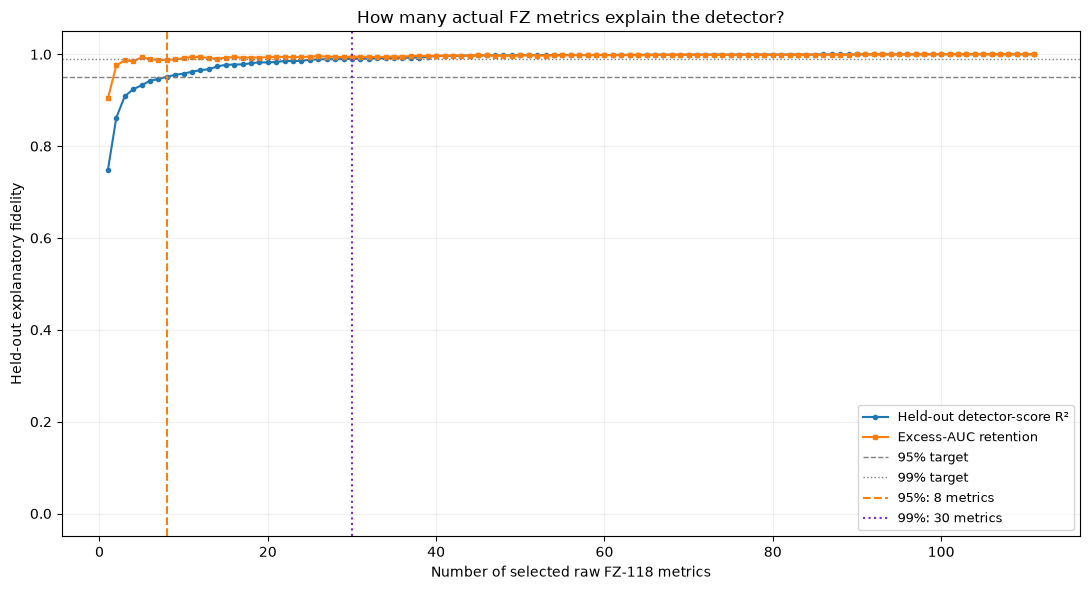


saved: ../results/causal/C02d_fz118_neutralization/fz118_raw_metric_explanation_curve.png
PASS: raw-metric explanation analysis complete.


In [42]:
# ============================================================
# FZ-118 — actual raw metrics explaining 95% and 99%
#
# Uses exact per-feature ExtraTrees contributions.
#
# Selection:
#   detector-training split only
#
# Evaluation:
#   untouched detector-validation split
#
# This accounts for redundancy between metrics such as
# characters, words, syllables, and paragraph length.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import rankdata
from sklearn.metrics import (
    r2_score,
    roc_auc_score,
)


# ------------------------------------------------------------
# Check that the contribution analysis has already run
# ------------------------------------------------------------

required_names = [
    "C_train",
    "C_validation",
    "root_probability",
    "y_component_train",
    "y_component_validation",
    "full_validation_probability",
]

missing_names = [
    name
    for name in required_names
    if name not in globals()
]

if missing_names:
    raise RuntimeError(
        "Run the detector-contribution component cell first. "
        f"Missing variables: {missing_names}"
    )


# ------------------------------------------------------------
# Full frozen-detector scores
# ------------------------------------------------------------

full_train_probability = (
    root_probability
    + C_train.sum(axis=1)
)

full_validation_probability = (
    root_probability
    + C_validation.sum(axis=1)
)

full_validation_auc = float(
    roc_auc_score(
        y_component_validation,
        full_validation_probability,
    )
)


# ------------------------------------------------------------
# Standardize contribution columns on detector training
#
# The surrogate uses contribution patterns, not raw magnitudes.
# This prevents high-variance metrics from being selected merely
# because their numerical scale is larger.
# ------------------------------------------------------------

contribution_mean = C_train.mean(
    axis=0
)

contribution_sd = C_train.std(
    axis=0,
    ddof=1,
)

active_feature_indices = np.flatnonzero(
    contribution_sd > 1e-12
)

C_train_standardized = (
    C_train[
        :,
        active_feature_indices
    ]
    - contribution_mean[
        active_feature_indices
    ][None, :]
) / contribution_sd[
    active_feature_indices
][None, :]

C_validation_standardized = (
    C_validation[
        :,
        active_feature_indices
    ]
    - contribution_mean[
        active_feature_indices
    ][None, :]
) / contribution_sd[
    active_feature_indices
][None, :]

train_score_mean = float(
    full_train_probability.mean()
)

train_target_centered = (
    full_train_probability
    - train_score_mean
)


# ------------------------------------------------------------
# Orthogonal forward selection
#
# At each step:
# 1. select the contribution column most correlated with the
#    remaining detector-score residual;
# 2. refit all selected columns jointly;
# 3. evaluate the resulting sparse reconstruction out of sample.
#
# Re-fitting accounts for correlated/redundant metrics.
# ------------------------------------------------------------

selected_active_columns = []
remaining_active_columns = set(
    range(
        len(active_feature_indices)
    )
)

train_residual = (
    train_target_centered.copy()
)

selection_rows = []
validation_predictions = []

previous_validation_r2 = 0.0

for step in range(
    1,
    len(active_feature_indices) + 1,
):
    correlations = np.abs(
        C_train_standardized.T
        @ train_residual
    )

    if selected_active_columns:
        correlations[
            selected_active_columns
        ] = -np.inf

    next_active_column = int(
        np.argmax(correlations)
    )

    if (
        next_active_column
        not in remaining_active_columns
    ):
        break

    selected_active_columns.append(
        next_active_column
    )

    remaining_active_columns.remove(
        next_active_column
    )

    X_train_selected = (
        C_train_standardized[
            :,
            selected_active_columns
        ]
    )

    coefficients, *_ = np.linalg.lstsq(
        X_train_selected,
        train_target_centered,
        rcond=None,
    )

    reconstructed_train_centered = (
        X_train_selected
        @ coefficients
    )

    train_residual = (
        train_target_centered
        - reconstructed_train_centered
    )

    reconstructed_validation = (
        train_score_mean
        + C_validation_standardized[
            :,
            selected_active_columns
        ]
        @ coefficients
    )

    validation_predictions.append(
        reconstructed_validation
    )

    validation_r2 = float(
        r2_score(
            full_validation_probability,
            reconstructed_validation,
        )
    )

    validation_auc = float(
        roc_auc_score(
            y_component_validation,
            reconstructed_validation,
        )
    )

    excess_auc_retention = float(
        (
            validation_auc - 0.5
        )
        / max(
            full_validation_auc - 0.5,
            1e-12,
        )
    )

    original_feature_index = int(
        active_feature_indices[
            next_active_column
        ]
    )

    selection_rows.append({
        "selection_order":
            step,
        "feature_index":
            original_feature_index,
        "feature":
            FEATURE_NAMES[
                original_feature_index
            ],
        "heldout_score_r2":
            validation_r2,
        "heldout_score_r2_gain":
            (
                validation_r2
                - previous_validation_r2
            ),
        "heldout_auc":
            validation_auc,
        "excess_auc_retention":
            excess_auc_retention,
        "train_residual_sd":
            float(
                train_residual.std(
                    ddof=1
                )
            ),
    })

    previous_validation_r2 = (
        validation_r2
    )

metric_explanation_path = pd.DataFrame(
    selection_rows
)


# ------------------------------------------------------------
# Find the smallest held-out 95% and 99% subsets
# ------------------------------------------------------------

def first_joint_threshold(
    table,
    threshold,
):
    passing = table[
        table[
            "heldout_score_r2"
        ].ge(threshold)
        & table[
            "excess_auc_retention"
        ].ge(threshold)
    ]

    if len(passing):
        return int(
            passing.iloc[0][
                "selection_order"
            ]
        )

    return int(
        table[
            "selection_order"
        ].max()
    )


N_METRICS_95 = first_joint_threshold(
    metric_explanation_path,
    0.95,
)

N_METRICS_99 = first_joint_threshold(
    metric_explanation_path,
    0.99,
)

print(
    "Raw metrics required for 95% explanation:",
    N_METRICS_95,
)

print(
    "Raw metrics required for 99% explanation:",
    N_METRICS_99,
)

print(
    "Full held-out FZ-118 AUC:",
    round(
        full_validation_auc,
        5,
    ),
)


# ------------------------------------------------------------
# Feature-block lookup
# ------------------------------------------------------------

feature_block_lookup = {}

for block_name, indices in FEATURE_BLOCKS.items():
    for feature_index in indices:
        feature_block_lookup[
            int(feature_index)
        ] = block_name


# ------------------------------------------------------------
# Additional interpretability statistics
# ------------------------------------------------------------

def spearman_vector(
    x,
    y,
):
    x_rank = rankdata(
        np.asarray(
            x,
            dtype=float,
        )
    )

    y_rank = rankdata(
        np.asarray(
            y,
            dtype=float,
        )
    )

    x_sd = x_rank.std(
        ddof=1
    )

    y_sd = y_rank.std(
        ddof=1
    )

    if x_sd <= 1e-12 or y_sd <= 1e-12:
        return 0.0

    return float(
        np.corrcoef(
            x_rank,
            y_rank,
        )[0, 1]
    )


raw_train_features = (
    component_train[
        FEATURE_NAMES
    ].to_numpy(float)
)


# Fit final 95% and 99% sparse models so their coefficients
# can be reported. Coefficients refer to standardized exact
# contribution columns, not raw feature units.
def fit_sparse_level(
    n_selected,
):
    active_columns = (
        selected_active_columns[
            :n_selected
        ]
    )

    coefficients, *_ = np.linalg.lstsq(
        C_train_standardized[
            :,
            active_columns
        ],
        train_target_centered,
        rcond=None,
    )

    original_indices = [
        int(
            active_feature_indices[
                active_column
            ]
        )
        for active_column
        in active_columns
    ]

    return (
        original_indices,
        coefficients,
    )


indices_95, coefficients_95 = (
    fit_sparse_level(
        N_METRICS_95
    )
)

indices_99, coefficients_99 = (
    fit_sparse_level(
        N_METRICS_99
    )
)

coefficient_95_lookup = dict(
    zip(
        indices_95,
        coefficients_95,
    )
)

coefficient_99_lookup = dict(
    zip(
        indices_99,
        coefficients_99,
    )
)


# ------------------------------------------------------------
# Complete selected-metric table through the 99% cutoff
# ------------------------------------------------------------

selected_metric_rows = []

for row in (
    metric_explanation_path[
        metric_explanation_path[
            "selection_order"
        ].le(N_METRICS_99)
    ]
    .itertuples(index=False)
):
    feature_index = int(
        row.feature_index
    )

    human_values = raw_train_features[
        y_component_train == 0,
        feature_index,
    ]

    ai_values = raw_train_features[
        y_component_train == 1,
        feature_index,
    ]

    human_feature_sd = max(
        float(
            human_values.std(
                ddof=1
            )
        ),
        1e-12,
    )

    ai_minus_human_sd = float(
        (
            ai_values.mean()
            - human_values.mean()
        )
        / human_feature_sd
    )

    raw_score_correlation = (
        spearman_vector(
            raw_train_features[
                :,
                feature_index,
            ],
            full_train_probability,
        )
    )

    contribution_score_correlation = (
        spearman_vector(
            C_train[
                :,
                feature_index,
            ],
            full_train_probability,
        )
    )

    if row.selection_order <= N_METRICS_95:
        explanation_band = (
            "needed_for_95_percent"
        )
    else:
        explanation_band = (
            "additional_for_99_percent"
        )

    selected_metric_rows.append({
        "selection_order":
            int(
                row.selection_order
            ),
        "explanation_band":
            explanation_band,
        "feature_index":
            feature_index,
        "feature":
            row.feature,
        "feature_block":
            feature_block_lookup.get(
                feature_index,
                "unknown",
            ),
        "ai_minus_human_sd":
            ai_minus_human_sd,
        "raw_metric_spearman_with_detector":
            raw_score_correlation,
        "exact_contribution_spearman_with_detector":
            contribution_score_correlation,
        "surrogate_coefficient_at_95":
            coefficient_95_lookup.get(
                feature_index,
                np.nan,
            ),
        "surrogate_coefficient_at_99":
            coefficient_99_lookup.get(
                feature_index,
                np.nan,
            ),
        "heldout_score_r2_after_addition":
            float(
                row.heldout_score_r2
            ),
        "heldout_score_r2_gain":
            float(
                row.heldout_score_r2_gain
            ),
        "heldout_auc_after_addition":
            float(
                row.heldout_auc
            ),
        "excess_auc_retention_after_addition":
            float(
                row.excess_auc_retention
            ),
    })

selected_metric_explanation = (
    pd.DataFrame(
        selected_metric_rows
    )
)


# ------------------------------------------------------------
# Display exact 95% and additional 99% metric sets
# ------------------------------------------------------------

metrics_95 = (
    selected_metric_explanation[
        selected_metric_explanation[
            "selection_order"
        ].le(N_METRICS_95)
    ]
)

metrics_99_additional = (
    selected_metric_explanation[
        selected_metric_explanation[
            "selection_order"
        ].gt(N_METRICS_95)
    ]
)

print(
    "\nACTUAL RAW METRICS NEEDED FOR 95% EXPLANATION"
)

display(
    metrics_95.round(4)
)

print(
    "\nADDITIONAL RAW METRICS NEEDED TO REACH 99%"
)

if len(metrics_99_additional):
    display(
        metrics_99_additional.round(4)
    )
else:
    print(
        "The 95% set already satisfies the 99% criterion."
    )


# ------------------------------------------------------------
# Block composition at each cutoff
# ------------------------------------------------------------

block_composition_rows = []

for level_name, level_table in [
    ("95_percent", metrics_95),
    (
        "99_percent",
        selected_metric_explanation,
    ),
]:
    counts = (
        level_table[
            "feature_block"
        ]
        .value_counts()
    )

    for block_name, count in counts.items():
        block_composition_rows.append({
            "explanation_level":
                level_name,
            "feature_block":
                block_name,
            "n_selected_metrics":
                int(count),
            "fraction_of_selected_metrics":
                float(
                    count
                    / len(level_table)
                ),
        })

block_composition = (
    pd.DataFrame(
        block_composition_rows
    )
)

print(
    "\nFEATURE-BLOCK COMPOSITION"
)

display(
    block_composition.sort_values(
        [
            "explanation_level",
            "n_selected_metrics",
        ],
        ascending=[
            True,
            False,
        ],
    ).round(4)
)


# ------------------------------------------------------------
# Compact cutoff summary
# ------------------------------------------------------------

cutoff_rows = []

for level, n_metrics in [
    ("95_percent", N_METRICS_95),
    ("99_percent", N_METRICS_99),
]:
    cutoff_row = (
        metric_explanation_path[
            metric_explanation_path[
                "selection_order"
            ].eq(n_metrics)
        ]
        .iloc[0]
    )

    cutoff_rows.append({
        "target":
            level,
        "n_raw_metrics":
            n_metrics,
        "heldout_score_r2":
            float(
                cutoff_row[
                    "heldout_score_r2"
                ]
            ),
        "heldout_auc":
            float(
                cutoff_row[
                    "heldout_auc"
                ]
            ),
        "excess_auc_retention":
            float(
                cutoff_row[
                    "excess_auc_retention"
                ]
            ),
    })

raw_metric_cutoff_summary = pd.DataFrame(
    cutoff_rows
)

print(
    "\nCUTOFF SUMMARY"
)

display(
    raw_metric_cutoff_summary.round(5)
)


# ------------------------------------------------------------
# Fidelity curve
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(11, 6)
)

ax.plot(
    metric_explanation_path[
        "selection_order"
    ],
    metric_explanation_path[
        "heldout_score_r2"
    ],
    marker="o",
    markersize=3,
    linewidth=1.5,
    label="Held-out detector-score R²",
)

ax.plot(
    metric_explanation_path[
        "selection_order"
    ],
    metric_explanation_path[
        "excess_auc_retention"
    ],
    marker="s",
    markersize=3,
    linewidth=1.5,
    label="Excess-AUC retention",
)

ax.axhline(
    0.95,
    color="gray",
    linestyle="--",
    linewidth=1,
    label="95% target",
)

ax.axhline(
    0.99,
    color="gray",
    linestyle=":",
    linewidth=1,
    label="99% target",
)

ax.axvline(
    N_METRICS_95,
    color="#ff7f0e",
    linestyle="--",
    linewidth=1.5,
    label=f"95%: {N_METRICS_95} metrics",
)

ax.axvline(
    N_METRICS_99,
    color="#7b2cbf",
    linestyle=":",
    linewidth=1.5,
    label=f"99%: {N_METRICS_99} metrics",
)

ax.set_xlabel(
    "Number of selected raw FZ-118 metrics"
)

ax.set_ylabel(
    "Held-out explanatory fidelity"
)

ax.set_title(
    "How many actual FZ metrics explain the detector?"
)

ax.set_ylim(
    min(
        -0.05,
        float(
            metric_explanation_path[
                [
                    "heldout_score_r2",
                    "excess_auc_retention",
                ]
            ].min().min()
        ),
    ),
    1.05,
)

ax.grid(alpha=0.18)
ax.legend(fontsize=9)

fig.tight_layout()

RAW_METRIC_FIGURE_PATH = (
    OUT
    / "fz118_raw_metric_explanation_curve.png"
)

fig.savefig(
    RAW_METRIC_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight",
)

plt.show()


# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

metric_explanation_path.to_csv(
    OUT
    / "fz118_raw_metric_explanation_path.csv",
    index=False,
)

selected_metric_explanation.to_csv(
    OUT
    / "fz118_raw_metrics_through_99_percent.csv",
    index=False,
)

raw_metric_cutoff_summary.to_csv(
    OUT
    / "fz118_raw_metric_cutoff_summary.csv",
    index=False,
)

block_composition.to_csv(
    OUT
    / "fz118_raw_metric_block_composition.csv",
    index=False,
)

print("\nsaved:", RAW_METRIC_FIGURE_PATH)
print(
    "PASS: raw-metric explanation analysis complete."
)

## 12. Apply the frozen controller to confirmation AI

This cell generates only the frozen operator set. It never transforms human text. It refuses to run unless the 100-case calibration gate passed and `ALLOW_CONFIRMATION=True`. Each candidate is checkpointed, so interruption is safe.

In [ ]:
assert ACTIVE_CALIBRATION_N == 100, (
    "Confirmation requires the complete 100-case calibration stage."
)
assert STAGE_PASS, "The 100-case calibration gate did not pass."
assert ALLOW_CONFIRMATION, (
    "Confirmation is locked. Set ALLOW_CONFIRMATION=True only after reviewing "
    "the saved 100-case stage-gate result."
)

CONFIRM_TARGET_PATH = OUT / "fz118_confirmation_targets.parquet"
CONFIRM_BANK_PATH = OUT / "fz118_confirmation_candidate_bank.parquet"

confirmation_ai_features = original_features[
    original_features["fz_role"].eq("confirmation")
    & original_features["label"].eq(1)
].copy()

confirmation_ai_ids = set(confirmation_ai_features["source_id"].astype(str))
for operator in FROZEN_OPERATORS:
    if operator.startswith("external__"):
        raw_operator = operator.removeprefix("external__")
        coverage = set(
            external_candidates.loc[
                external_candidates["operator"].eq(raw_operator),
                "source_id",
            ].astype(str)
        )
        assert confirmation_ai_ids.issubset(coverage), (
            f"External operator {raw_operator!r} passed calibration but does "
            "not yet cover all 400 confirmation AI texts."
        )

if CONFIRM_TARGET_PATH.exists():
    confirmation_targets = pd.read_parquet(CONFIRM_TARGET_PATH)
else:
    confirmation_targets = initial_target_assignment(
        confirmation_ai_features,
        "confirmation-human-prototypes",
    )
    confirmation_targets.to_parquet(CONFIRM_TARGET_PATH, index=False)

if CONFIRM_BANK_PATH.exists():
    confirmation_bank = pd.read_parquet(CONFIRM_BANK_PATH)
else:
    confirmation_bank = pd.DataFrame(columns=[
        "source_id", "pair_id", "operator", "text", "seconds"
    ])

confirmation_bank["source_id"] = confirmation_bank["source_id"].astype(str)
confirmation_bank["operator"] = confirmation_bank["operator"].replace({
    "sr_direct": "qwen_direct",
    "alison_sr_direct": "alison_qwen_direct",
})
confirmation_bank = confirmation_bank.drop_duplicates(
    ["source_id", "operator"],
    keep="last",
).reset_index(drop=True)
confirmation_bank.to_parquet(CONFIRM_BANK_PATH, index=False)
done = set(zip(confirmation_bank["source_id"], confirmation_bank["operator"]))

confirmation_ai = (
    data[data["fz_role"].eq("confirmation") & data["label"].eq(1)]
    .merge(confirmation_targets, on="source_id", validate="one_to_one")
    .merge(
        confirmation_ai_features[["source_id"] + FEATURE_NAMES],
        on="source_id",
        validate="one_to_one",
    )
    .sort_values("source_id")
    .reset_index(drop=True)
)

external_lookup = {
    (str(r.source_id), f"external__{r.operator}"): str(r.text)
    for r in external_candidates.itertuples(index=False)
}

for r in tqdm(confirmation_ai.itertuples(index=False), total=len(confirmation_ai), desc="confirmation candidates"):
    current = np.asarray([getattr(r, name) for name in FEATURE_NAMES], dtype=float)
    target = np.asarray([getattr(r, f"target__{name}") for name in FEATURE_NAMES], dtype=float)
    original = str(r.text)
    alison_text = str(alison_map[str(r.source_id)])

    for operator in FROZEN_OPERATORS:
        if (str(r.source_id), operator) in done:
            continue
        t0 = time.time()
        if operator == "original":
            candidate_text = original
        elif operator == "reflow":
            candidate_text = deterministic_reflow(original, target)
        elif operator == "alison_l15":
            candidate_text = alison_text
        elif operator == "alison_reflow":
            candidate_text = deterministic_reflow(alison_text, target)
        elif operator == "qwen_direct":
            candidate_text = generate_directed_rewrite(original, current, target, str(r.source_id))
        elif operator == "alison_qwen_direct":
            candidate_text = generate_directed_rewrite(alison_text, current, target, str(r.source_id))
        elif operator.startswith("external__"):
            candidate_text = external_lookup[(str(r.source_id), operator)]
        else:
            raise ValueError(f"Unknown frozen operator: {operator}")

        row = pd.DataFrame([{
            "source_id": str(r.source_id),
            "pair_id": int(r.pair_id),
            "operator": operator,
            "text": candidate_text,
            "seconds": float(time.time() - t0),
        }])
        confirmation_bank = pd.concat([confirmation_bank, row], ignore_index=True)
        confirmation_bank.to_parquet(CONFIRM_BANK_PATH, index=False)
        done.add((str(r.source_id), operator))

expected_rows = 400 * len(FROZEN_OPERATORS)
assert len(confirmation_bank) == expected_rows
assert confirmation_bank.groupby("source_id")["operator"].nunique().eq(len(FROZEN_OPERATORS)).all()

del rewriter_model, rewriter_tokenizer
rewriter_model = None
rewriter_tokenizer = None
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("confirmation candidate rows:", len(confirmation_bank))


## 13. Screen, featurize, and select confirmation candidates

In [ ]:
CONFIRM_SEMANTIC_PATH = OUT / "fz118_confirmation_candidate_semantics.parquet"
CONFIRM_FEATURE_PATH = OUT / "fz118_confirmation_candidate_features.parquet"

original_text_map = dict(zip(data["source_id"], data["text"]))

if CONFIRM_SEMANTIC_PATH.exists():
    confirmation_semantics = pd.read_parquet(CONFIRM_SEMANTIC_PATH)
else:
    semantic_model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device=DEVICE)
    original_texts = [original_text_map[sid] for sid in confirmation_bank["source_id"]]
    candidate_texts = confirmation_bank["text"].astype(str).tolist()
    a = semantic_model.encode(original_texts, batch_size=32, normalize_embeddings=True, show_progress_bar=True)
    b = semantic_model.encode(candidate_texts, batch_size=32, normalize_embeddings=True, show_progress_bar=True)
    cosine = (a * b).sum(axis=1)
    rows = []
    for i, r in enumerate(confirmation_bank.itertuples(index=False)):
        original = original_text_map[str(r.source_id)]
        candidate = str(r.text)
        rows.append({
            "source_id": str(r.source_id),
            "operator": str(r.operator),
            "semantic_cosine": float(cosine[i]),
            "lexical_change_fraction": lexical_change_fraction(original, candidate),
            "numbers_preserved": normalized_number_set(original) == normalized_number_set(candidate),
            "nonempty": bool(candidate.strip()),
        })
    confirmation_semantics = pd.DataFrame(rows)
    confirmation_semantics.to_parquet(CONFIRM_SEMANTIC_PATH, index=False)
    del semantic_model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

confirmation_semantics["semantic_valid"] = (
    confirmation_semantics["nonempty"]
    & confirmation_semantics["numbers_preserved"]
    & confirmation_semantics["semantic_cosine"].ge(SEMANTIC_COSINE_FLOOR)
    & confirmation_semantics["lexical_change_fraction"].le(LEXICAL_CHANGE_CEILING)
)

if CONFIRM_FEATURE_PATH.exists():
    confirmation_candidate_features = pd.read_parquet(CONFIRM_FEATURE_PATH)
else:
    rows = []
    for r in tqdm(confirmation_bank.itertuples(index=False), total=len(confirmation_bank), desc="confirmation FZ-118"):
        vector = extract_fz118(r.text)
        row = {"source_id": str(r.source_id), "operator": str(r.operator)}
        row.update(dict(zip(FEATURE_NAMES, vector)))
        rows.append(row)
    confirmation_candidate_features = pd.DataFrame(rows)
    confirmation_candidate_features.to_parquet(CONFIRM_FEATURE_PATH, index=False)

confirmation_candidates = (
    confirmation_bank
    .merge(confirmation_semantics, on=["source_id", "operator"], validate="one_to_one")
    .merge(confirmation_candidate_features, on=["source_id", "operator"], validate="one_to_one")
)

confirmation_prototypes = deterministic_human_prototypes(
    len(confirmation_ai_features),
    "confirmation-human-prototypes",
)

confirmation_selected = select_candidates_alternating(
    confirmation_candidates,
    confirmation_prototypes,
    confirmation_targets,
    FROZEN_OPERATORS,
)

assert len(confirmation_selected) == 400
assert confirmation_selected["semantic_valid"].all()
confirmation_selected.to_parquet(OUT / "fz118_confirmation_selected_pre_bertscore.parquet", index=False)

display(
    confirmation_selected.groupby("operator").agg(
        n=("source_id", "size"),
        mean_target_distance=("target_distance", "mean"),
        mean_cosine=("semantic_cosine", "mean"),
        mean_lexical_change=("lexical_change_fraction", "mean"),
    ).sort_values("n", ascending=False)
)


## 14. Final semantic gate and safe fallback

BERTScore is evaluated only for the 400 selected confirmation candidates. A document below the per-document floor falls back to its original text. The aggregate mean must still exceed 0.90. This fallback is frozen in advance and cannot be adjusted after detector results are seen.

In [ ]:
from bert_score import score as bertscore

BERTSCORE_PATH = OUT / "fz118_confirmation_bertscore.parquet"

if BERTSCORE_PATH.exists():
    bert_df = pd.read_parquet(BERTSCORE_PATH)
else:
    references = [original_text_map[sid] for sid in confirmation_selected["source_id"]]
    candidates = confirmation_selected["text"].astype(str).tolist()
    _, _, f1 = bertscore(
        candidates,
        references,
        lang="en",
        model_type="roberta-large",
        device=DEVICE,
        batch_size=8,
        verbose=True,
    )
    bert_df = pd.DataFrame({
        "source_id": confirmation_selected["source_id"].astype(str),
        "bertscore_f1": f1.cpu().numpy().astype(float),
    })
    bert_df.to_parquet(BERTSCORE_PATH, index=False)

confirmation_selected = confirmation_selected.merge(
    bert_df,
    on="source_id",
    validate="one_to_one",
)

fallback_mask = confirmation_selected["bertscore_f1"].lt(BERTSCORE_DOCUMENT_FLOOR)
print("per-document BERTScore fallbacks:", int(fallback_mask.sum()))

if fallback_mask.any():
    fallback_ids = set(confirmation_selected.loc[fallback_mask, "source_id"])
    original_rows = confirmation_candidates[
        confirmation_candidates["source_id"].isin(fallback_ids)
        & confirmation_candidates["operator"].eq("original")
    ].set_index("source_id")
    for index in confirmation_selected.index[fallback_mask]:
        source_id = confirmation_selected.loc[index, "source_id"]
        for column in confirmation_selected.columns:
            if column in original_rows.columns:
                confirmation_selected.loc[index, column] = original_rows.loc[source_id, column]
        confirmation_selected.loc[index, "operator"] = "original_semantic_fallback"
        confirmation_selected.loc[index, "bertscore_f1"] = 1.0

confirmation_selected.to_parquet(
    OUT / "fz118_confirmation_selected_final.parquet",
    index=False,
)

print("mean final BERTScore:", confirmation_selected["bertscore_f1"].mean())
print("mean lexical change:", confirmation_selected["lexical_change_fraction"].mean())


## 15. Confirmatory neutralization tests

The frozen classifier and four preregistered fresh-probe families are evaluated. Fresh probes use five-fold **pair-grouped out-of-fold predictions** on confirmation data, so every prediction comes from a classifier that did not train on that matched human–AI pair.

The orientation-free separability statistic is:

\[
\mathrm{AUC}_{\mathrm{sep}}=\max(\mathrm{AUC},1-\mathrm{AUC}).
\]

This prevents systematic label reversal from being mistaken for neutralization.

In [ ]:
confirmation_human = original_features[
    original_features["fz_role"].eq("confirmation")
    & original_features["label"].eq(0)
].copy()

transformed_ai = confirmation_selected.copy()
transformed_ai["pair_id"] = transformed_ai["source_id"].map(
    data.set_index("source_id")["pair_id"]
).astype(int)
transformed_ai["label"] = 1
transformed_ai["class_name"] = "chatgpt_transformed"

confirm_eval = pd.concat([
    confirmation_human[["source_id", "pair_id", "label", "class_name"] + FEATURE_NAMES],
    transformed_ai[["source_id", "pair_id", "label", "class_name"] + FEATURE_NAMES],
], ignore_index=True)

assert len(confirm_eval) == 800
assert confirm_eval.groupby("pair_id").size().eq(2).all()

def paired_auc_bootstrap(y, score, groups, n_boot=N_BOOT):
    frame = pd.DataFrame({"y": y, "score": score, "group": groups})
    unique_groups = np.asarray(sorted(frame["group"].unique()))
    by_group = {g: frame[frame["group"].eq(g)] for g in unique_groups}
    rng = np.random.default_rng(SEED)
    values = []
    for _ in range(n_boot):
        sampled = rng.choice(unique_groups, size=len(unique_groups), replace=True)
        d = pd.concat([by_group[g] for g in sampled], ignore_index=True)
        auc = roc_auc_score(d["y"], d["score"])
        values.append(max(auc, 1.0 - auc))
    return np.quantile(values, [0.025, 0.975])

X_confirm = confirm_eval[FEATURE_NAMES].to_numpy(float)
y_confirm = confirm_eval["label"].to_numpy(int)
groups_confirm = confirm_eval["pair_id"].to_numpy(int)

probe_rows = []

frozen_score = frozen_detector.predict_proba(X_confirm)[:, 1]
frozen_auc = roc_auc_score(y_confirm, frozen_score)
frozen_ci = paired_auc_bootstrap(y_confirm, frozen_score, groups_confirm)
probe_rows.append({
    "probe": f"frozen_{FROZEN_DETECTOR_NAME}",
    "auc": frozen_auc,
    "separability_auc": max(frozen_auc, 1.0 - frozen_auc),
    "separability_ci_low": frozen_ci[0],
    "separability_ci_high": frozen_ci[1],
    "passes_auc_gate": bool(frozen_ci[1] <= SEPARABILITY_AUC_CEILING),
})

fresh_probes = {
    "fresh_logistic": Pipeline([
        ("scale", StandardScaler()),
        ("model", LogisticRegression(C=1.0, max_iter=5000, random_state=SEED)),
    ]),
    "fresh_rbf_svm": Pipeline([
        ("scale", StandardScaler()),
        ("model", SVC(C=1.0, gamma="scale", probability=True, random_state=SEED)),
    ]),
    "fresh_extra_trees": ExtraTreesClassifier(
        n_estimators=600, min_samples_leaf=3, max_features="sqrt",
        n_jobs=-1, random_state=SEED,
    ),
    "fresh_hist_gradient_boosting": HistGradientBoostingClassifier(
        learning_rate=0.05, max_iter=300, max_leaf_nodes=15,
        l2_regularization=1.0, random_state=SEED,
    ),
}

group_folds = GroupKFold(n_splits=5)

for probe_name, probe in fresh_probes.items():
    oof = np.full(len(confirm_eval), np.nan, dtype=float)
    for train_indices, test_indices in group_folds.split(X_confirm, y_confirm, groups_confirm):
        fold_probe = clone(probe)
        fold_probe.fit(X_confirm[train_indices], y_confirm[train_indices])
        oof[test_indices] = fold_probe.predict_proba(X_confirm[test_indices])[:, 1]
    assert np.isfinite(oof).all()
    auc = roc_auc_score(y_confirm, oof)
    ci = paired_auc_bootstrap(y_confirm, oof, groups_confirm)
    probe_rows.append({
        "probe": probe_name,
        "auc": auc,
        "separability_auc": max(auc, 1.0 - auc),
        "separability_ci_low": ci[0],
        "separability_ci_high": ci[1],
        "passes_auc_gate": bool(ci[1] <= SEPARABILITY_AUC_CEILING),
    })

probe_summary = pd.DataFrame(probe_rows)
display(probe_summary)
probe_summary.to_csv(OUT / "fz118_confirmation_probe_summary.csv", index=False)


### Coordinate and joint-distribution equivalence

For each coordinate, a paired bootstrap interval for the transformed-AI minus untouched-human mean difference must lie entirely within (pm0.20) detector-training-human SD.

For the joint gate, energy distance in robustly standardized feature space must not exceed the 95th percentile of a human-versus-human bootstrap reference distribution.

In [ ]:
human_by_pair = confirmation_human.set_index("pair_id")[FEATURE_NAMES].sort_index()
ai_by_pair = transformed_ai.set_index("pair_id")[FEATURE_NAMES].sort_index()
assert human_by_pair.index.equals(ai_by_pair.index)

paired_delta_sd = (
    ai_by_pair.to_numpy(float) - human_by_pair.to_numpy(float)
) / np.where(human_sd > 1e-10, human_sd, 1.0)

rng = np.random.default_rng(SEED)
boot_mean_batches = []
for start in range(0, N_BOOT, 100):
    batch_size = min(100, N_BOOT - start)
    indices = rng.integers(
        0,
        len(paired_delta_sd),
        size=(batch_size, len(paired_delta_sd)),
    )
    boot_mean_batches.append(paired_delta_sd[indices].mean(axis=1))
boot_means = np.concatenate(boot_mean_batches, axis=0)
ci_low = np.quantile(boot_means, 0.025, axis=0)
ci_high = np.quantile(boot_means, 0.975, axis=0)
mean_delta = paired_delta_sd.mean(axis=0)

coordinate_summary = pd.DataFrame({
    "feature_index": np.arange(118),
    "feature": FEATURE_NAMES,
    "mean_delta_human_sd": mean_delta,
    "ci_low": ci_low,
    "ci_high": ci_high,
})
coordinate_summary["equivalent_within_0_20_sd"] = (
    coordinate_summary["ci_low"].gt(-COORD_EQUIV_MARGIN_SD)
    & coordinate_summary["ci_high"].lt(COORD_EQUIV_MARGIN_SD)
)
coordinate_summary["absolute_mean_delta_human_sd"] = coordinate_summary[
    "mean_delta_human_sd"
].abs()

display(coordinate_summary.sort_values("absolute_mean_delta_human_sd", ascending=False).head(30))
coordinate_summary.to_csv(OUT / "fz118_coordinate_equivalence.csv", index=False)

def energy_distance_multivariate(X, Y):
    X = np.asarray(X, dtype=float)
    Y = np.asarray(Y, dtype=float)
    return float(
        2.0 * cdist(X, Y).mean()
        - cdist(X, X).mean()
        - cdist(Y, Y).mean()
    )

H_confirm_z = standardized_matrix(human_by_pair.to_numpy(float)) * np.sqrt(coordinate_weights)
A_transform_z = standardized_matrix(ai_by_pair.to_numpy(float)) * np.sqrt(coordinate_weights)
observed_energy = energy_distance_multivariate(H_confirm_z, A_transform_z)

H_pool = original_features[original_features["label"].eq(0)][FEATURE_NAMES].to_numpy(float)
H_pool_z = standardized_matrix(H_pool) * np.sqrt(coordinate_weights)
rng = np.random.default_rng(SEED + 1)
human_human_energy = []
for _ in range(500):
    permutation = rng.permutation(len(H_pool_z))
    left = H_pool_z[permutation[:len(H_confirm_z)]]
    right = H_pool_z[permutation[len(H_confirm_z):2 * len(H_confirm_z)]]
    human_human_energy.append(energy_distance_multivariate(left, right))

human_energy_ceiling = float(np.quantile(human_human_energy, 0.95))
joint_gate_pass = bool(observed_energy <= human_energy_ceiling)

joint_summary = pd.DataFrame([{
    "observed_H_vs_TA_energy": observed_energy,
    "human_vs_human_95pct_ceiling": human_energy_ceiling,
    "passes_joint_gate": joint_gate_pass,
}])
display(joint_summary)
joint_summary.to_csv(OUT / "fz118_joint_equivalence.csv", index=False)


## 16. Gate decision and residual diagnosis

The notebook returns `PASS` only when all preregistered conditions pass simultaneously. If it returns `BLOCKED`, the residual table identifies the exact FZ coordinates and blocks that the next controller revision must address. No later detector rung should begin while this decision remains blocked.

In [ ]:
coordinate_gate_pass = bool(coordinate_summary["equivalent_within_0_20_sd"].all())
probe_gate_pass = bool(probe_summary["passes_auc_gate"].all())
semantic_gate_pass = bool(
    confirmation_selected["bertscore_f1"].mean() >= BERTSCORE_MEAN_FLOOR
    and confirmation_selected["semantic_cosine"].mean() >= SEMANTIC_COSINE_FLOOR
    and confirmation_selected["numbers_preserved"].all()
)

OVERALL_PASS = bool(
    coordinate_gate_pass
    and joint_gate_pass
    and probe_gate_pass
    and semantic_gate_pass
)

feature_to_block = {}
for block, indices in FEATURE_BLOCKS.items():
    for index in indices:
        feature_to_block[index] = block

residuals = coordinate_summary.copy()
residuals["block"] = residuals["feature_index"].map(feature_to_block)
residuals = residuals.sort_values("absolute_mean_delta_human_sd", ascending=False)

block_summary = residuals.groupby("block").agg(
    n_features=("feature", "size"),
    n_equivalent=("equivalent_within_0_20_sd", "sum"),
    mean_absolute_gap_sd=("absolute_mean_delta_human_sd", "mean"),
    max_absolute_gap_sd=("absolute_mean_delta_human_sd", "max"),
).reset_index()
block_summary["fraction_equivalent"] = (
    block_summary["n_equivalent"] / block_summary["n_features"]
)
block_summary = block_summary.sort_values(
    ["fraction_equivalent", "max_absolute_gap_sd"],
    ascending=[True, False],
)

gate_decision = {
    "status": "PASS" if OVERALL_PASS else "BLOCKED",
    "coordinate_gate_pass": coordinate_gate_pass,
    "joint_gate_pass": joint_gate_pass,
    "probe_gate_pass": probe_gate_pass,
    "semantic_gate_pass": semantic_gate_pass,
    "n_equivalent_coordinates": int(coordinate_summary["equivalent_within_0_20_sd"].sum()),
    "n_coordinates": 118,
    "max_fresh_or_frozen_separability_auc_ci_high": float(
        probe_summary["separability_ci_high"].max()
    ),
    "mean_bertscore": float(confirmation_selected["bertscore_f1"].mean()),
    "mean_lexical_change_fraction": float(
        confirmation_selected["lexical_change_fraction"].mean()
    ),
    "frozen_operators": FROZEN_OPERATORS,
}

with open(OUT / "fz118_gate_decision.json", "w") as f:
    json.dump(gate_decision, f, indent=2)

block_summary.to_csv(OUT / "fz118_residual_block_summary.csv", index=False)
residuals.to_csv(OUT / "fz118_residual_features_ranked.csv", index=False)

print(json.dumps(gate_decision, indent=2))
display(block_summary)

if OVERALL_PASS:
    print("\nPASS: FZ-118 is neutralized. The FZ-186 rung may begin.")
else:
    print("\nBLOCKED: FZ-118 is not yet fully neutralized.")
    print("Use the ranked residual feature/block tables to add the next targeted operator.")


In [ ]:
# Compact confirmation figure.
baseline_gap = paired_feature_gap("confirmation").set_index("feature_index")
post_gap = coordinate_summary.set_index("feature_index")

top_indices = (
    pd.concat([
        baseline_gap["absolute_delta_human_sd"],
        post_gap["absolute_mean_delta_human_sd"],
    ], axis=1)
    .max(axis=1)
    .nlargest(20)
    .index
)

labels = [FEATURE_NAMES[i] for i in top_indices]
y = np.arange(len(labels))

fig, axes = plt.subplots(1, 2, figsize=(15, 8), gridspec_kw={"width_ratios": [1.7, 1]})

axes[0].barh(
    y - 0.18,
    baseline_gap.loc[top_indices, "mean_delta_human_sd"],
    height=0.34,
    label="Original A - H",
)
axes[0].barh(
    y + 0.18,
    post_gap.loc[top_indices, "mean_delta_human_sd"],
    height=0.34,
    label="T(A) - H",
)
axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].axvspan(-COORD_EQUIV_MARGIN_SD, COORD_EQUIV_MARGIN_SD, color="green", alpha=0.10)
axes[0].set_yticks(y)
axes[0].set_yticklabels(labels)
axes[0].invert_yaxis()
axes[0].set_xlabel("Mean paired gap (detector-training-human SD)")
axes[0].set_title("Largest FZ-118 coordinate gaps")
axes[0].legend()

axes[1].errorbar(
    probe_summary["separability_auc"],
    np.arange(len(probe_summary)),
    xerr=[
        probe_summary["separability_auc"] - probe_summary["separability_ci_low"],
        probe_summary["separability_ci_high"] - probe_summary["separability_auc"],
    ],
    fmt="o",
)
axes[1].axvline(0.5, color="black", linestyle="--", linewidth=1)
axes[1].axvline(SEPARABILITY_AUC_CEILING, color="red", linestyle=":", linewidth=1)
axes[1].set_yticks(np.arange(len(probe_summary)))
axes[1].set_yticklabels(probe_summary["probe"])
axes[1].set_xlim(0.48, 1.0)
axes[1].set_xlabel("Orientation-free AUROC")
axes[1].set_title("Frozen and fresh FZ-118 probes")

fig.suptitle(f"FZ-118 neutralization: {'PASS' if OVERALL_PASS else 'BLOCKED'}")
fig.tight_layout()
FIG_PATH = OUT / "fz118_neutralization_confirmation.png"
fig.savefig(FIG_PATH, dpi=180, bbox_inches="tight")
plt.show()
print("saved:", FIG_PATH)


## 17. Artifact verification

In [ ]:
required_outputs = {
    "external_candidates": EXTERNAL_CANDIDATES_PATH,
    "split_manifest": OUT / "fz118_split_manifest.json",
    "feature_contract": OUT / "fz118_feature_contract.json",
    "original_features": OUT / "fz118_original_features.parquet",
    "frozen_detector": OUT / "fz118_frozen_detector.pkl",
    "detector_freeze": OUT / "fz118_detector_freeze.json",
    "controller_freeze": OUT / "fz118_controller_freeze.json",
    "confirmation_candidates": OUT / "fz118_confirmation_candidate_bank.parquet",
    "confirmation_selected": OUT / "fz118_confirmation_selected_final.parquet",
    "coordinate_equivalence": OUT / "fz118_coordinate_equivalence.csv",
    "joint_equivalence": OUT / "fz118_joint_equivalence.csv",
    "probe_summary": OUT / "fz118_confirmation_probe_summary.csv",
    "gate_decision": OUT / "fz118_gate_decision.json",
    "residual_blocks": OUT / "fz118_residual_block_summary.csv",
    "residual_features": OUT / "fz118_residual_features_ranked.csv",
    "figure": OUT / "fz118_neutralization_confirmation.png",
}

for name, path in required_outputs.items():
    print(f"{name:28s}", "OK" if path.exists() else "MISSING", "|", path)

assert all(path.exists() for path in required_outputs.values())
print("\nC02d artifacts are complete.")
print("Final status:", gate_decision["status"])
